In [ ]:
# import data manipulation libraries
import pandas as pd
import numpy as np
# import os to access colab virtual environment resources
import os
# import plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


###Mount to Drive

In [ ]:
# import drive to manage connections to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###Read the dataset

In [ ]:
# read train and testing data into pandas dataframe
master_dataset = pd.read_excel("/content/drive/MyDrive/Colab Notebooks/Research - Trends/Dataset_with_Seasonality.xlsx")

In [ ]:
#read the first 5 records
master_dataset.head()

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality
0,Tanzania,2020-08-12,media,censorship,Expression,Tanzania has has silenced media coverage of th...,Tanzania has has silenced media coverage of th...,Election Season
1,South Sudan,2020-07-25,Activist,"Abducted, Killed",Association,Prominent South Sudanese activist Peter Biar A...,https://apnews.com/6fe70274d5f5af7f2d6f03764f8...,General Violation
2,Uganda,2020-08-30,comedians,censorship,Expression,Ugandan comedians fear regulations will destro...,Ugandan comedians fear regulations will destro...,General Violation
3,Burundi,2020-08-11,Unfair trial,Arrest,Other,Three people have been sentenced to 30 years i...,https://twitter.com/ChroniclesRW/status/129426...,General Violation
4,Ethiopia,2020-08-11,Protestors,Killed,Peaceful Assembly,At least 17 people have been killed during dif...,http://addisstandard.com/update-wolaita-people...,Protest Season


###Data Cleaning

In [ ]:
#check the shape of the dataset
master_dataset.shape

(1019, 8)

In [ ]:
#check the dataset information
master_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1019 entries, 0 to 1018
Data columns (total 8 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   Country                                      1016 non-null   object        
 1   Date                                         1019 non-null   datetime64[ns]
 2   Group violated                               849 non-null    object        
 3   Threat                                       808 non-null    object        
 4   Type of violation                            1017 non-null   object        
 5   Description (negative/positive development)  1013 non-null   object        
 6   Link                                         1010 non-null   object        
 7   Seasonality                                  1019 non-null   object        
dtypes: datetime64[ns](1), object(7)
memory usage: 63.8+ KB


In [ ]:
#check for duplicates
master_dataset.duplicated().sum()

20

In [ ]:
#view the duplicates
master_dataset[master_dataset.duplicated()]

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality
107,Ethiopia,2020-10-05,NaN,NaN,General News,Leaders in the northern region of Tigray warn ...,https://www.aljazeera.com/program/inside-story...,Political Crisis
769,NaN,2022-08-23,General,Privacy violations,Freedom of expression,Israeli cyber company Cellebrite sold technolo...,https://www.independent.co.ug/storm-over-ugand...,General Violation
781,Tanzania,2022-09-12,NaN,Censorship,Freedom of association,The Tanzanian government has warned against th...,https://www.africanews.com/2022/09/12/tanzania...,Political Crisis
885,Ethiopia,2023-01-17,Journalists,Arbitrary detention,Expression,In response to news reports that authorities i...,https://allafrica.com/stories/202301200455.html,General Violation
886,Rwanda,2023-01-18,Journalists,Killings,General news,A Rwandan journalist who produced content that...,https://www.theeastafrican.co.ke/tea/news/east...,General Violation
887,Rwanda,2023-01-18,Politician,Judicial harassment,Expression,The conviction of a Rwandan opposition politic...,https://www.hrw.org/news/2023/01/18/politician...,General Violation
899,Ethiopia,2023-02-14,Journalists,Arbitrary detention,Expression,"Tewodros Asfaw, who is also the founder of a Y...",https://allafrica.com/stories/202302160062.html,General Violation
901,Kenya,2023-02-21,Protestors,Suppression of peaceful assembly,Peaceful Assembly,Police tear gas Eric Omondi while protesting o...,https://www.pulselive.co.ke/entertainment/cele...,Protest Season
902,Ethiopia,2023-02-23,Journalaists,"Censorship, arbitrary detention",Expression,Ethiopia suspended Somali-language TV broadcas...,https://rsf.org/en/ethiopia-s-somali-region-15...,Human Rights Crackdown
903,Somalia,2023-02-23,Journalists,Arbitrary detention,Expression,CPJ condemns new arrest of Somali journalist A...,https://cpj.org/2023/02/cpj-condemns-new-arres...,Human Rights Crackdown


The above are not really duplicates so we will not delete them

In [ ]:
#check for missing values
master_dataset.isnull().sum()

,0
Country,3
Date,0
Group violated,170
Threat,211
Type of violation,2
Description (negative/positive development),6
Link,9
Seasonality,0


In [ ]:
#view the empty cells of Threat
master_dataset[master_dataset['Threat'].isnull()]

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality
8,Ethiopia,2020-08-20,Journalist,NaN,Expression,Kenyan journalist Collins Juma Osemo alias Yas...,https://allafrica.com/stories/202008210185.htm...,General Violation
11,Uganda,2020-08-21,minorities,NaN,Association,Human Rights Awareness and Promotion Forum tog...,https://www.kuchutimes.com/2020/08/hrapf-and-t...,Political Crisis
12,Burundi,2020-08-14,NaN,NaN,General News,Burundi wants Belgium and Germany to pay $43 b...,https://www.bnnbloomberg.ca/burundi-demands-43...,General Violation
18,Burundi,2020-08-17,NaN,NaN,General News,"More than a dozen people have been jailed, inc...",https://www.news24.com/news24/africa/news/buru...,Political Crisis
20,Ethiopia,2020-08-29,NaN,NaN,General News,One year after Ethiopian prime minister Abiy A...,https://www.theguardian.com/world/2020/aug/29/...,Protest Season
...,...,...,...,...,...,...,...,...
735,Burundi,2022-05-18,Civilians,NaN,Freedom of association,NaN,https://www.hrw.org/news/2022/05/18/burundi-su...,General Violation
767,Burundi,2022-08-18,General,NaN,General,NaN,https://defenddefenders.org/wp-content/uploads...,General Violation
771,Uganda,2022-08-26,Journalists,NaN,Freedom of expression,NaN,https://hrnjuganda.org/?p=9615,General Violation
819,Djibouti,2022-10-27,General,NaN,General,The International Federation for Human Rights ...,https://www.fidh.org/fr/qui-sommes-nous/la-fed...,Election Season


In [ ]:
master_dataset[master_dataset['Group violated'].isnull()]

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality
6,Uganda,2020-08-26,NaN,killed,General News,Enforcement measures to prevent COVID-19 have ...,Enforcement measures to prevent COVID-19 have ...,Human Rights Crackdown
12,Burundi,2020-08-14,NaN,NaN,General News,Burundi wants Belgium and Germany to pay $43 b...,https://www.bnnbloomberg.ca/burundi-demands-43...,General Violation
18,Burundi,2020-08-17,NaN,NaN,General News,"More than a dozen people have been jailed, inc...",https://www.news24.com/news24/africa/news/buru...,Political Crisis
20,Ethiopia,2020-08-29,NaN,NaN,General News,One year after Ethiopian prime minister Abiy A...,https://www.theguardian.com/world/2020/aug/29/...,Protest Season
21,Kenya,2020-08-27,NaN,NaN,General News,"On 27 August, Kenya celebrated its constitutio...",https://www.aljazeera.com/indepth/opinion/keny...,General Violation
...,...,...,...,...,...,...,...,...
784,Burundi,2022-09-16,NaN,Impunity,General,Burundi must engage more effectively in the ru...,https://news.un.org/en/story/2022/09/1126851,Protest Season
787,Sudan,2022-09-20,NaN,Arbitrary arrest,Freedom of association,At least 109 people are illegally detained by ...,https://sudantribune.com/article264299/,General Violation
794,Somalia,2022-09-28,NaN,Lack of access to information,Journalists,The growing pressure against Somali journalist...,https://twitter.com/sjs_Somalia,General Violation
797,Tanzania,2022-09-30,NaN,Killings,Freedom of association,A regional court on Friday dismissed a case br...,https://www.reuters.com/world/africa/regional-...,General Violation


The values in "Group Violated and Threat" are not really missing they are just labeled 'N/A' so recognised as missing

In [ ]:
master_dataset[master_dataset['Type of violation'].isnull()]

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality
731,NaN,2022-05-03,Journalists,NaN,NaN,NaN,NaN,General Violation
751,Tanzania,2022-06-30,NaN,Legal prosecution,NaN,Maasai pastoralists from northern Tanzania wer...,https://www.africanews.com/2022/06/30/tanzania...,Protest Season


In [ ]:
master_dataset[master_dataset['Country'].isnull()]

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality
731,NaN,2022-05-03,Journalists,NaN,NaN,NaN,NaN,General Violation
768,NaN,2022-08-23,General,Privacy violations,Freedom of expression,Israeli cyber company Cellebrite sold technolo...,https://www.independent.co.ug/storm-over-ugand...,General Violation
769,NaN,2022-08-23,General,Privacy violations,Freedom of expression,Israeli cyber company Cellebrite sold technolo...,https://www.independent.co.ug/storm-over-ugand...,General Violation


In [ ]:
#replace all the missing in column "Threat" to "Not Applicable"
master_dataset['Threat'].fillna('Not Applicable',inplace=True)

#replace all the missing in column "Group violated" to "Not Applicable"
master_dataset['Group violated'].fillna('Not Applicable',inplace=True)

#replace all the missing in column "Group violated" to "Not Applicable"
master_dataset['Country'].fillna('Not Applicable',inplace=True)

#replace all the missing in column "Group violated" to "Not Applicable"
master_dataset['Type of violation'].fillna('Not Applicable',inplace=True)

<ipython-input-16-4cccb1988945>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Threat'].fillna('Not Applicable',inplace=True)
<ipython-input-16-4cccb1988945>:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tr

In [ ]:
#check for missing values
master_dataset.isnull().sum()

,0
Country,0
Date,0
Group violated,0
Threat,0
Type of violation,0
Description (negative/positive development),6
Link,9
Seasonality,0


In [ ]:
#check unique columns in Country
master_dataset['Country'].unique()

array(['Tanzania', 'South Sudan', 'Uganda', 'Burundi', 'Ethiopia',
       'Rwanda', 'Djibouti', 'Kenya', 'Somalia', 'Sudan', 'Eritrea',
       'south Sudan', 'Somali land', 'Not Applicable', 'SouthSudan'],
      dtype=object)

In [ ]:
# Drop rows with missing values in the 'link' column
master_dataset.dropna(subset=['Link'], inplace=True)


In [ ]:
#change "south sudan" and "South Sudan" to SouthSudan
master_dataset['Country'].replace('south Sudan','SouthSudan',inplace=True)
master_dataset['Country'].replace('South Sudan','SouthSudan',inplace=True)

<ipython-input-20-cac6177014b4>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Country'].replace('south Sudan','SouthSudan',inplace=True)
<ipython-input-20-cac6177014b4>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value

In [ ]:
#change "Freedom of peaceful assembly" and "Peaceful Assembly" to SouthSudan
master_dataset['Type of violation'].replace('Freedom of peaceful assembly','Peaceful Assembly',inplace=True)

<ipython-input-21-1a76fbbd5594>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Type of violation'].replace('Freedom of peaceful assembly','Peaceful Assembly',inplace=True)


In [ ]:
#Group violated
master_dataset['Group violated'].replace('journalist','Journalist',inplace=True)
master_dataset['Group violated'].replace('journalists','Journalist',inplace=True)
master_dataset['Group violated'].replace('Journalists','Journalist',inplace=True)
master_dataset['Group violated'].replace('protesters','Protesters',inplace=True)
master_dataset['Group violated'].replace('protestors','Protesters',inplace=True)
master_dataset['Group violated'].replace('Oposition','Opposition',inplace=True)
master_dataset['Group violated'].replace('Opposition leaders','Opposition',inplace=True)
master_dataset['Group violated'].replace('opposition leaders','Opposition',inplace=True)
master_dataset['Group violated'].replace('Opposition politicians','Opposition',inplace=True)
master_dataset['Group violated'].replace('Opposition ','Opposition',inplace=True)
master_dataset['Group violated'].replace('opposition','Opposition',inplace=True)

<ipython-input-22-78aca9df3a22>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Group violated'].replace('journalist','Journalist',inplace=True)
<ipython-input-22-78aca9df3a22>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method

In [ ]:
#Type of violation
master_dataset['Type of violation'].replace('freedom of expression','Expression',inplace=True)
master_dataset['Type of violation'].replace('Freedom of peaceful expression','Expression',inplace=True)
master_dataset['Type of violation'].replace('expression','Expression',inplace=True)
master_dataset['Type of violation'].replace('Freedom of expresssion','Expression',inplace=True)
master_dataset['Type of violation'].replace('Freedom of expression','Expression',inplace=True)
master_dataset['Type of violation'].replace('freeedom of association','Association',inplace=True)
master_dataset['Type of violation'].replace('freedom of association','Association',inplace=True)
master_dataset['Type of violation'].replace('Freeedom of association','Association',inplace=True)
master_dataset['Type of violation'].replace('Freedom of association','Association',inplace=True)
master_dataset['Type of violation'].replace('Freedom of assembly','Peaceful Assembly',inplace=True)
master_dataset['Type of violation'].replace('Peaceful assembly','Peaceful Assembly',inplace=True)
master_dataset['Type of violation'].replace('General news','General',inplace=True)
master_dataset['Type of violation'].replace('General information','General',inplace=True)
master_dataset['Type of violation'].replace('Access to Information','Expression',inplace=True)

<ipython-input-23-c2ecca0da020>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Type of violation'].replace('freedom of expression','Expression',inplace=True)
<ipython-input-23-c2ecca0da020>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing '

In [ ]:
#Threat
master_dataset['Threat'].replace('arbitrary arrest','Arbitrary arrest',inplace=True)
master_dataset['Threat'].replace('aritrary arrest','Arbitrary arrest',inplace=True)
master_dataset['Threat'].replace('Aritrary arrest','Arbitrary arrest',inplace=True)
master_dataset['Threat'].replace('arbitrary detention','Arbitrary detention',inplace=True)


<ipython-input-24-8af8a48d9c77>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Threat'].replace('arbitrary arrest','Arbitrary arrest',inplace=True)
<ipython-input-24-8af8a48d9c77>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].me

In [ ]:
#combine Somalia and Somaliland
master_dataset['Country'].replace('Somali land','Somalia',inplace=True)

<ipython-input-25-e8cf72f13d43>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset['Country'].replace('Somali land','Somalia',inplace=True)


In [ ]:
#check unique columns in Country
master_dataset['Country'].unique()

array(['Tanzania', 'SouthSudan', 'Uganda', 'Burundi', 'Ethiopia',
       'Rwanda', 'Djibouti', 'Kenya', 'Somalia', 'Sudan', 'Eritrea',
       'Not Applicable'], dtype=object)

In [ ]:
#check unique columns in Groups Violated
master_dataset['Group violated'].unique()

array(['media', 'Activist', 'comedians', 'Unfair trial', 'Protestors',
       'lecturer', 'Not Applicable', 'HRD', 'Journalist', 'Bloggers',
       'minorities', 'TV stations', 'Mohamed Abduwahab Nuur',
       'Kizito Mihigo', 'doctors', 'civilians', 'Opposition',
       'Protesters', ' Journalists', 'politician', 'Land defenders',
       'Civilians', 'Women', 'Stella Nyanzi', 'High school students',
       'Refugees', 'Burundian population', 'artist', 'Fouad Youssef Ali',
       'inter-communal violence', 'Jawar Mohammed', 'Oromo', 'Christians',
       'public/media', 'Opposition parties', 'citizens', '5 artists',
       'refugee', 'students', 'migrants', 'Citizens', 'Students',
       'student protesters', 'Muslim minority', 'youth protesters',
       'civilian', 'Cyclists', 'Amnesty International Kenya Chairperson',
       'Opposition party members', 'Aid workers', 'Teachers', 'WHRD',
       'protesting street vendors', 'privacy', 'artists',
       'citizens, opposition', 'girls', '

###Data Exploration

In [ ]:
# Make 'Date'in datetime format
master_dataset['Date'] = pd.to_datetime(master_dataset['Date'])

# Extract the 'Year' from the 'Date'
master_dataset['Year'] = master_dataset['Date'].dt.year

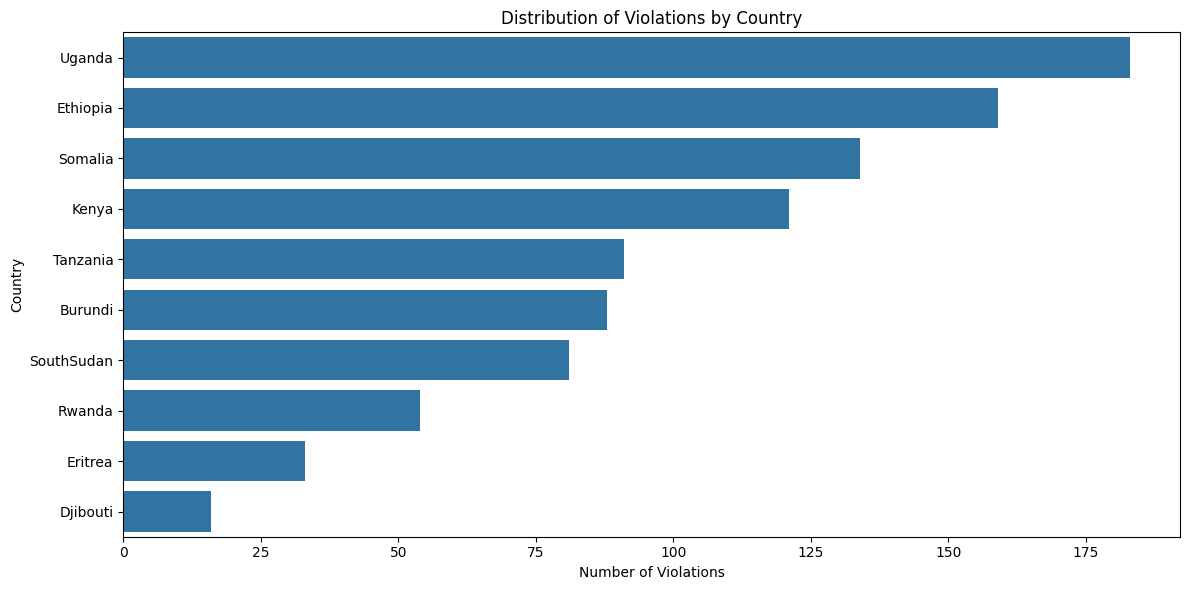

In [ ]:
# Exclude Sudan from the dataset
master_dataset_no_sudan = master_dataset[master_dataset["Country"] != "Sudan"]
master_dataset_no_sudan = master_dataset_no_sudan[master_dataset_no_sudan["Country"] != "Not Applicable"]

# Plot the Distribution of Violations by Country in 2020 (without Sudan)
plt.figure(figsize=(12, 6))
country_plot = sns.countplot(
    y="Country",
    data=master_dataset_no_sudan,
    order=master_dataset_no_sudan["Country"].value_counts().index
)

# Customize the plot
country_plot.set_title("Distribution of Violations by Country")
country_plot.set_xlabel("Number of Violations")
country_plot.set_ylabel("Country")

plt.tight_layout()
plt.show()

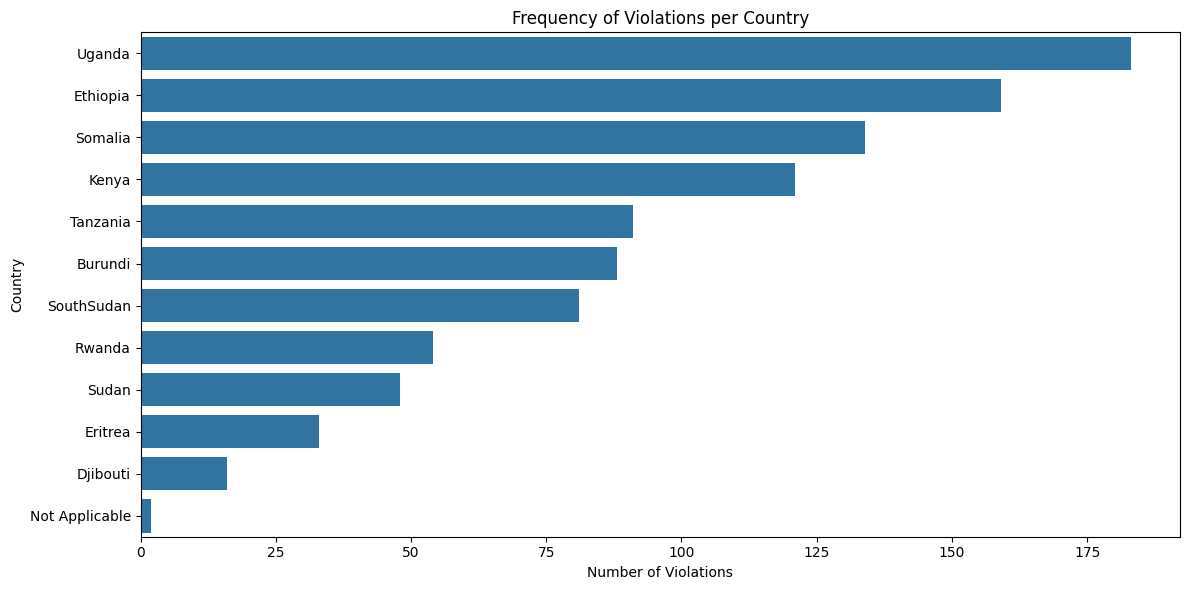

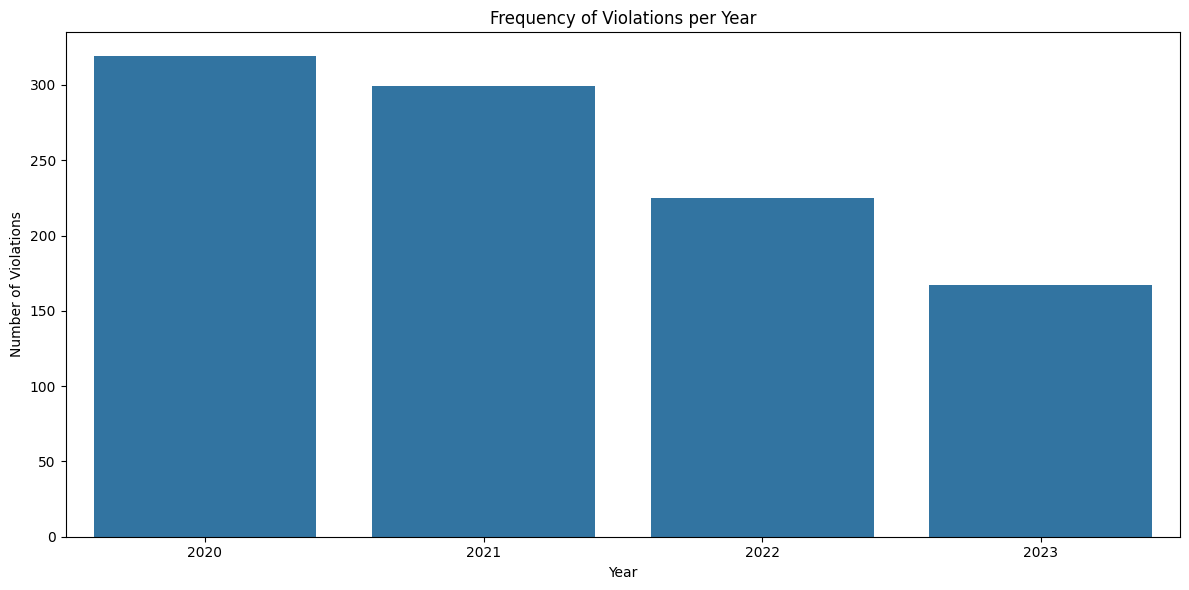

In [ ]:
# Plotting Frequency of Violations per Country
plt.figure(figsize=(12, 6))
country_plot = sns.countplot(y='Country', data=master_dataset, order=master_dataset['Country'].value_counts().index)
country_plot.set_title('Frequency of Violations per Country')
country_plot.set_xlabel('Number of Violations')
country_plot.set_ylabel('Country')
plt.tight_layout()
plt.show()

# Plotting Frequency of Violations per Year
plt.figure(figsize=(12, 6))
year_plot = sns.countplot(x='Year', data=master_dataset, order=master_dataset['Year'].value_counts().index)
year_plot.set_title('Frequency of Violations per Year')
year_plot.set_xlabel('Year')
year_plot.set_ylabel('Number of Violations')
plt.tight_layout()
plt.show()


We see that most violations in the dataset came from Uganda and the year with the most violations was 2020. This could be attributed to the elections that occured that very year.

Let us go further to see what exactly happened per year.

In [ ]:
# prompt: total violations in 2023

# Assuming 'master_dataset' DataFrame is already loaded as in the provided code.

violations_2023 = master_dataset[master_dataset['Year'] == 2023]
total_violations_2023 = len(violations_2023)
print(f"Total violations in 2023: {total_violations_2023}")

Total violations in 2023: 167


In [ ]:
#in master_dataset_with_general include
master_dataset_with_general=master_dataset.copy()

In [ ]:
# Exclude both 'General News' and 'Other' from the 'Type of violation' and 'Not Applicable' from 'Group Violated'
master_dataset = master_dataset[
    ~master_dataset['Type of violation'].isin(['General News', 'Other']) &
    (master_dataset['Group violated'] != 'Not Applicable')&
    (master_dataset['Threat'] != 'Not Applicable')
]

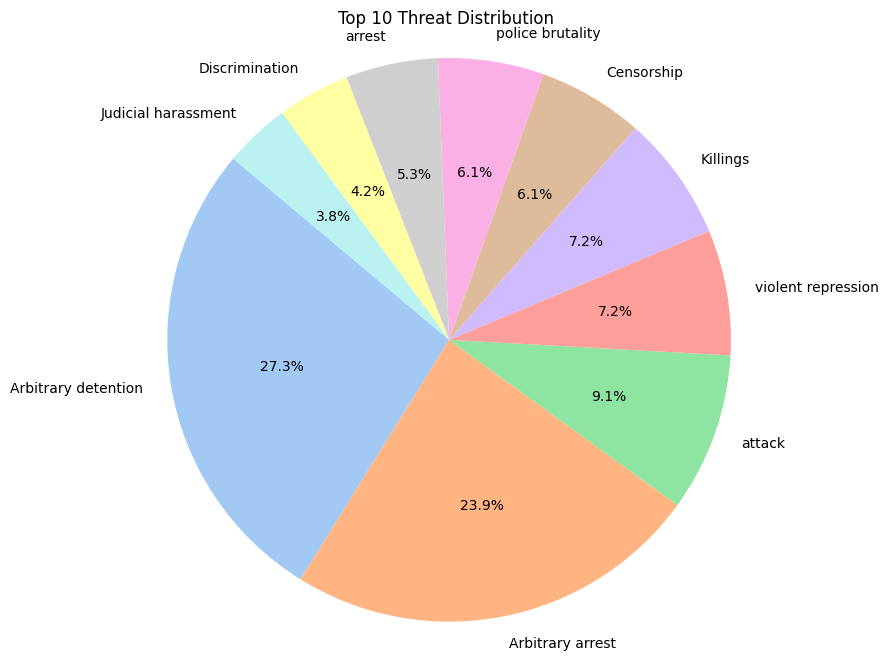

In [ ]:
# Get the top 10 threats based on the number of occurrences
top_10_threats = master_dataset['Threat'].value_counts().nlargest(10)

# Pie chart for the Top 10 Threat distribution in 2020
plt.figure(figsize=(8, 8))
plt.pie(top_10_threats, labels=top_10_threats.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Top 10 Threat Distribution ')
plt.axis('equal')  # Equal aspect ratio ensures that the pie is drawn as a circle.
plt.show()

#**2020**

In [ ]:
# Filter data for the year 2020
data_2020 = master_dataset[master_dataset['Year'] == 2020]

# Exclude both 'General News' and 'Other' from the 'Type of violation' and 'Not Applicable' from 'Group Violated'
filtered_data_2020 = data_2020[
    ~data_2020['Type of violation'].isin(['General News', 'Other']) &
    (data_2020['Group violated'] != 'Not Applicable')&
    (data_2020['Threat'] != 'Not Applicable')
]

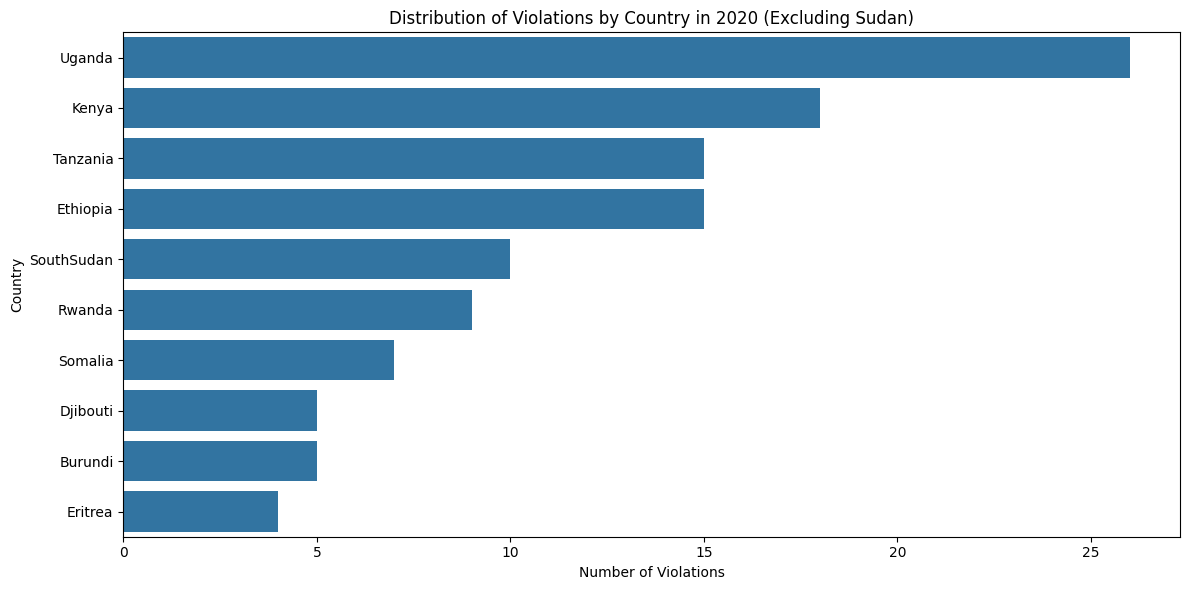

In [ ]:
# Exclude Sudan from the dataset
filtered_data_2020_no_sudan = filtered_data_2020[filtered_data_2020["Country"] != "Sudan"]

# Plot the Distribution of Violations by Country in 2020 (without Sudan)
plt.figure(figsize=(12, 6))
country_plot_2020 = sns.countplot(
    y="Country",
    data=filtered_data_2020_no_sudan,
    order=filtered_data_2020_no_sudan["Country"].value_counts().index
)

# Customize the plot
country_plot_2020.set_title("Distribution of Violations by Country in 2020 (Excluding Sudan)")
country_plot_2020.set_xlabel("Number of Violations")
country_plot_2020.set_ylabel("Country")

plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# Create a choropleth map for Country Distribution in 2020, filtered for African countries
country_counts_2020 = filtered_data_2020_no_sudan['Country'].value_counts().reset_index()
country_counts_2020.columns = ['Country', 'Violations']

# Plotting the Choropleth Map focusing on Africa
fig = px.choropleth(
    country_counts_2020,
    locations='Country',
    locationmode='country names',
    color='Violations',
    color_continuous_scale='Reds',
    title='Distribution of Violations by Country in Africa (2020)',
    scope='africa'  # Focuses the map on Africa
)

fig.show()

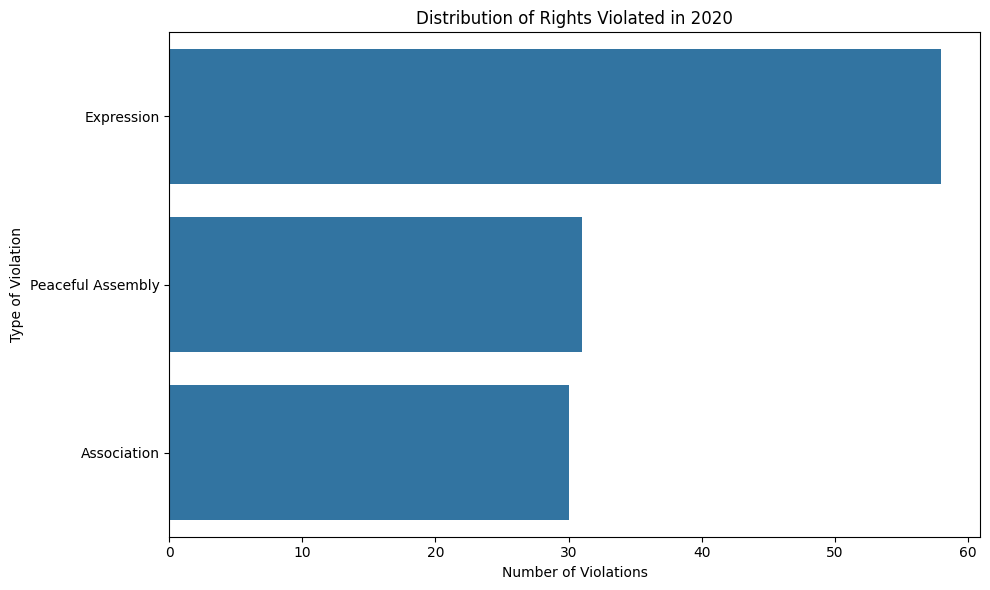

In [ ]:
# Plotting the Distribution of Rights Violated in 2020
plt.figure(figsize=(10, 6))
rights_plot = sns.countplot(y='Type of violation', data=filtered_data_2020, order=filtered_data_2020['Type of violation'].value_counts().index)
rights_plot.set_title('Distribution of Rights Violated in 2020')
rights_plot.set_xlabel('Number of Violations')
rights_plot.set_ylabel('Type of Violation')
plt.tight_layout()
plt.show()

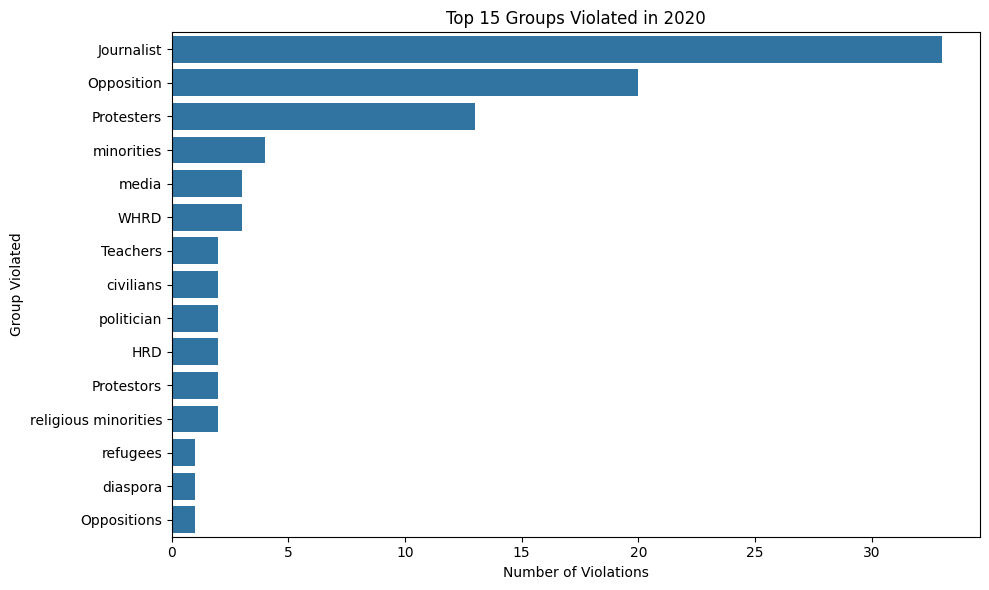

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2020['Group violated'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2020
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Group violated',
    data=filtered_data_2020,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Groups Violated in 2020')
group_plot.set_xlabel('Number of Violations')
group_plot.set_ylabel('Group Violated')
plt.tight_layout()
plt.show()

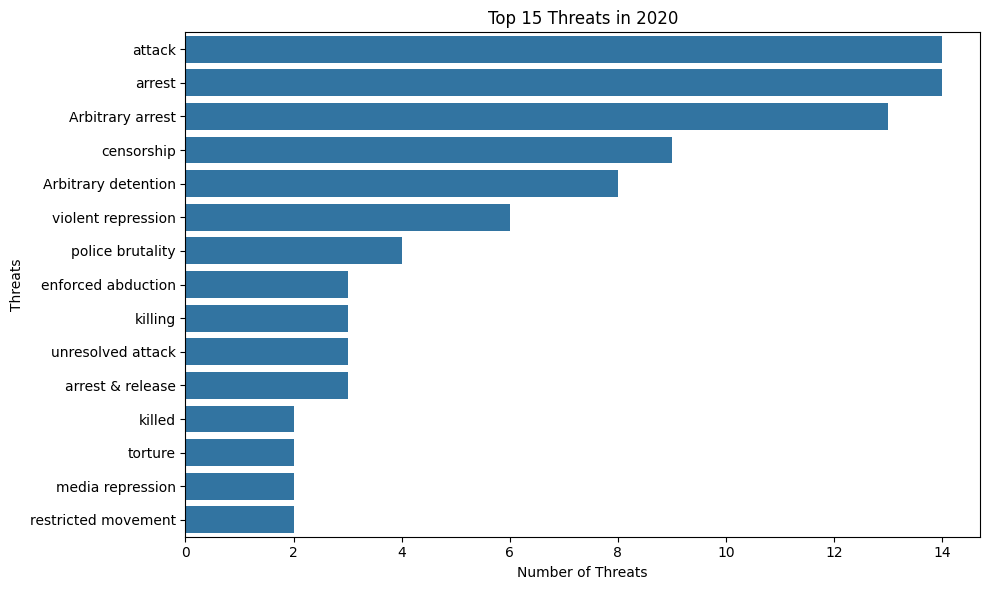

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2020['Threat'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2020
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Threat',
    data=filtered_data_2020,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Threats in 2020')
group_plot.set_xlabel('Number of Threats')
group_plot.set_ylabel('Threats')
plt.tight_layout()
plt.show()

#2021

In [ ]:
# Filter data for the year 2021
data_2021 = master_dataset[master_dataset['Year'] == 2021]

# Exclude both 'General News' and 'Other' from the 'Type of violation' and 'Not Applicable' from 'Group Violated'
filtered_data_2021 = data_2021[
    ~data_2021['Type of violation'].isin(['General News', 'Other']) &
    (data_2021['Group violated'] != 'Not Applicable')&
    (data_2021['Threat'] != 'Not Applicable')
]

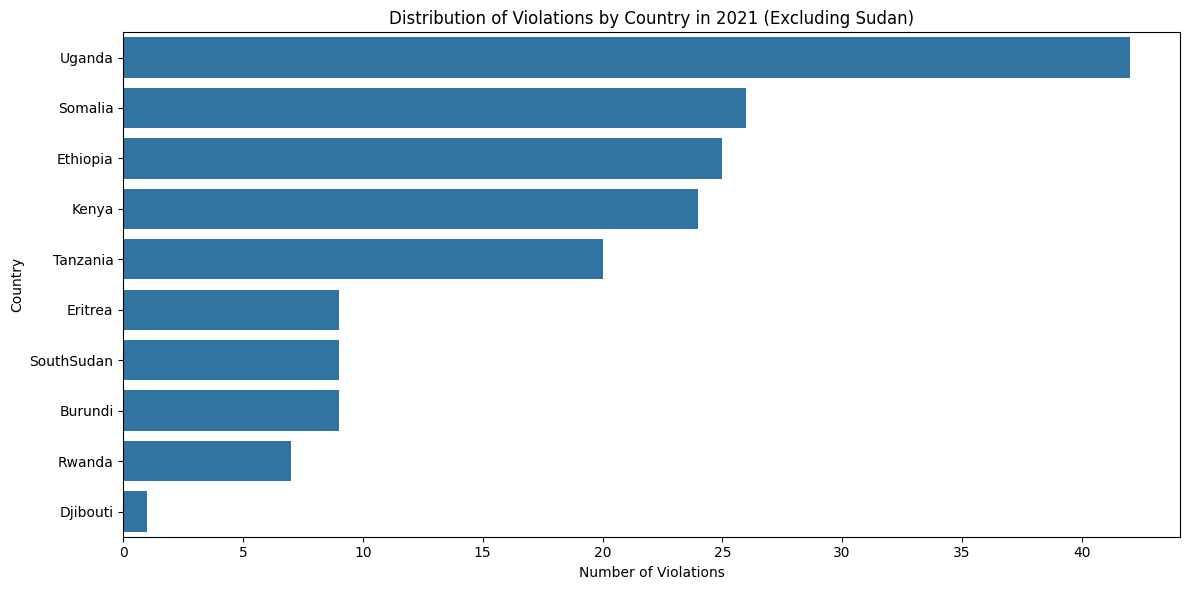

In [ ]:
# Exclude Sudan from the dataset
filtered_data_2021_no_sudan = filtered_data_2021[filtered_data_2021["Country"] != "Sudan"]

# Plot the Distribution of Violations by Country in 2020 (without Sudan)
plt.figure(figsize=(12, 6))
country_plot_2021 = sns.countplot(
    y="Country",
    data=filtered_data_2021_no_sudan,
    order=filtered_data_2021_no_sudan["Country"].value_counts().index
)

# Customize the plot
country_plot_2021.set_title("Distribution of Violations by Country in 2021 (Excluding Sudan)")
country_plot_2021.set_xlabel("Number of Violations")
country_plot_2021.set_ylabel("Country")

plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# Create a choropleth map for Country Distribution in 2020, filtered for African countries
country_counts_2021 = filtered_data_2021_no_sudan['Country'].value_counts().reset_index()
country_counts_2021.columns = ['Country', 'Violations']

# Plotting the Choropleth Map focusing on Africa
fig = px.choropleth(
    country_counts_2021,
    locations='Country',
    locationmode='country names',
    color='Violations',
    color_continuous_scale='Reds',
    title='Distribution of Violations by Country in Africa (2020)',
    scope='africa'  # Focuses the map on Africa
)

fig.show()

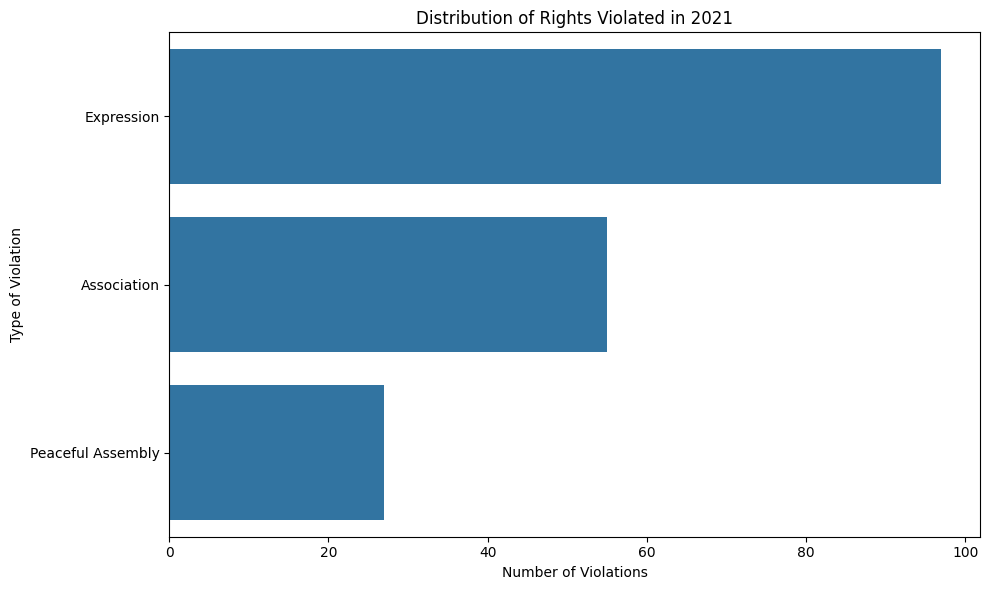

In [ ]:
# Plotting the Distribution of Rights Violated in 2021
plt.figure(figsize=(10, 6))
rights_plot = sns.countplot(y='Type of violation', data=filtered_data_2021, order=filtered_data_2021['Type of violation'].value_counts().index)
rights_plot.set_title('Distribution of Rights Violated in 2021')
rights_plot.set_xlabel('Number of Violations')
rights_plot.set_ylabel('Type of Violation')
plt.tight_layout()
plt.show()

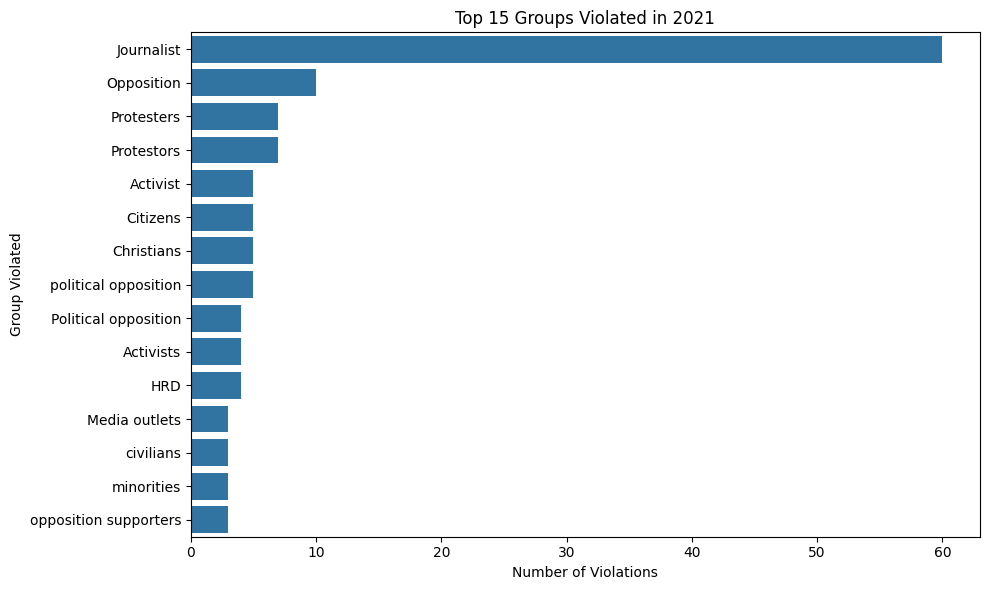

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2021['Group violated'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2021
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Group violated',
    data=filtered_data_2021,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Groups Violated in 2021')
group_plot.set_xlabel('Number of Violations')
group_plot.set_ylabel('Group Violated')
plt.tight_layout()
plt.show()

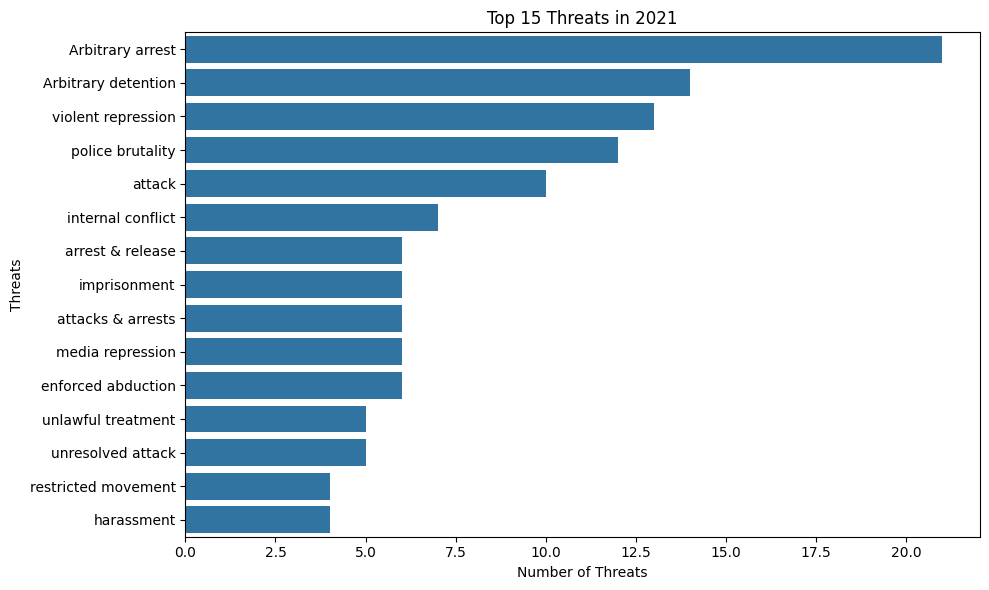

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2021['Threat'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2021
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Threat',
    data=filtered_data_2021,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Threats in 2021')
group_plot.set_xlabel('Number of Threats')
group_plot.set_ylabel('Threats')
plt.tight_layout()
plt.show()

#2022

In [ ]:
# Filter data for the year 2022
data_2022 = master_dataset[master_dataset['Year'] == 2022]

# Exclude both 'General News' and 'Other' from the 'Type of violation' and 'Not Applicable' from 'Group Violated'
filtered_data_2022 = data_2022[
    ~data_2022['Type of violation'].isin(['General News', 'Other','General','General information']) &
    (data_2022['Group violated'] != 'Not Applicable')&
    (data_2022['Threat'] != 'Not Applicable')
]

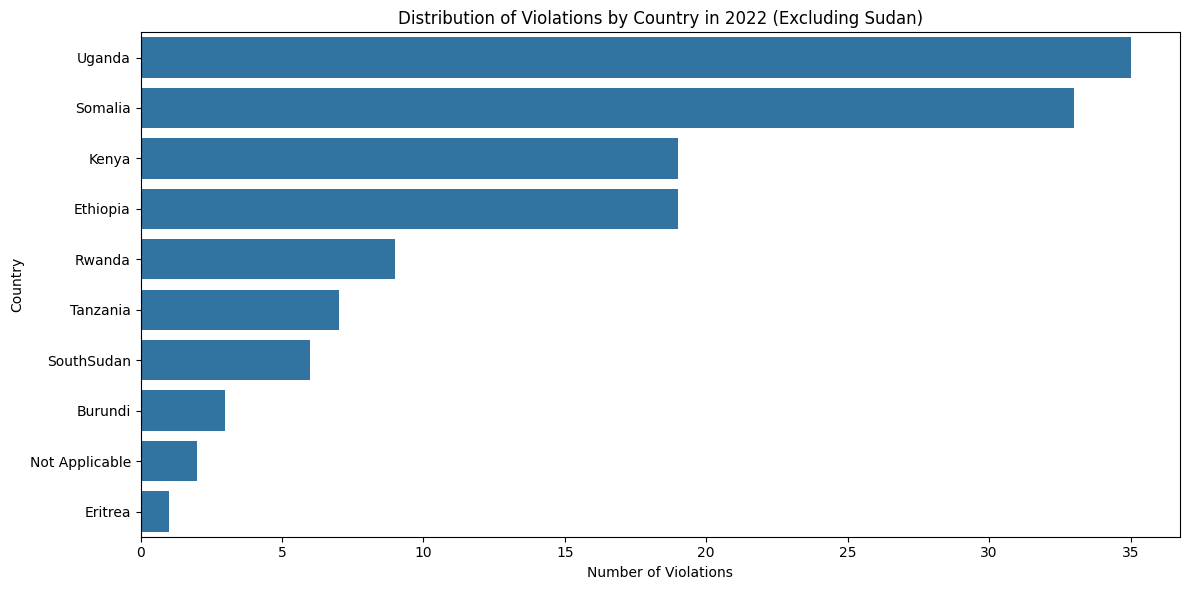

In [ ]:
# Exclude Sudan from the dataset
filtered_data_2022_no_sudan = filtered_data_2022[filtered_data_2022["Country"] != "Sudan"]

# Plot the Distribution of Violations by Country in 2020 (without Sudan)
plt.figure(figsize=(12, 6))
country_plot_2022 = sns.countplot(
    y="Country",
    data=filtered_data_2022_no_sudan,
    order=filtered_data_2022_no_sudan["Country"].value_counts().index
)

# Customize the plot
country_plot_2022.set_title("Distribution of Violations by Country in 2022 (Excluding Sudan)")
country_plot_2022.set_xlabel("Number of Violations")
country_plot_2022.set_ylabel("Country")

plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# Create a choropleth map for Country Distribution in 2020, filtered for African countries
country_counts_2022 = filtered_data_2022_no_sudan['Country'].value_counts().reset_index()
country_counts_2022.columns = ['Country', 'Violations']

# Plotting the Choropleth Map focusing on Africa
fig = px.choropleth(
    country_counts_2022,
    locations='Country',
    locationmode='country names',
    color='Violations',
    color_continuous_scale='Reds',
    title='Distribution of Violations by Country in Africa (2020)',
    scope='africa'  # Focuses the map on Africa
)

fig.show()

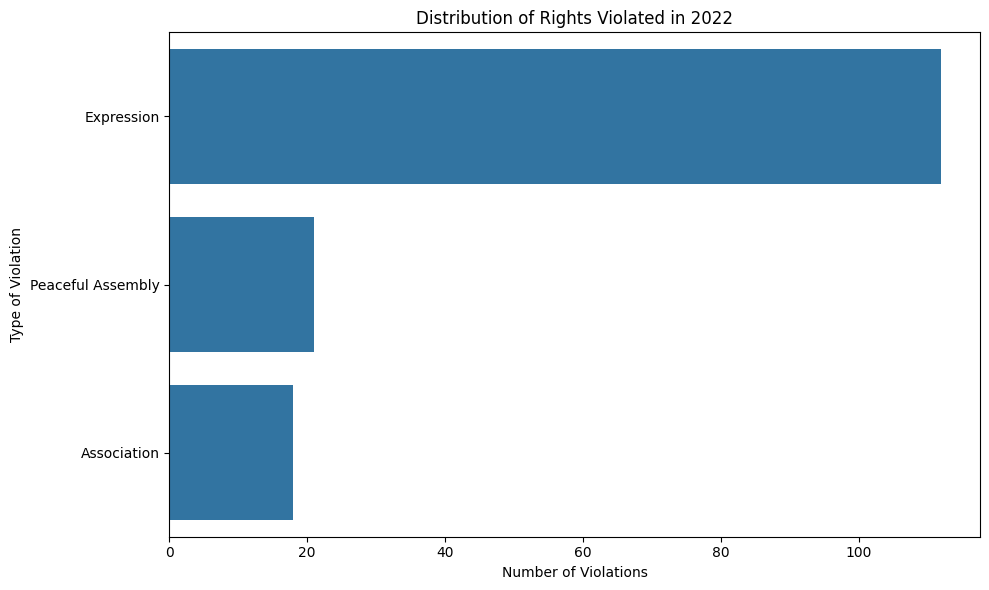

In [ ]:
# Plotting the Distribution of Rights Violated in 2022
plt.figure(figsize=(10, 6))
rights_plot = sns.countplot(y='Type of violation', data=filtered_data_2022, order=filtered_data_2022['Type of violation'].value_counts().index)
rights_plot.set_title('Distribution of Rights Violated in 2022')
rights_plot.set_xlabel('Number of Violations')
rights_plot.set_ylabel('Type of Violation')
plt.tight_layout()
plt.show()

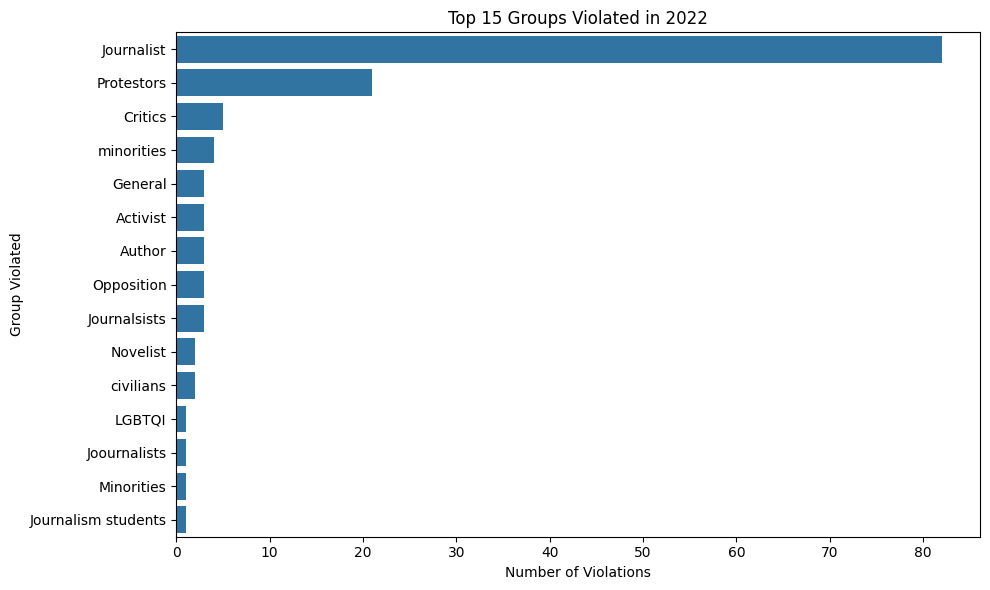

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2022['Group violated'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2022
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Group violated',
    data=filtered_data_2022,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Groups Violated in 2022')
group_plot.set_xlabel('Number of Violations')
group_plot.set_ylabel('Group Violated')
plt.tight_layout()
plt.show()

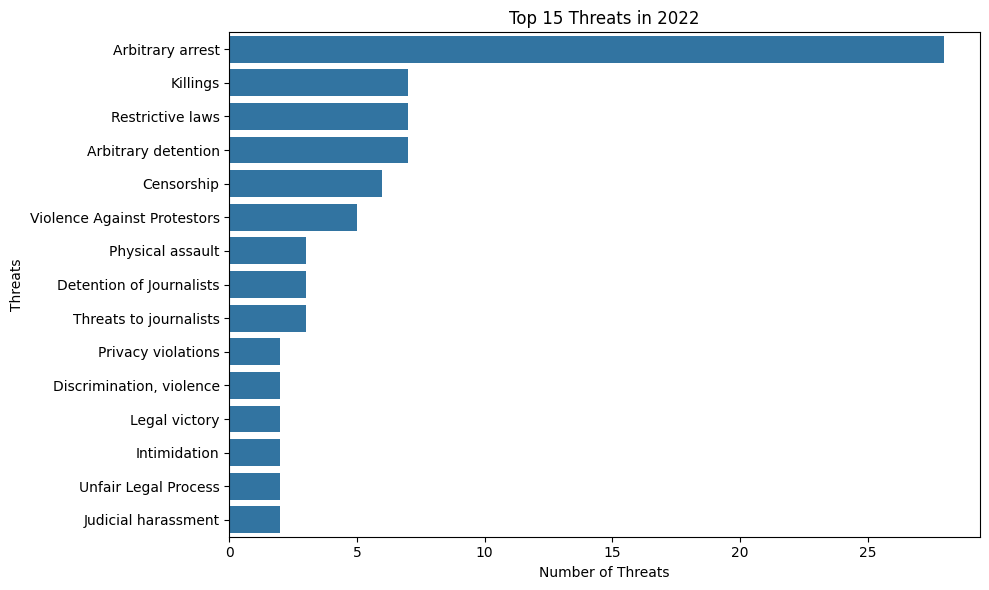

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2022['Threat'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2021
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Threat',
    data=filtered_data_2022,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Threats in 2022')
group_plot.set_xlabel('Number of Threats')
group_plot.set_ylabel('Threats')
plt.tight_layout()
plt.show()

#2023

In [ ]:
# Filter data for the year 2022
data_2023 = master_dataset[master_dataset['Year'] == 2023]

# Exclude both 'General News' and 'Other' from the 'Type of violation' and 'Not Applicable' from 'Group Violated'
filtered_data_2023 = data_2023[
    ~data_2023['Type of violation'].isin(['General News', 'Other']) &
    (data_2023['Group violated'] != 'Not Applicable')&
    (data_2023['Threat'] != 'Not Applicable')
]

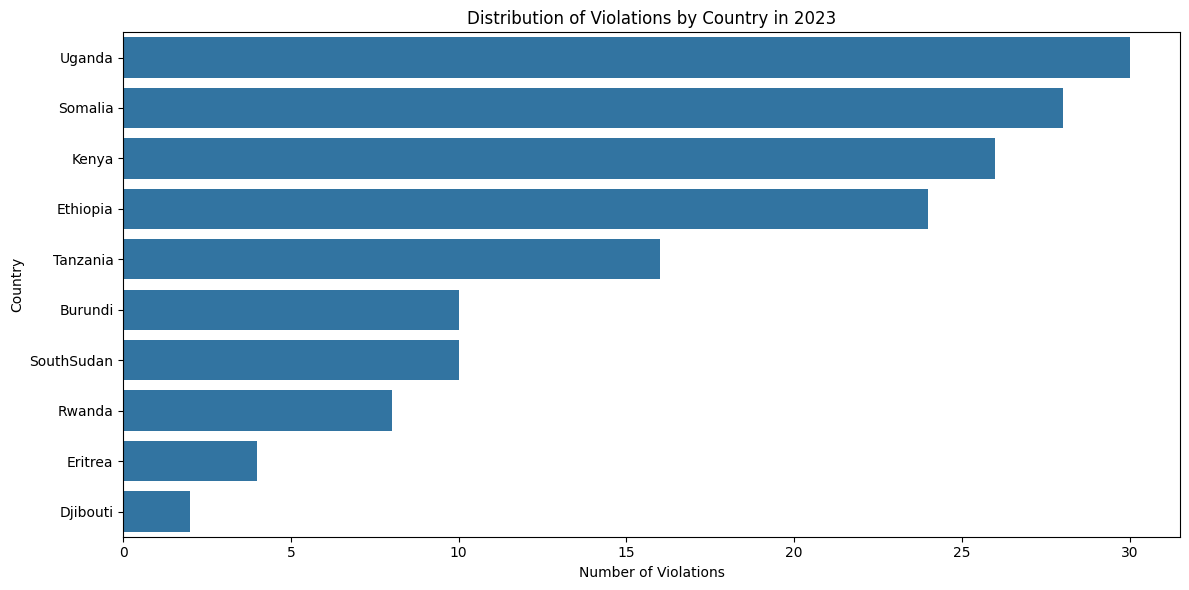

In [ ]:
# Plotting the Distribution of Violations by Country in 2022
plt.figure(figsize=(12, 6))
country_data_2023 = sns.countplot(y='Country', data=filtered_data_2023, order=filtered_data_2023['Country'].value_counts().index)
country_data_2023.set_title('Distribution of Violations by Country in 2023')
country_data_2023.set_xlabel('Number of Violations')
country_data_2023.set_ylabel('Country')
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# Create a choropleth map for Country Distribution in 2022, filtered for African countries
country_counts_2023 = filtered_data_2023['Country'].value_counts().reset_index()
country_counts_2023.columns = ['Country', 'Violations']

# Plotting the Choropleth Map focusing on Africa
fig = px.choropleth(
    country_counts_2023,
    locations='Country',
    locationmode='country names',
    color='Violations',
    color_continuous_scale='Reds',
    title='Distribution of Violations by Country in Africa (2023)',
    scope='africa'  # Focuses the map on Africa
)

fig.show()

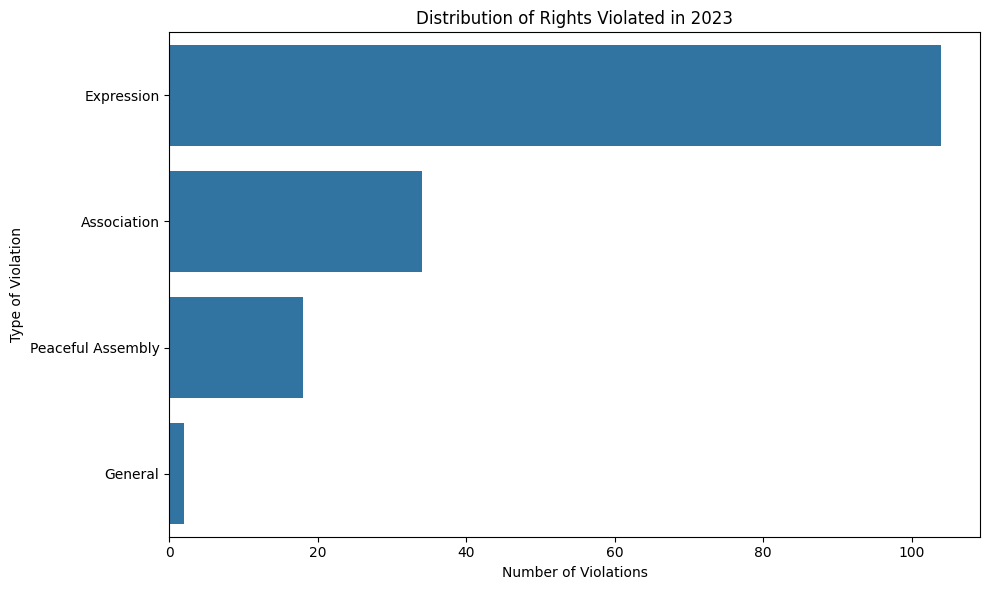

In [ ]:
# Plotting the Distribution of Rights Violated in 2023
plt.figure(figsize=(10, 6))
rights_plot = sns.countplot(y='Type of violation', data=filtered_data_2023, order=filtered_data_2023['Type of violation'].value_counts().index)
rights_plot.set_title('Distribution of Rights Violated in 2023')
rights_plot.set_xlabel('Number of Violations')
rights_plot.set_ylabel('Type of Violation')
plt.tight_layout()
plt.show()

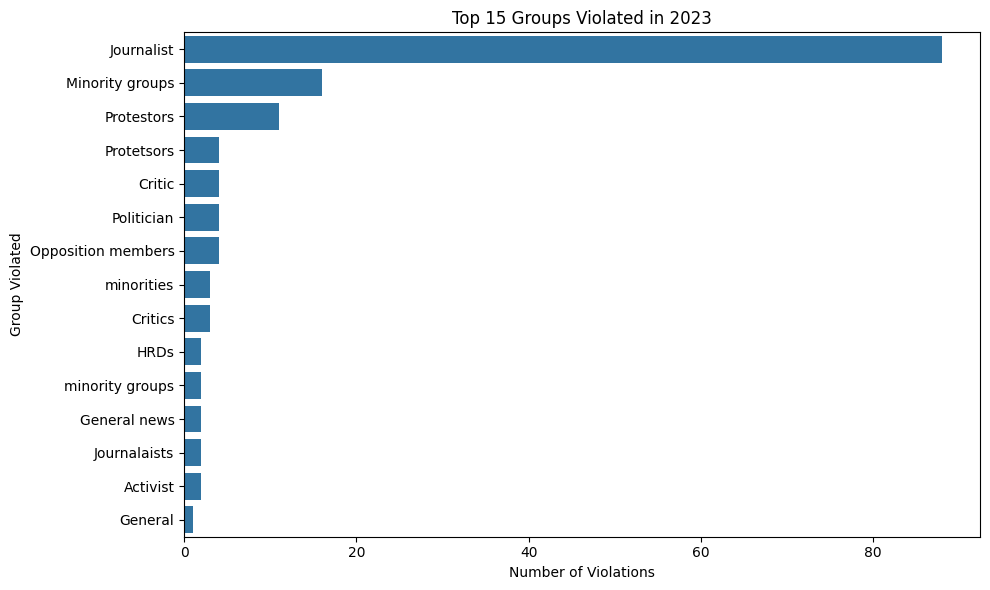

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2023['Group violated'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2022
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Group violated',
    data=filtered_data_2023,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Groups Violated in 2023')
group_plot.set_xlabel('Number of Violations')
group_plot.set_ylabel('Group Violated')
plt.tight_layout()
plt.show()

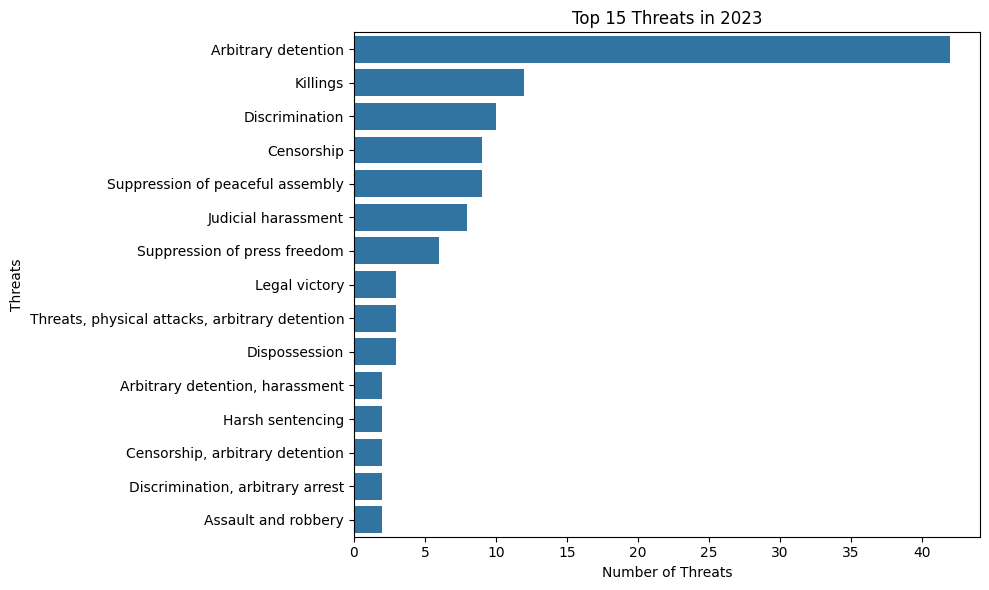

In [ ]:
# Get the top 15 groups based on the number of violations
top_15_groups = filtered_data_2023['Threat'].value_counts().nlargest(15).index

# Plotting the Distribution of the Top 15 Groups Violated in 2021
plt.figure(figsize=(10, 6))
group_plot = sns.countplot(
    y='Threat',
    data=filtered_data_2023,
    order=top_15_groups  # Only plot the top 15 groups
)
group_plot.set_title('Top 15 Threats in 2023')
group_plot.set_xlabel('Number of Threats')
group_plot.set_ylabel('Threats')
plt.tight_layout()
plt.show()

#Clustering countries

In [ ]:
#make a copy of the master dataset
master_dataset_copy = master_dataset.copy()

In [ ]:
# Check if 'Type of violation' column contains complex or nested data
print(master_dataset_copy['Type of violation'].head())  # Display the first few rows to inspect the data
print(master_dataset_copy['Type of violation'].apply(type).value_counts())  # Check the types of data in the column


0           Expression
1          Association
2           Expression
3                Other
4    Peaceful Assembly
Name: Type of violation, dtype: object
Type of violation
<class 'str'>    1010
Name: count, dtype: int64


In [ ]:
# Convert all entries in 'Type of violation' to strings to ensure they are 1-dimensional
master_dataset_copy['Type of violation'] = master_dataset_copy['Type of violation'].astype(str)

# Exclude 'Sudan' and 'Not applicable' from the dataset
master_dataset_copy = master_dataset_copy[~master_dataset_copy['Country'].isin(['Sudan', 'Not Applicable'])]



In [ ]:
# Correct pivot table creation to count the frequency of each type of violation by country
violation_by_country = pd.pivot_table(
    master_dataset_copy,
    index='Country',  # Grouping by 'Country'
    columns='Type of violation',  # Each type of violation becomes a column
    aggfunc='size',  # Count the occurrences
    fill_value=0  # Fill missing values with 0
)

# Display the first few rows of the pivot table
print(violation_by_country)


Type of violation  Association  Expression  General  General News  \
Country                                                             
Burundi                     20          17        6            32   
Djibouti                     2           5        2             6   
Eritrea                     11           9        1             8   
Ethiopia                    20          65        8            39   
Kenya                       19          38        6            10   
Rwanda                       6          26        7            13   
Somalia                      3          99        3            21   
SouthSudan                   5          28        8            26   
Tanzania                    29          32        2            12   
Uganda                      48          77        3            23   

Type of violation  Journalists  Not Applicable  Other  Peaceful Assembly  \
Country                                                                    
Burundi            

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(violation_by_country)

# Convert scaled data back to a DataFrame for easier interpretation
scaled_features_df = pd.DataFrame(scaled_features, index=violation_by_country.index, columns=violation_by_country.columns)


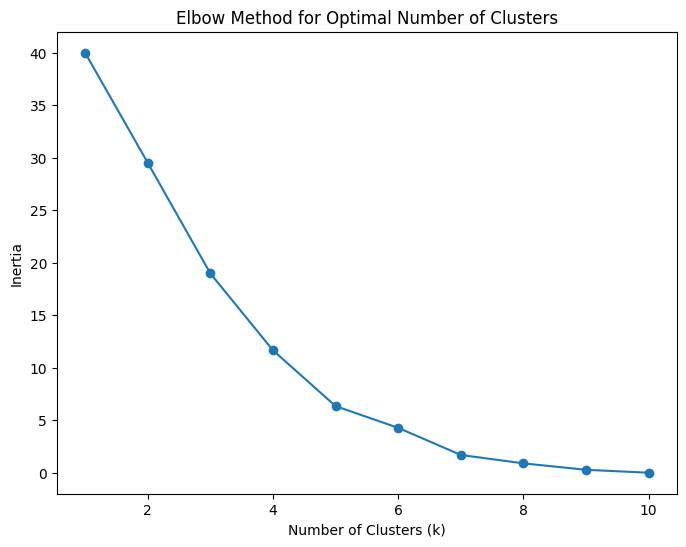

In [ ]:
from sklearn.cluster import KMeans

# Determine the optimal number of clusters using the Elbow Method
inertia = []
k_range = range(1, 11)  # Test for 1 to 10 clusters

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 6))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()

In [ ]:
optimal_k = 5  # Replace with the chosen number of clusters from the Elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(scaled_features)

# Add the cluster labels to the original DataFrame
violation_by_country['Cluster'] = clusters

# Display the first few rows with cluster labels
print(violation_by_country)


Type of violation  Association  Expression  General  Peaceful Assembly  \
Country                                                                  
Burundi                     14          13        2                  0   
Djibouti                     2           5        0                  1   
Eritrea                     10           8        0                  0   
Ethiopia                    17          55        4                 11   
Kenya                       18          36        5                 33   
Rwanda                       6          25        6                  0   
Somalia                      2          89        1                  3   
SouthSudan                   5          25        4                  5   
Tanzania                    21          29        1                  8   
Uganda                      40          71        2                 22   

Type of violation  Cluster  
Country                     
Burundi                  2  
Djibouti                

From the clusters above the cluster 0 is the one with less violations, cluster 2 with medium violations and cluster 3 with the highest violations

In [ ]:
from sklearn.cluster import KMeans

optimal_k = 5  # Replace with the chosen number of clusters from the Elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(scaled_features)

# Add the cluster labels to the original DataFrame
violation_by_country['Cluster'] = clusters

# Display the first few rows with cluster labels
print(violation_by_country)

Type of violation  Association  Expression  General  General News  \
Country                                                             
Burundi                     20          17        6            32   
Djibouti                     2           5        2             6   
Eritrea                     11           9        1             8   
Ethiopia                    20          65        8            39   
Kenya                       19          38        6            10   
Rwanda                       6          26        7            13   
Somalia                      3          99        3            21   
SouthSudan                   5          28        8            26   
Tanzania                    29          32        2            12   
Uganda                      48          77        3            23   

Type of violation  Journalists  Not Applicable  Other  Peaceful Assembly  \
Country                                                                    
Burundi            

In [ ]:
from sklearn.cluster import KMeans

optimal_k = 5  # Replace with the chosen number of clusters from the Elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(scaled_features)

# Add the cluster labels to the original DataFrame
violation_by_country['Cluster'] = clusters

# Display the first few rows with cluster labels
print(violation_by_country)

Type of violation  Association  Expression  General  General News  \
Country                                                             
Burundi                     20          17        6            32   
Djibouti                     2           5        2             6   
Eritrea                     11           9        1             8   
Ethiopia                    20          65        8            39   
Kenya                       19          38        6            10   
Rwanda                       6          26        7            13   
Somalia                      3          99        3            21   
SouthSudan                   5          28        8            26   
Tanzania                    29          32        2            12   
Uganda                      48          77        3            23   

Type of violation  Journalists  Not Applicable  Other  Peaceful Assembly  \
Country                                                                    
Burundi            

In [ ]:
# Print only the Country and Cluster columns
print(violation_by_country[['Cluster']])


Type of violation  Cluster
Country                   
Burundi                  0
Djibouti                 2
Eritrea                  2
Ethiopia                 0
Kenya                    4
Rwanda                   2
Somalia                  1
SouthSudan               0
Tanzania                 3
Uganda                   4


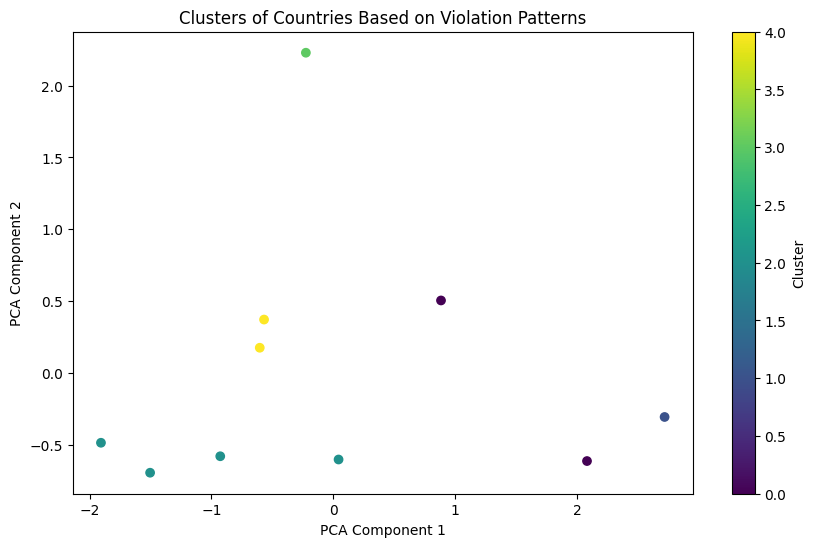

In [ ]:
from sklearn.decomposition import PCA

# Reduce dimensions to 2 for visualization using PCA
pca = PCA(n_components=3)
pca_features = pca.fit_transform(scaled_features)

# Create a scatter plot of the clusters
plt.figure(figsize=(10, 6))
plt.scatter(pca_features[:, 0], pca_features[:, 2], c=clusters, cmap='viridis')
plt.title('Clusters of Countries Based on Violation Patterns')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster')
plt.show()


#Identify the relationship in the clusters

In [ ]:
# Calculate the mean values for each type of violation by cluster
cluster_characteristics_mean = violation_by_country.groupby('Cluster').mean()

# Calculate the median values for each type of violation by cluster
cluster_characteristics_median = violation_by_country.groupby('Cluster').median()

# Display the mean and median values
print("Mean Values for Each Type of Violation by Cluster:")
print(cluster_characteristics_mean)

print("\nMedian Values for Each Type of Violation by Cluster:")
print(cluster_characteristics_median)


Mean Values for Each Type of Violation by Cluster:
Type of violation  Association  Expression  General  Peaceful Assembly
Cluster                                                               
0                        17.50       45.50     4.50              22.00
1                        40.00       71.00     2.00              22.00
2                        11.75       13.75     0.75               2.25
3                         2.00       89.00     1.00               3.00
4                         5.50       25.00     5.00               2.50

Median Values for Each Type of Violation by Cluster:
Type of violation  Association  Expression  General  Peaceful Assembly
Cluster                                                               
0                         17.5        45.5      4.5               22.0
1                         40.0        71.0      2.0               22.0
2                         12.0        10.5      0.5                0.5
3                          2.0        89.0 

In [ ]:
# List countries in each cluster
countries_cluster_0 = violation_by_country[violation_by_country['Cluster'] == 0].index.tolist()
countries_cluster_1 = violation_by_country[violation_by_country['Cluster'] == 1].index.tolist()
countries_cluster_2 = violation_by_country[violation_by_country['Cluster'] == 2].index.tolist()
countries_cluster_3 = violation_by_country[violation_by_country['Cluster'] == 3].index.tolist()
countries_cluster_4 = violation_by_country[violation_by_country['Cluster'] == 4].index.tolist()


# Print the countries in each cluster
print("Countries in Cluster 0:")
print(countries_cluster_0)

print("\nCountries in Cluster 1:")
print(countries_cluster_1)

print("\nCountries in Cluster 2:")
print(countries_cluster_2)

print("\nCountries in Cluster 3:")
print(countries_cluster_3)

print("\nCountries in Cluster 4:")
print(countries_cluster_4)


Countries in Cluster 0:
['Ethiopia', 'Kenya']

Countries in Cluster 1:
['Uganda']

Countries in Cluster 2:
['Burundi', 'Djibouti', 'Eritrea', 'Tanzania']

Countries in Cluster 3:
['Somalia']

Countries in Cluster 4:
['Rwanda', 'SouthSudan']


#Forecasting violations

#SARIMA

In [ ]:
# Aggregate violations per date
time_series_data = master_dataset.groupby("Date").size().reset_index(name="Violation Count")

# Set date as index and ensure regular frequency for SARIMA
time_series_data = time_series_data.set_index("Date").asfreq("D").fillna(0)

Mean Absolute Error (MAE): 0.7443797610658727
Root Mean Squared Error (RMSE): 0.8328043428361671


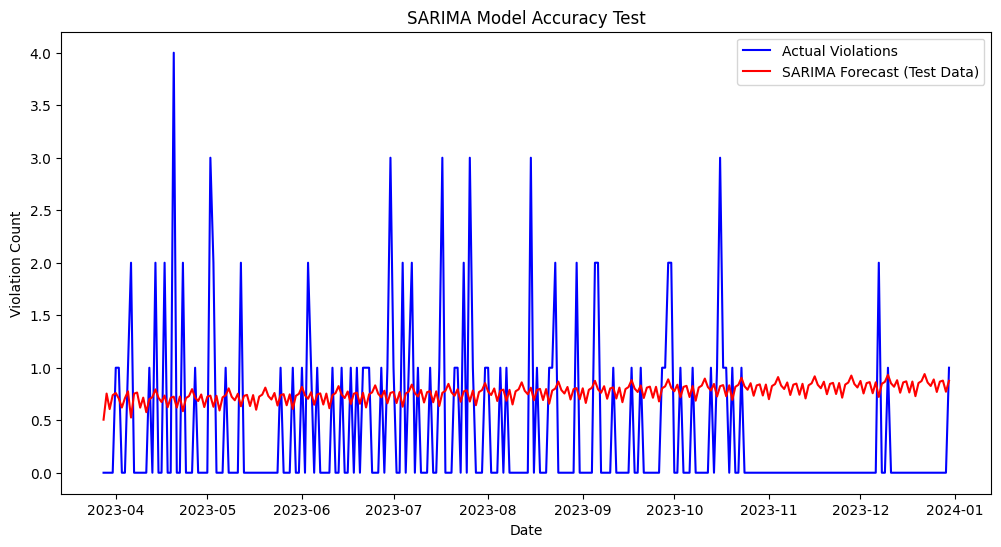

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Split the dataset (80% train, 20% test)
train_size = int(len(time_series_data) * 0.8)
train, test = time_series_data[:train_size], time_series_data[train_size:]

# Fit SARIMA model on training data
sarima_model = SARIMAX(train["Violation Count"],
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 12),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_fit = sarima_model.fit()

# Forecast on the test set
forecast_test = sarima_fit.forecast(steps=len(test))

# Calculate MAE and RMSE
mae = mean_absolute_error(test["Violation Count"], forecast_test)
rmse = np.sqrt(mean_squared_error(test["Violation Count"], forecast_test))

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

# Plot actual vs predicted violations in test set
plt.figure(figsize=(12, 6))
plt.plot(test.index, test["Violation Count"], label="Actual Violations", color="blue")
plt.plot(test.index, forecast_test, label="SARIMA Forecast (Test Data)", color="red")
plt.title("SARIMA Model Accuracy Test")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


#ARIMA

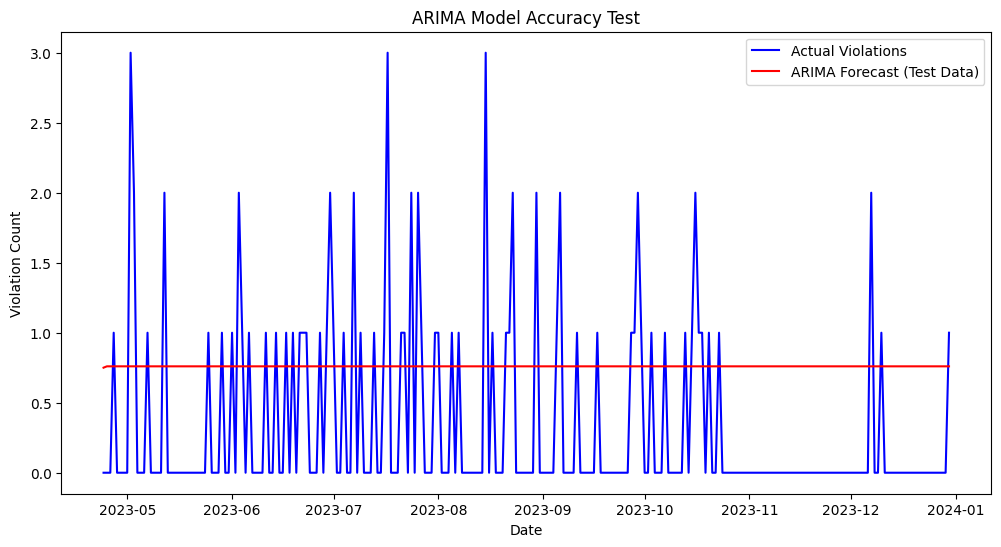

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# Split dataset into train (80%) and test (20%)
train_size = int(len(time_series_data) * 0.8)
train, test = time_series_data[:train_size], time_series_data[train_size:]

# Fit ARIMA model (p=1, d=1, q=1 as initial choice)
arima_model = ARIMA(train["Violation Count"], order=(1, 1, 1))
arima_fit = arima_model.fit()

# Forecast on the test set
forecast_test = arima_fit.forecast(steps=len(test))

# Plot actual vs. forecasted values
plt.figure(figsize=(12, 6))
plt.plot(test.index, test["Violation Count"], label="Actual Violations", color="blue")
plt.plot(test.index, forecast_test, label="ARIMA Forecast (Test Data)", color="red")
plt.title("ARIMA Model Accuracy Test")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


In [ ]:
# Calculate MAE and RMSE
mae = mean_absolute_error(test["Violation Count"], forecast_test)
rmse = np.sqrt(mean_squared_error(test["Violation Count"], forecast_test))

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 0.7050907895876521
Root Mean Squared Error (RMSE): 0.7634611788059544


#LSTM

Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.0215 - val_loss: 0.0113
Epoch 2/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0196 - val_loss: 0.0116
Epoch 3/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0218 - val_loss: 0.0109
Epoch 4/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0237 - val_loss: 0.0109
Epoch 5/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0201 - val_loss: 0.0119
Epoch 6/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0221 - val_loss: 0.0110
Epoch 7/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0196 - val_loss: 0.0113
Epoch 8/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0204 - val_loss: 0.0111
Epoch 9/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0166 - val_loss: 0.0113
Epoch 10/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0202 - val_loss: 0.0110
Epoch 11/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0197 - val_loss: 0.0110
Epoch 12/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 0.0200 - val_l

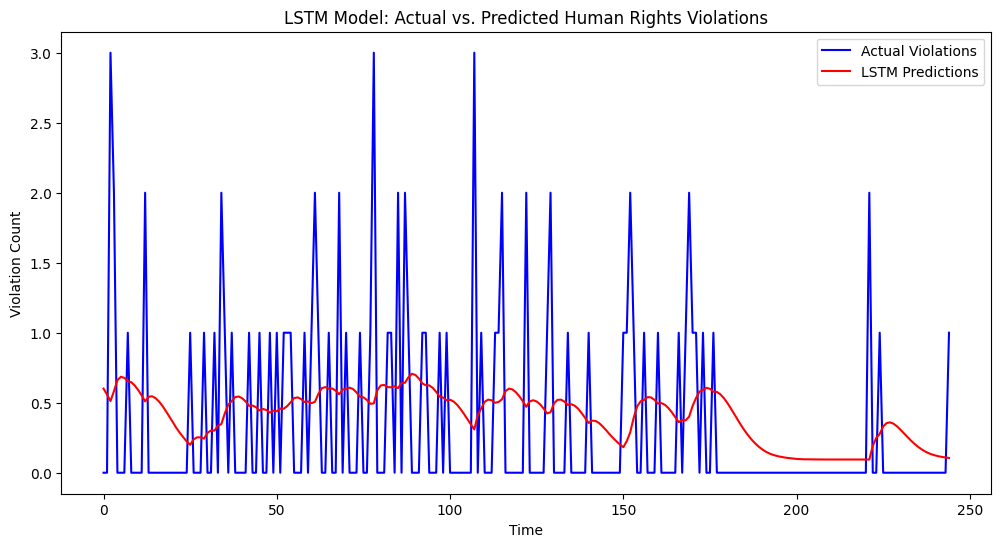

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Normalize data for LSTM training (LSTMs work best with scaled data)
scaler = MinMaxScaler(feature_range=(0, 1))
time_series_data["Scaled_Violations"] = scaler.fit_transform(time_series_data[["Violation Count"]])

# Create sequences for LSTM (e.g., use the past 30 days to predict the next day)
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

# Convert data to sequences
sequence_length = 30  # Using past 30 days for prediction
X, y = create_sequences(time_series_data["Scaled_Violations"].values, sequence_length)

# Split data into train (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Reshape data for LSTM (LSTM expects 3D input: samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))


# Define LSTM model
model = Sequential([
    LSTM(50, activation='relu', return_sequences=True, input_shape=(sequence_length, 1)),
    LSTM(50, activation='relu'),
    Dense(1)  # Output layer
])

# Compile model
model.compile(optimizer='adam', loss='mse')

# Train the model
history = model.fit(X_train, y_train, epochs=20, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict on test data
y_pred = model.predict(X_test)

# Reverse scaling to get actual values
y_pred_actual = scaler.inverse_transform(y_pred.reshape(-1, 1))
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Plot actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(y_test_actual, label="Actual Violations", color="blue")
plt.plot(y_pred_actual, label="LSTM Predictions", color="red")
plt.title("LSTM Model: Actual vs. Predicted Human Rights Violations")
plt.xlabel("Time")
plt.ylabel("Violation Count")
plt.legend()
plt.show()



In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE and RMSE
mae_lstm = mean_absolute_error(y_test_actual, y_pred_actual)
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print(f"LSTM Mean Absolute Error (MAE): {mae_lstm}")
print(f"LSTM Root Mean Squared Error (RMSE): {rmse_lstm}")


LSTM Mean Absolute Error (MAE): 0.5026308114127237
LSTM Root Mean Squared Error (RMSE): 0.6340306678218989


In [ ]:
# Print column names to check if "Date" exists
print(time_series_data.columns)


Index(['Violation Count', 'Scaled_Violations'], dtype='object')


In [ ]:
time_series_data.head()

,Violation Count,Scaled_Violations
Date,,
2020-07-25,1.0,0.166667
2020-07-26,0.0,0.000000
2020-07-27,0.0,0.000000
2020-07-28,0.0,0.000000
2020-07-29,0.0,0.000000


Epoch 1/50


<ipython-input-49-00822dbf1940>:15: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  time_series_data_monthly = time_series_data.resample('M').sum()
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.1403 - val_loss: 0.0174
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1320 - val_loss: 0.0231
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0456 - val_loss: 0.0183
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0726 - val_loss: 0.0268
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0655 - val_loss: 0.0231
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0481 - val_loss: 0.0272
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0577 - val_loss: 0.0249
Epoch 8/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0585 - val_loss: 0.0279
Epoch 9/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0524 - val_loss: 0.0259
Epoch 10/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0474 - val_loss: 0.0197
Epoch 11/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0490 - val_loss: 0.0308
Epoch 12/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0824 - val_loss: 0.0227

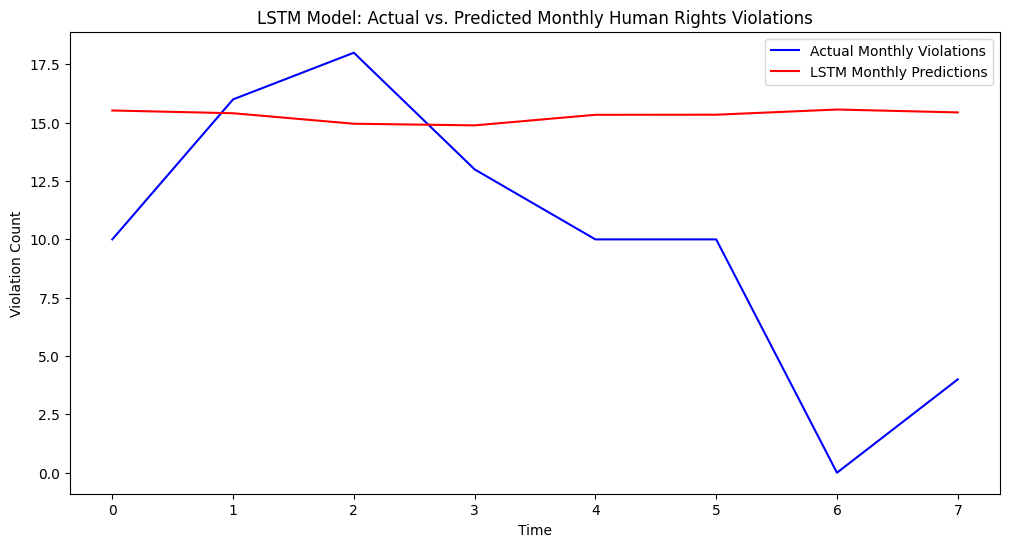

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Ensure the index is in datetime format (if not already)
time_series_data.index = pd.to_datetime(time_series_data.index, errors="coerce")

# Reindex to create a continuous date range (fill missing days with 0 violations)
time_series_data = time_series_data.asfreq("D").fillna(0)

# Now resample to monthly frequency and sum violations
time_series_data_monthly = time_series_data.resample('M').sum()

# Normalize Data (LSTMs work best with scaled data)
scaler = MinMaxScaler(feature_range=(0, 1))
time_series_data_monthly["Scaled_Violations"] = scaler.fit_transform(time_series_data_monthly[["Violation Count"]])

# Create sequences for LSTM (using past 6 months to predict the next month)
def create_sequences(data, seq_length=6):  # 6-months history
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

# Adjust sequence length to prevent overly large sequences
sequence_length = 6  # Keep it consistent with history length
X, y = create_sequences(time_series_data_monthly["Scaled_Violations"].values, sequence_length)

# Split data into train (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Check if we have enough data points
if X_train.shape[0] < 1:
    raise ValueError("Not enough training data points. Try increasing your dataset size or reducing sequence length.")

# Reshape data for LSTM (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Define LSTM model with flexible input shape
model = Sequential([
    LSTM(50, activation='relu', return_sequences=True, input_shape=(None, 1)),  # None lets LSTM handle varying lengths
    LSTM(50, activation='relu'),
    Dense(1)  # Output layer
])

# Compile model
model.compile(optimizer='adam', loss='mse')

# Train the model on Monthly Data
history = model.fit(X_train, y_train, epochs=50, batch_size=1, validation_data=(X_test, y_test), verbose=1)

# Predict on Test Data
y_pred = model.predict(X_test)

# Reverse Scaling to Get Actual Monthly Values
y_pred_actual = scaler.inverse_transform(y_pred.reshape(-1, 1))
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Plot Actual vs. Predicted Monthly Violations
plt.figure(figsize=(12, 6))
plt.plot(y_test_actual, label="Actual Monthly Violations", color="blue")
plt.plot(y_pred_actual, label="LSTM Monthly Predictions", color="red")
plt.title("LSTM Model: Actual vs. Predicted Monthly Human Rights Violations")
plt.xlabel("Time")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


In [ ]:
# Calculate MAE and RMSE for model accuracy evaluation
mae_lstm_monthly = mean_absolute_error(y_test_actual, y_pred_actual)
rmse_lstm_monthly = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

# Display the results
accuracy_results = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_lstm_monthly, rmse_lstm_monthly]
})

# Print results
print(accuracy_results)

                           Metric     Value
0       Mean Absolute Error (MAE)  6.092346
1  Root Mean Squared Error (RMSE)  7.697150


##RNN

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


68/68 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0140 - val_loss: 0.0064
Epoch 2/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0119 - val_loss: 0.0072
Epoch 3/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0117 - val_loss: 0.0052
Epoch 4/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0111 - val_loss: 0.0053
Epoch 5/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0096 - val_loss: 0.0068
Epoch 6/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0116 - val_loss: 0.0051
Epoch 7/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0115 - val_loss: 0.0050
Epoch 8/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0106 - val_loss: 0.0054
Epoch 9/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0092 - val_loss: 0.0055
Epoch 10/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0092 - val_loss: 0.0059
Epoch 11/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0109 - val_loss: 0.0059
Epoch 12/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0095 - val_l

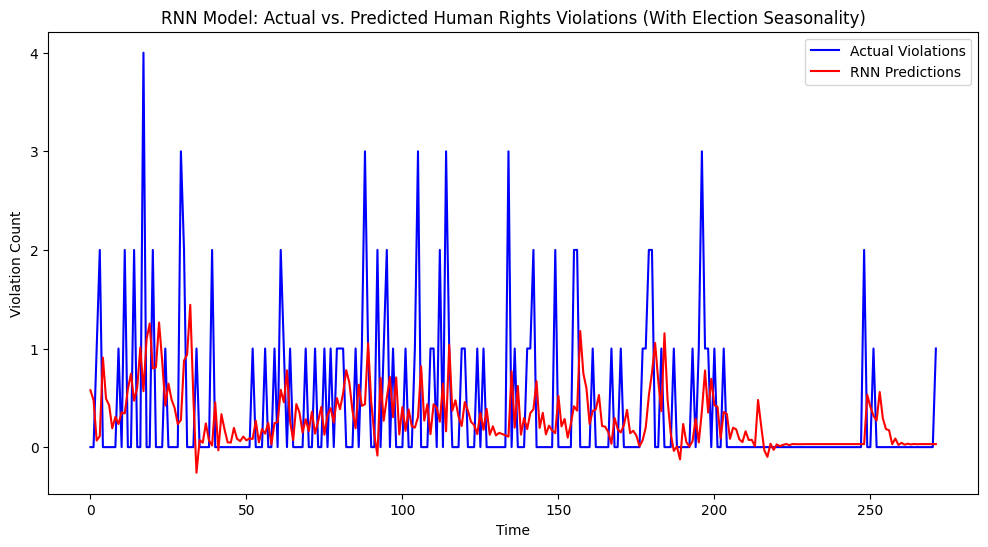

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Ensure the index is in datetime format
time_series_data.index = pd.to_datetime(time_series_data.index, errors="coerce")

# Reindex to create a continuous date range and fill missing days with 0 violations
time_series_data = time_series_data.asfreq("D").fillna(0)

# Add an "Election Season" binary feature (Example: elections occur in July & August)
time_series_data["Election_Season"] = time_series_data.index.month.isin([7, 8]).astype(int)
time_series_data["Protest_Season"] = time_series_data.index.month.isin([3, 5, 10]).astype(int)
time_series_data["Policy_Change"] = time_series_data.index.strftime('%Y-%m').isin(["2021-06", "2022-04"]).astype(int)


# Normalize Data (LSTMs and RNNs work best with scaled data)
scaler = MinMaxScaler(feature_range=(0, 1))
time_series_data["Scaled_Violations"] = scaler.fit_transform(time_series_data[["Violation Count"]])

# Normalize the election season variable separately (optional, but recommended)
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data[["Election_Season"]])

scaler_protest = MinMaxScaler(feature_range=(0, 1))
time_series_data["Scaled_Protest_Season"] = scaler_protest.fit_transform(time_series_data[["Protest_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data[["Policy_Change"]])


# Create sequences for RNN (use past 30 days to predict the next day)
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
        y.append(data.iloc[i+seq_length]["Scaled_Violations"])
    return np.array(X), np.array(y)

# Prepare dataset with both features (Scaled_Violations & Scaled_Election_Season)
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]
sequence_length = 30  # Use past 30 days for prediction
X, y = create_sequences(time_series_data[features], sequence_length)

# Split data into train (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Reshape data for RNN (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], len(features)))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], len(features)))

# Define RNN Model
model_rnn = Sequential([
    SimpleRNN(50, activation='relu', return_sequences=True, input_shape=(sequence_length, len(features))),
    SimpleRNN(50, activation='relu'),
    Dense(1)
])

# Compile and Train
model_rnn.compile(optimizer='adam', loss='mse')

# Train with early stopping
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_rnn.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)
#history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict on test data using the trained RNN model
y_pred_rnn = model_rnn.predict(X_test)

# Reverse Scaling to Get Actual Values
y_pred_actual_rnn = scaler.inverse_transform(y_pred_rnn.reshape(-1, 1))
y_test_actual_rnn = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate MAE and RMSE for RNN model accuracy evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae_rnn = mean_absolute_error(y_test_actual_rnn, y_pred_actual_rnn)
rmse_rnn = np.sqrt(mean_squared_error(y_test_actual_rnn, y_pred_actual_rnn))

# Display the results
accuracy_results_rnn = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_rnn, rmse_rnn]
})

# Print results
print(accuracy_results_rnn)

# Plot Actual vs Predicted Values
plt.figure(figsize=(12, 6))
plt.plot(y_test_actual_rnn, label="Actual Violations", color="blue")
plt.plot(y_pred_actual_rnn, label="RNN Predictions", color="red")
plt.title("RNN Model: Actual vs. Predicted Human Rights Violations (With Election Seasonality)")
plt.xlabel("Time")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


##SARIMA AND RNN

In [ ]:
# Function to create sequences for RNN
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
        y.append(data.iloc[i+seq_length]["Scaled_Violations"])
    return np.array(X), np.array(y)

# Prepare dataset
sequence_length = 30  # Using past 30 days for prediction
X, y = create_sequences(time_series_data[features], sequence_length)

# Split data into train (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Ensure X_test has the correct shape
if X_test.shape[1] < 30:
    raise ValueError(f"X_test has only {X_test.shape[1]} timesteps, expected 30. Check sequence creation.")

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], len(features)))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], len(features)))


In [ ]:
# Define RNN Model
model_rnn = Sequential([
    SimpleRNN(50, activation='relu', return_sequences=True, input_shape=(sequence_length, len(features))),
    SimpleRNN(50, activation='relu'),
    Dense(1)
])

# Compile Model
model_rnn.compile(optimizer='adam', loss='mse')

# Train with early stopping
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_rnn.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)


Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


68/68 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0141 - val_loss: 0.0068
Epoch 2/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0122 - val_loss: 0.0050
Epoch 3/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0114 - val_loss: 0.0059
Epoch 4/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0109 - val_loss: 0.0053
Epoch 5/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0115 - val_loss: 0.0054
Epoch 6/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0088 - val_loss: 0.0052
Epoch 7/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0098 - val_loss: 0.0051


In [ ]:
# Define RNN Model
model_rnn = Sequential([
    SimpleRNN(50, activation='relu', return_sequences=True, input_shape=(sequence_length, len(features))),
    SimpleRNN(50, activation='relu'),
    Dense(1)
])

# Compile Model
model_rnn.compile(optimizer='adam', loss='mse')

# Train with early stopping
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_rnn.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)


Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


68/68 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.0171 - val_loss: 0.0077
Epoch 2/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0109 - val_loss: 0.0116
Epoch 3/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0137 - val_loss: 0.0057
Epoch 4/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0121 - val_loss: 0.0054
Epoch 5/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0108 - val_loss: 0.0064
Epoch 6/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0106 - val_loss: 0.0055
Epoch 7/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0098 - val_loss: 0.0062
Epoch 8/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0110 - val_loss: 0.0058
Epoch 9/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0107 - val_loss: 0.0053
Epoch 10/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0097 - val_loss: 0.0056
Epoch 11/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0095 - val_loss: 0.0058
Epoch 12/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0095 - val_l

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Train SARIMA Model
sarima_model = SARIMAX(time_series_data["Violation Count"],
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 12),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_fit = sarima_model.fit()

forecast_steps=30

# Forecast using SARIMA
sarima_forecast = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean

# Generate correct future index
sarima_forecast_index = pd.date_range(start=time_series_data.index[-1] + pd.Timedelta(days=1), periods=forecast_steps, freq="D")

# Convert SARIMA predictions into DataFrame
sarima_forecast_df = pd.DataFrame(sarima_forecast.values, index=sarima_forecast_index, columns=["SARIMA_Predictions"])


In [ ]:
# Initialize X_input with last training sequence
X_input = np.array(X_test[-1]).reshape(1, 30, len(features)).astype("float32")

# Store RNN predictions
rnn_forecast = []

for _ in range(forecast_steps):
    y_pred = model_rnn.predict(X_input)
    rnn_forecast.append(y_pred[0, 0])

    # Update input sequence
    X_input = np.roll(X_input, shift=-1, axis=1)
    X_input[0, -1, 0] = y_pred[0, 0]

# Convert RNN predictions into DataFrame
rnn_forecast_df = pd.DataFrame(rnn_forecast, index=sarima_forecast_index, columns=["RNN_Predictions"])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━

In [ ]:
# Combine RNN and SARIMA into an ensemble forecast
ensemble_forecast = (0.5 * rnn_forecast_df["RNN_Predictions"]) + (0.5 * sarima_forecast_df["SARIMA_Predictions"])

# Create ensemble results DataFrame
ensemble_results = pd.DataFrame({
    "RNN_Predictions": rnn_forecast_df["RNN_Predictions"].values,
    "SARIMA_Predictions": sarima_forecast_df["SARIMA_Predictions"].values,
    "Ensemble_Predictions": ensemble_forecast.values
}, index=sarima_forecast_index)

print(ensemble_results.head())  # Check results


            RNN_Predictions  SARIMA_Predictions  Ensemble_Predictions
2023-12-31         0.003561            0.093411              0.048486
2024-01-01         0.004205            0.146304              0.075254
2024-01-02         0.004602            0.145769              0.075185
2024-01-03         0.004913            0.275019              0.139966
2024-01-04         0.005164            0.136626              0.070895


In [ ]:
# Combine RNN and SARIMA into an ensemble forecast
ensemble_forecast = (0.5 * rnn_forecast_df["RNN_Predictions"]) + (0.5 * sarima_forecast_df["SARIMA_Predictions"])

# Create ensemble results DataFrame
ensemble_results = pd.DataFrame({
    "RNN_Predictions": rnn_forecast_df["RNN_Predictions"].values,
    "SARIMA_Predictions": sarima_forecast_df["SARIMA_Predictions"].values,
    "Ensemble_Predictions": ensemble_forecast.values
}, index=sarima_forecast_index)

print(ensemble_results.head())  # Check results

            RNN_Predictions  SARIMA_Predictions  Ensemble_Predictions
2023-12-31         0.008005            0.093411              0.050708
2024-01-01         0.009081            0.146304              0.077692
2024-01-02         0.009856            0.145769              0.077812
2024-01-03         0.010348            0.275019              0.142683
2024-01-04         0.011332            0.136626              0.073979


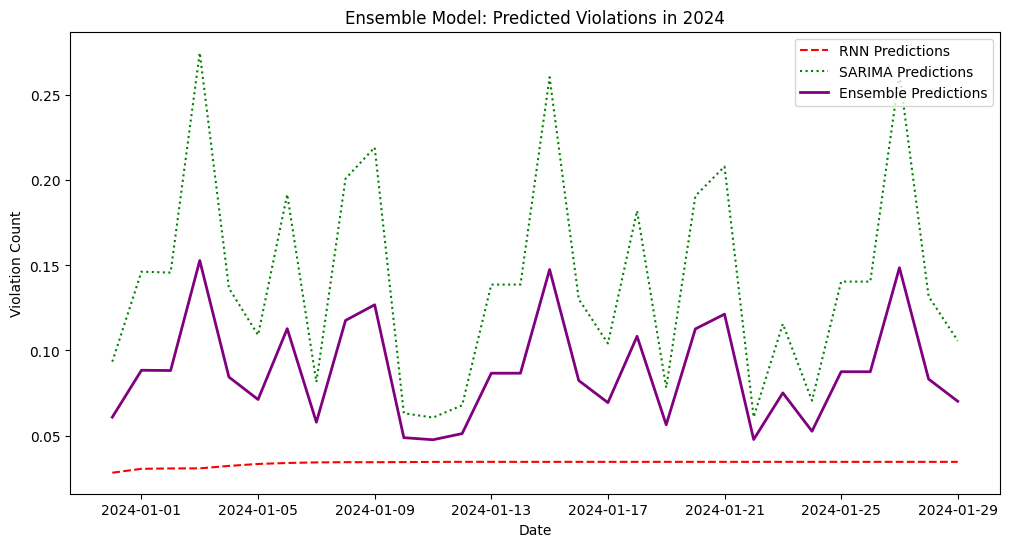

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(ensemble_results.index, ensemble_results["RNN_Predictions"], label="RNN Predictions", color="red", linestyle="dashed")
plt.plot(ensemble_results.index, ensemble_results["SARIMA_Predictions"], label="SARIMA Predictions", color="green", linestyle="dotted")
plt.plot(ensemble_results.index, ensemble_results["Ensemble_Predictions"], label="Ensemble Predictions", color="purple", linewidth=2)
plt.title("Ensemble Model: Predicted Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


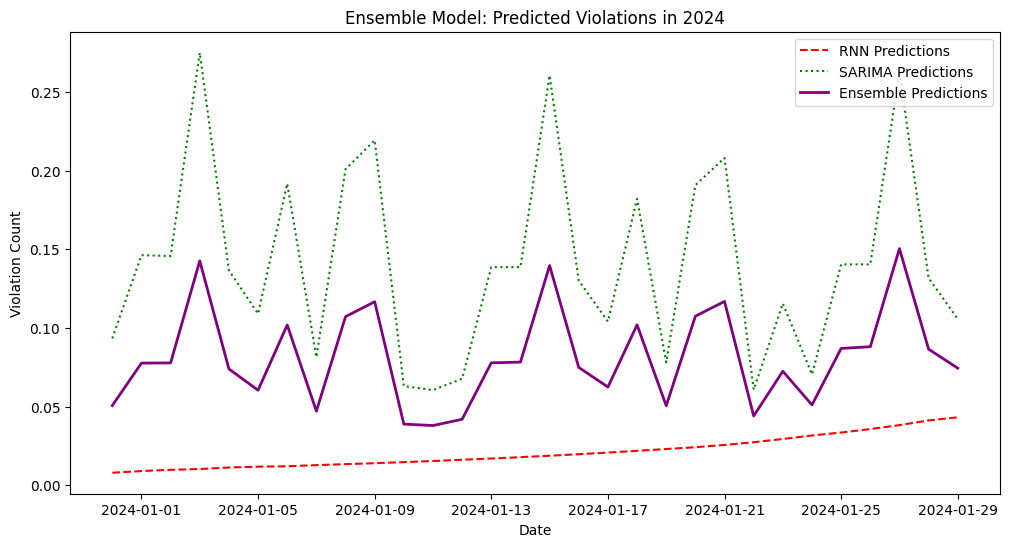

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(ensemble_results.index, ensemble_results["RNN_Predictions"], label="RNN Predictions", color="red", linestyle="dashed")
plt.plot(ensemble_results.index, ensemble_results["SARIMA_Predictions"], label="SARIMA Predictions", color="green", linestyle="dotted")
plt.plot(ensemble_results.index, ensemble_results["Ensemble_Predictions"], label="Ensemble Predictions", color="purple", linewidth=2)
plt.title("Ensemble Model: Predicted Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

In [ ]:
# Combine RNN and SARIMA into an ensemble forecast
ensemble_forecast = (0.5 * rnn_forecast_df["RNN_Predictions"]) + (0.5 * sarima_forecast_df["SARIMA_Predictions"])

# Create ensemble results DataFrame
ensemble_results = pd.DataFrame({
    "RNN_Predictions": rnn_forecast_df["RNN_Predictions"].values,
    "SARIMA_Predictions": sarima_forecast_df["SARIMA_Predictions"].values,
    "Ensemble_Predictions": ensemble_forecast.values
}, index=sarima_forecast_index)

print(ensemble_results.head())  # Check results

            RNN_Predictions  SARIMA_Predictions  Ensemble_Predictions
2023-12-31         0.008005            0.093411              0.084871
2024-01-01         0.009081            0.146304              0.132581
2024-01-02         0.009856            0.145769              0.132178
2024-01-03         0.010348            0.275019              0.248552
2024-01-04         0.011332            0.136626              0.124097


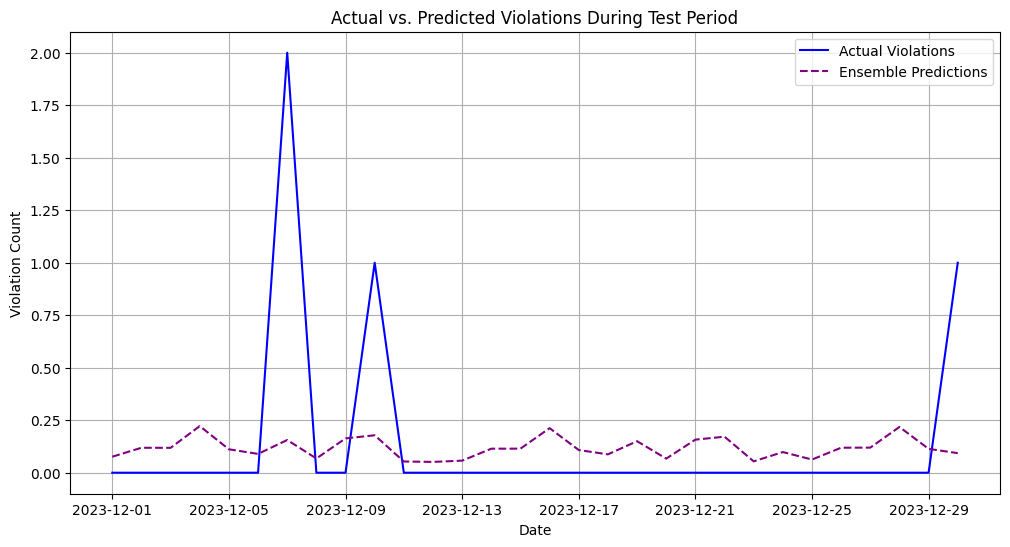

In [ ]:
import matplotlib.pyplot as plt

# Extract last `forecast_steps` days of actual test data
test_index_aligned = test_index[-forecast_steps:]  # Get last 30 days
y_test_actual_aligned = y_test_actual[-forecast_steps:]  # Match predictions

# Extract ensemble predictions for the same 30-day period
ensemble_test_predictions_aligned = ensemble_results["Ensemble_Predictions"][:forecast_steps]

# Plot actual vs predicted values during the test period
plt.figure(figsize=(12, 6))
plt.plot(test_index_aligned, y_test_actual_aligned, label="Actual Violations", color="blue", linestyle="solid")
plt.plot(test_index_aligned, ensemble_test_predictions_aligned, label="Ensemble Predictions", color="purple", linestyle="dashed")
plt.title("Actual vs. Predicted Violations During Test Period")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.grid(True)
plt.show()


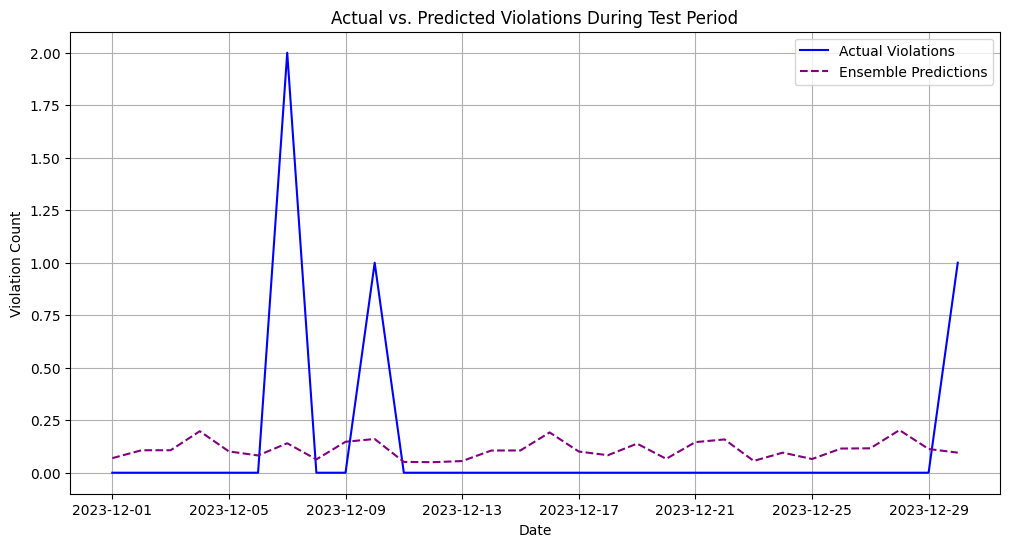

In [ ]:
import matplotlib.pyplot as plt

# Extract last `forecast_steps` days of actual test data
test_index_aligned = test_index[-forecast_steps:]  # Get last 30 days
y_test_actual_aligned = y_test_actual[-forecast_steps:]  # Match predictions

# Extract ensemble predictions for the same 30-day period
ensemble_test_predictions_aligned = ensemble_results["Ensemble_Predictions"][:forecast_steps]

# Plot actual vs predicted values during the test period
plt.figure(figsize=(12, 6))
plt.plot(test_index_aligned, y_test_actual_aligned, label="Actual Violations", color="blue", linestyle="solid")
plt.plot(test_index_aligned, ensemble_test_predictions_aligned, label="Ensemble Predictions", color="purple", linestyle="dashed")
plt.title("Actual vs. Predicted Violations During Test Period")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Compute Mean Squared Error (MSE) and Root Mean Squared Error (RMSE) for the test period

# Ensure alignment of actual and predicted values for the last forecast period
y_test_actual_aligned = y_test_actual[-forecast_steps:]  # Last 30 days
ensemble_test_predictions_aligned = ensemble_results["Ensemble_Predictions"][:forecast_steps]

# Compute MSE and RMSE
mse_ensemble_test = mean_squared_error(y_test_actual_aligned, ensemble_test_predictions_aligned)
rmse_ensemble_test = np.sqrt(mse_ensemble_test)

# Display results
mse_rmse_results = pd.DataFrame({
    "Metric": ["Mean Squared Error (MSE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mse_ensemble_test, rmse_ensemble_test]
})


# Print results
print(f"Mean Squared Error (MSE): {mse_ensemble_test:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_ensemble_test:.4f}")


Mean Squared Error (MSE): 0.1812
Root Mean Squared Error (RMSE): 0.4257


In [ ]:
# Compute Mean Squared Error (MSE) and Root Mean Squared Error (RMSE) for the test period

# Ensure alignment of actual and predicted values for the last forecast period
y_test_actual_aligned = y_test_actual[-forecast_steps:]  # Last 30 days
ensemble_test_predictions_aligned = ensemble_results["Ensemble_Predictions"][:forecast_steps]

# Compute MSE and RMSE
mse_ensemble_test = mean_squared_error(y_test_actual_aligned, ensemble_test_predictions_aligned)
rmse_ensemble_test = np.sqrt(mse_ensemble_test)

# Display results
mse_rmse_results = pd.DataFrame({
    "Metric": ["Mean Squared Error (MSE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mse_ensemble_test, rmse_ensemble_test]
})


# Print results
print(f"Mean Squared Error (MSE): {mse_ensemble_test:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_ensemble_test:.4f}")


Mean Squared Error (MSE): 0.1768
Root Mean Squared Error (RMSE): 0.4204


In [ ]:
# Check basic statistics on actual violations
print("Min Violations:", y_test_actual.min())
print("Max Violations:", y_test_actual.max())
print("Mean Violations:", y_test_actual.mean())
print("Median Violations:", np.median(y_test_actual))
print("Standard Deviation:", np.std(y_test_actual))


Min Violations: 0.0
Max Violations: 4.0
Mean Violations: 0.38235294117647056
Median Violations: 0.0
Standard Deviation: 0.7332324036657595


In [ ]:
# Ensure daily frequency (to align with ensemble_results)
time_series_data = time_series_data.asfreq("D").fillna(0)

# Extract actual violations for the same forecasted period
actual_violations = time_series_data["Violation Count"]

# Ensure the index matches the ensemble forecast dates
actual_violations = actual_violations.reindex(ensemble_results.index, fill_value=0)

# Add actual violations to `ensemble_results`
ensemble_results["Actual_Violations"] = actual_violations.values

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Compute MAE and RMSE for the ensemble model
mae_ensemble = mean_absolute_error(ensemble_results["Actual_Violations"], ensemble_results["Ensemble_Predictions"])
rmse_ensemble = np.sqrt(mean_squared_error(ensemble_results["Actual_Violations"], ensemble_results["Ensemble_Predictions"]))

# Display results
accuracy_results_ensemble = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble, rmse_ensemble]
})

print(accuracy_results_ensemble)

                           Metric     Value
0       Mean Absolute Error (MAE)  0.081334
1  Root Mean Squared Error (RMSE)  0.086964


In [ ]:
# Ensure daily frequency (to align with ensemble_results)
time_series_data = time_series_data.asfreq("D").fillna(0)

# Extract actual violations for the same forecasted period
actual_violations = time_series_data["Violation Count"]

# Ensure the index matches the ensemble forecast dates
actual_violations = actual_violations.reindex(ensemble_results.index, fill_value=0)

# Add actual violations to `ensemble_results`
ensemble_results["Actual_Violations"] = actual_violations.values


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Compute MAE and RMSE for the ensemble model
mae_ensemble = mean_absolute_error(ensemble_results["Actual_Violations"], ensemble_results["Ensemble_Predictions"])
rmse_ensemble = np.sqrt(mean_squared_error(ensemble_results["Actual_Violations"], ensemble_results["Ensemble_Predictions"]))

# Display results
accuracy_results_ensemble = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble, rmse_ensemble]
})

print(accuracy_results_ensemble)


                           Metric     Value
0       Mean Absolute Error (MAE)  0.087716
1  Root Mean Squared Error (RMSE)  0.092855


In [ ]:
# Calculate percentage change for RNN predictions
ensemble_results["RNN_Percentage_Change"] = ensemble_results["RNN_Predictions"].pct_change() * 100

# Calculate percentage change for SARIMA predictions
ensemble_results["SARIMA_Percentage_Change"] = ensemble_results["SARIMA_Predictions"].pct_change() * 100

# Calculate percentage change for Ensemble forecast
ensemble_results["Ensemble_Percentage_Change"] = ensemble_results["Ensemble_Predictions"].pct_change() * 100

#view percentage of esemble
# Compute the mean percentage change for the Ensemble forecast
mean_ensemble_percentage_change = ensemble_results["Ensemble_Percentage_Change"].mean()

# Print the mean percentage change for the Ensemble forecast
print(f"Mean Percentage Change in Ensemble Forecast: {mean_ensemble_percentage_change:.2f}%")


Mean Percentage Change in Ensemble Forecast: 18.00%


In [ ]:
time_series_data.columns

In [ ]:
# Define the file path to save the model
csv_filename = "/content/drive/MyDrive/Colab Notebooks/Research - Trends/ensemble_forecast.csv"

ensemble_results["Region"] = "East & Horn of Africa"

ensemble_results.index.name = "Date"  #

# Save the DataFrame to a CSV file
ensemble_results.to_csv(csv_filename)

print(f"Ensemble forecast saved to {csv_filename}")


##Poison

In [ ]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

# Prepare data for Poisson regression
poisson_data = pd.DataFrame({
    "Previous_Violations": np.roll(y_test_actual, shift=1),  # Use previous day's violations as a predictor
    "Violations": y_test_actual
})
poisson_data = poisson_data.iloc[1:]  # Remove first row with NaN

# Fit Poisson regression model
poisson_model = sm.GLM(poisson_data["Violations"], sm.add_constant(poisson_data["Previous_Violations"]),
                       family=sm.families.Poisson()).fit()

# Make predictions
poisson_predictions = poisson_model.predict(sm.add_constant(poisson_data["Previous_Violations"]))

# Calculate RMSE for Poisson model
mse_poisson = mean_squared_error(poisson_data["Violations"], poisson_predictions)
rmse_poisson = np.sqrt(mse_poisson)

# Print results
print(f"Poisson Model - Mean Squared Error (MSE): {mse_poisson:.4f}")
print(f"Poisson Model - Root Mean Squared Error (RMSE): {rmse_poisson:.4f}")


Poisson Model - Mean Squared Error (MSE): 0.5370
Poisson Model - Root Mean Squared Error (RMSE): 0.7328


##Bayesian

Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - loss: 0.1738
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.1309
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0549
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0541
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0532
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0531
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0552
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0534
Epoch 9/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0550
Epoch 10/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0547
Epoch 11/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0547
Epoch 12/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0560
Epoch 13/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0547
Epoch 14/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0555
Epoch 15/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0540
Epoch 16/20
30/

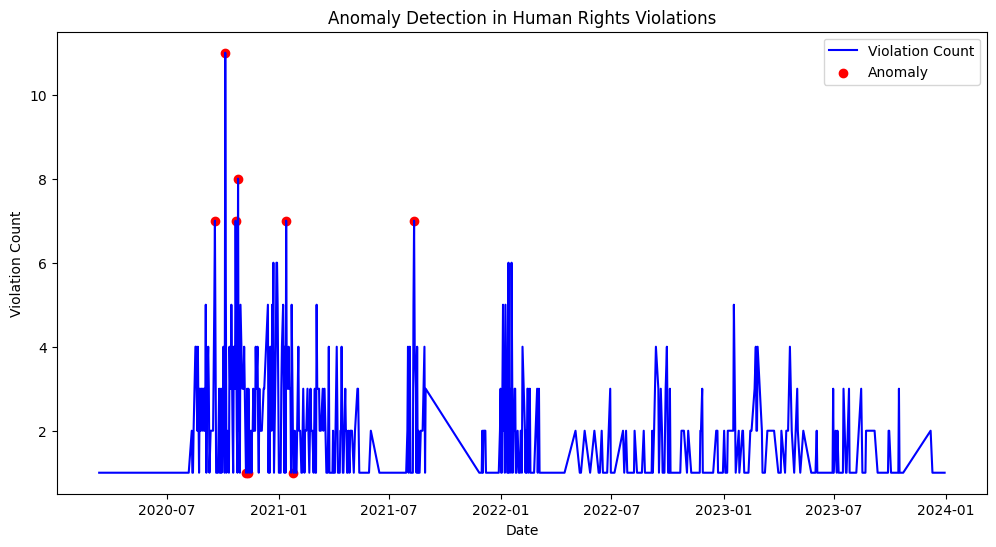

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM
from tensorflow.keras.optimizers import Adam

# Load the dataset
time_series_data = master_dataset.groupby("Date").size().reset_index(name="Violation Count")
time_series_data["Date"] = pd.to_datetime(time_series_data["Date"])
time_series_data.set_index("Date", inplace=True)

# Normalize Data for Unsupervised Models
scaler = MinMaxScaler()
time_series_data["Scaled_Violations"] = scaler.fit_transform(time_series_data[["Violation Count"]])

# Define number of previous time steps for LSTM-based autoencoder
sequence_length = 30

def create_sequences(data, seq_length):
    """Create sequences for Autoencoder training."""
    X = []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
    return np.array(X)

X_seq = create_sequences(time_series_data["Scaled_Violations"].values, sequence_length)

# ---- 1️⃣ Isolation Forest ----
iso_forest = IsolationForest(contamination=0.02, random_state=42)
iso_preds = iso_forest.fit_predict(time_series_data[["Scaled_Violations"]])
time_series_data["IsolationForest_Anomaly"] = iso_preds

# ---- 2️⃣ One-Class SVM ----
oc_svm = OneClassSVM(kernel="rbf", gamma=0.1, nu=0.02)
oc_preds = oc_svm.fit_predict(time_series_data[["Scaled_Violations"]])
time_series_data["OneClassSVM_Anomaly"] = oc_preds

# ---- 3️⃣ Autoencoder-based Anomaly Detection ----
# Define LSTM Autoencoder Model
autoencoder = Sequential([
    LSTM(32, activation='relu', return_sequences=True, input_shape=(sequence_length, 1)),
    LSTM(16, activation='relu', return_sequences=False),
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(sequence_length, activation='sigmoid')
])

autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

# Reshape Data for LSTM Autoencoder
X_train = X_seq.reshape((X_seq.shape[0], X_seq.shape[1], 1))

# Train Autoencoder
autoencoder.fit(X_train, X_train, epochs=20, batch_size=16, shuffle=True, verbose=1)

# Compute Reconstruction Error (Fix: Ensure Shape Consistency)
X_pred = autoencoder.predict(X_train)

# Reshape X_pred to match X_train shape
X_pred = X_pred.reshape(X_train.shape)  # ✅ Fix: Match shape (478,30,1)

# Calculate absolute reconstruction error
reconstruction_error = np.mean(np.abs(X_pred - X_train), axis=(1, 2))

# Define anomaly threshold based on quantile
threshold = np.percentile(reconstruction_error, 98)  # Top 2% as anomalies
time_series_data["Autoencoder_Anomaly"] = 0
time_series_data.iloc[sequence_length:, time_series_data.columns.get_loc("Autoencoder_Anomaly")] = (
    reconstruction_error > threshold
).astype(int)


# Combine Anomaly Results
time_series_data["Anomaly Score"] = (
    (time_series_data["IsolationForest_Anomaly"] == -1).astype(int) +
    (time_series_data["OneClassSVM_Anomaly"] == -1).astype(int) +
    time_series_data["Autoencoder_Anomaly"]
)

# Flag anomalies where at least two methods agree
time_series_data["Final_Anomaly"] = (time_series_data["Anomaly Score"] >= 2).astype(int)

import matplotlib.pyplot as plt

# Print first few rows to check anomalies
print(time_series_data[["Violation Count", "Final_Anomaly"]].head())

# Save results to CSV (optional)
time_series_data[["Violation Count", "Final_Anomaly"]].to_csv("anomaly_detection_results.csv")

# ---- 📊 Visualization: Plot Anomalies in Time Series ----
plt.figure(figsize=(12, 6))
plt.plot(time_series_data.index, time_series_data["Violation Count"], label="Violation Count", color="blue")

# Highlight anomalies
anomalies = time_series_data[time_series_data["Final_Anomaly"] == 1]
plt.scatter(anomalies.index, anomalies["Violation Count"], color="red", label="Anomaly", marker="o")

plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.title("Anomaly Detection in Human Rights Violations")
plt.legend()
plt.show()


Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - loss: 1.0762 - val_loss: 0.0462
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.2478 - val_loss: 0.0710
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.2188 - val_loss: 0.0641
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.2117 - val_loss: 0.0250
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.1745 - val_loss: 0.0357
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.1894 - val_loss: 0.0261
Epoch 7/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1611 - val_loss: 0.0423
Epoch 8/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1561 - val_loss: 0.0212
Epoch 9/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.1193 - val_loss: 0.0126
Epoch 10/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.1027 - val_loss: 0.0110
Epoch 11/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0665 - val_loss: 0.0198
Epoch 12/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0

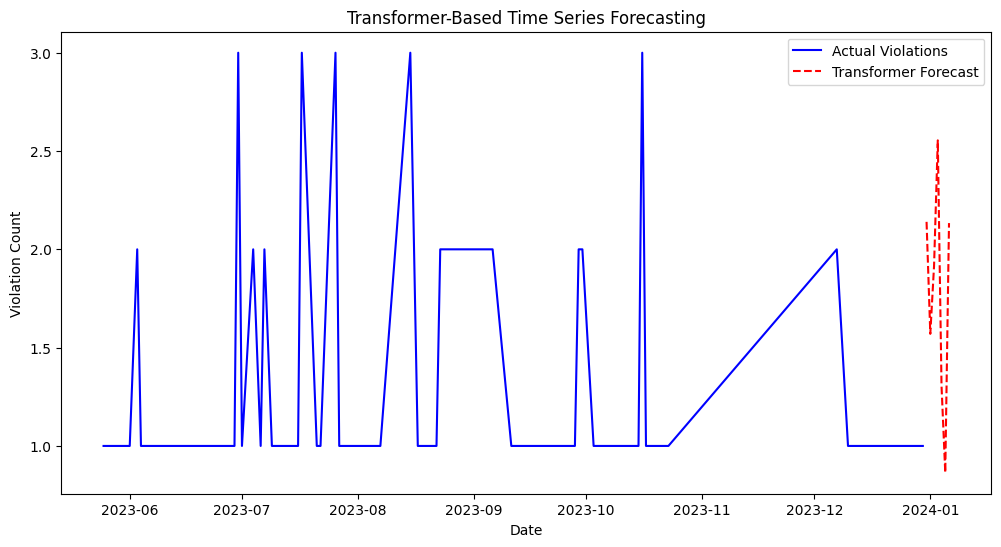

Transformer Model Performance:
📉 Mean Absolute Error (MAE): 0.88
📈 Root Mean Squared Error (RMSE): 0.98
🔢 Mean Absolute Percentage Error (MAPE): 73.69%


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LayerNormalization, MultiHeadAttention, Dropout, Add, Flatten
from tensorflow.keras.optimizers import Adam

# Load and preprocess the dataset
time_series_data = master_dataset.groupby("Date").size().reset_index(name="Violation Count")
time_series_data["Date"] = pd.to_datetime(time_series_data["Date"])
time_series_data.set_index("Date", inplace=True)

# Normalize the data
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
time_series_data["Scaled_Violations"] = scaler.fit_transform(time_series_data[["Violation Count"]])

# Prepare sequence data
sequence_length = 30
forecast_horizon = 7  # Predict 7 days ahead

def create_sequences(data, seq_length):
    """Generate sequences for transformer input"""
    X, y = [], []
    for i in range(len(data) - seq_length - forecast_horizon):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length:i+seq_length+forecast_horizon])
    return np.array(X), np.array(y)

X, y = create_sequences(time_series_data["Scaled_Violations"].values, sequence_length)

# Train-test split
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Ensure the shape is compatible with Transformer input
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# ---- Transformer Encoder Model ----
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super(TransformerBlock, self).__init__()
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(embed_dim),
        ])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs, training=False):  # ✅ Fix: Add `training` default
        attn_output = self.att(inputs, inputs, training=training)  # ✅ Pass `training`
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1, training=training)  # ✅ Pass `training`
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

# Define Transformer Model
input_layer = Input(shape=(sequence_length, 1))
transformer_block = TransformerBlock(embed_dim=64, num_heads=4, ff_dim=64)(input_layer, training=True)  # ✅ Fix: Explicitly pass `training`
flatten_layer = Flatten()(transformer_block)
output_layer = Dense(forecast_horizon)(flatten_layer)

# Compile Model
model_transformer = Model(inputs=input_layer, outputs=output_layer)
model_transformer.compile(optimizer=Adam(learning_rate=0.001), loss="mse")

# Train Model
model_transformer.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Forecast
forecast_transformer = model_transformer.predict(X_test)

# Convert only the forecasted values back to the original scale
forecast_transformer_rescaled = scaler.inverse_transform(forecast_transformer.reshape(-1, 1))

# Ensure forecast shape matches forecast horizon
forecast_transformer_rescaled = forecast_transformer_rescaled[:forecast_horizon]  # ✅ Fix: Ensure correct shape

# Prepare results DataFrame
forecast_dates = pd.date_range(start=time_series_data.index[-1] + pd.Timedelta(days=1), periods=forecast_horizon, freq="D")
forecast_df = pd.DataFrame(forecast_transformer_rescaled, index=forecast_dates, columns=["Transformer Forecast"])

# Print first few rows of forecast results
print(forecast_df.head())

# Save forecast results to CSV (optional)
forecast_df.to_csv("transformer_forecast_results.csv")

# ---- 📊 Visualization: Plot Forecast vs Actual ----
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(time_series_data.index[-60:], time_series_data["Violation Count"].values[-60:], label="Actual Violations", color="blue")

# Plot forecast
plt.plot(forecast_df.index, forecast_df["Transformer Forecast"], label="Transformer Forecast", color="red", linestyle="dashed")

plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.title("Transformer-Based Time Series Forecasting")
plt.legend()
plt.show()

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Extract actual values corresponding to forecast dates
actual_values = time_series_data["Violation Count"].iloc[-forecast_horizon:].values

# Compute Performance Metrics
mae = mean_absolute_error(actual_values, forecast_transformer_rescaled)
rmse = np.sqrt(mean_squared_error(actual_values, forecast_transformer_rescaled))
mape = np.mean(np.abs((actual_values - forecast_transformer_rescaled) / actual_values)) * 100

# Print Performance Metrics
print(f"Transformer Model Performance:")
print(f"📉 Mean Absolute Error (MAE): {mae:.2f}")
print(f"📈 Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"🔢 Mean Absolute Percentage Error (MAPE): {mape:.2f}%")


#tuningii

In [ ]:
import itertools
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Reduce search space
p = d = q = range(0, 2)  # Limit values to 0-1
seasonal_p = seasonal_d = seasonal_q = range(0, 2)  # Reduce seasonal terms
seasonal_period = [12]  # Monthly seasonality

# Generate combinations
pdq = list(itertools.product(p, d, q))
seasonal_pdq = list(itertools.product(seasonal_p, seasonal_d, seasonal_q, seasonal_period))

best_aic = float("inf")
best_params = None

# Define an early stopping AIC threshold (stops if no improvement after X iterations)
improvement_threshold = 10  # Stop if AIC doesn’t improve by 10
no_improvement_count = 0

for param in pdq:
    for seasonal_param in seasonal_pdq:
        try:
            model = SARIMAX(time_series_data["Violation Count"],
                            order=param,
                            seasonal_order=seasonal_param,
                            enforce_stationarity=False,
                            enforce_invertibility=False)
            results = model.fit(disp=False)

            if results.aic < best_aic - improvement_threshold:  # Check if improvement is significant
                best_aic = results.aic
                best_params = (param, seasonal_param)
                no_improvement_count = 0  # Reset counter
            else:
                no_improvement_count += 1

            if no_improvement_count >= 10:  # Stop after 10 iterations with no improvement
                print("Early stopping triggered due to no significant AIC improvement.")
                break

        except Exception as e:
            continue  # Skip failed models

print(f"Best SARIMA Parameters: {best_params}")


Early stopping triggered due to no significant AIC improvement.
Early stopping triggered due to no significant AIC improvement.
Early stopping triggered due to no significant AIC improvement.
Early stopping triggered due to no significant AIC improvement.
Early stopping triggered due to no significant AIC improvement.
Best SARIMA Parameters: ((0, 1, 1), (0, 0, 1, 12))


In [ ]:
!pip install keras-tuner


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 3.2 MB/s eta 0:00:00


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import ParameterGrid

# Define parameter grid for tuning
param_grid = {
    "units": [32, 64, 128],  # Number of LSTM neurons
    "learning_rate": [1e-3, 5e-4, 1e-4],  # Learning rate
    "batch_size": [16, 32]  # Batch sizes
}

best_loss = float("inf")
best_params = {}

for params in ParameterGrid(param_grid):
    print(f"Testing params: {params}")

    # Build LSTM Model
    model = Sequential([
        LSTM(params["units"], activation="relu", return_sequences=True, input_shape=(30, len(features))),
        LSTM(params["units"], activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=params["learning_rate"]), loss="mse")

    # Train Model
    history = model.fit(X_train, y_train, epochs=20, batch_size=params["batch_size"], validation_data=(X_test, y_test), verbose=0)

    # Get validation loss
    val_loss = min(history.history["val_loss"])
    print(f"Validation Loss: {val_loss}")

    # Update best parameters
    if val_loss < best_loss:
        best_loss = val_loss
        best_params = params

print(f"✅ Best Hyperparameters: {best_params}")

# Re-train the best model
best_model = Sequential([
    LSTM(best_params["units"], activation="relu", return_sequences=True, input_shape=(sequence_length, len(features))),
    LSTM(best_params["units"], activation="relu"),
    Dense(1)
])
best_model.compile(optimizer=Adam(learning_rate=best_params["learning_rate"]), loss="mse")

# Train the final model
history = best_model.fit(X_train, y_train, epochs=50, batch_size=best_params["batch_size"], validation_data=(X_test, y_test), verbose=1)


Testing params: {'batch_size': 16, 'learning_rate': 0.001, 'units': 32}


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Validation Loss: 0.004435352515429258
Testing params: {'batch_size': 16, 'learning_rate': 0.001, 'units': 64}
Validation Loss: 0.004410038702189922
Testing params: {'batch_size': 16, 'learning_rate': 0.001, 'units': 128}
Validation Loss: 0.004399205558001995
Testing params: {'batch_size': 16, 'learning_rate': 0.0005, 'units': 32}
Validation Loss: 0.0043553803116083145
Testing params: {'batch_size': 16, 'learning_rate': 0.0005, 'units': 64}
Validation Loss: 0.0043820482678711414
Testing params: {'batch_size': 16, 'learning_rate': 0.0005, 'units': 128}
Validation Loss: 0.0043870750814676285
Testing params: {'batch_size': 16, 'learning_rate': 0.0001, 'units': 32}
Validation Loss: 0.0043885596096515656
Testing params: {'batch_size': 16, 'learning_rate': 0.0001, 'units': 64}
Validation Loss: 0.0044247605837881565
Testing params: {'batch_size': 16, 'learning_rate': 0.0001, 'units': 128}
Validation Loss: 0.004395521245896816
Testing params: {'batch_size': 32, 'learning_rate': 0.001, 'units': 

##LSTM and SARIMA

Epoch 1/100


<ipython-input-74-ec7967b383aa>:17: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  time_series_data = time_series_data.resample("M").sum()
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 492ms/step - loss: 0.0755 - val_loss: 0.0164
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 0.0725 - val_loss: 0.0120
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 0.0517 - val_loss: 0.0090
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - loss: 0.0395 - val_loss: 0.0066
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - loss: 0.0364 - val_loss: 0.0051
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.0352 - val_loss: 0.0056
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 0.0283 - val_loss: 0.0082
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - loss: 0.0307 - val_loss: 0.0105
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - loss: 0.0280 - val_loss: 0.0104
Epoch 10/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 0.0304 - val_loss: 0.0089


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
<ipython-input-74-ec7967b383aa>:71: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  sarima_forecast_index = pd.date_range(start=time_series_data.index[-1] + pd.Timedelta(days=30), periods=forecast_steps, freq="M")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step
            LSTM_Predictions  SARIMA_Predictions  Ensemble_Predictions  \
2024-01-31         10.118417           11.190351             10.547190   
2024-02-29         10.095130           23.513191             15.462355   
2024-03-31          9.934959            8.118402              9.208336   
2024-04-30          9.668446            8.738166              9.296334   
2024-05-31          9.540680            2.220598              6.612647   

            Lower Bound (95%)  Upper Bound (95%)  
2024-01-

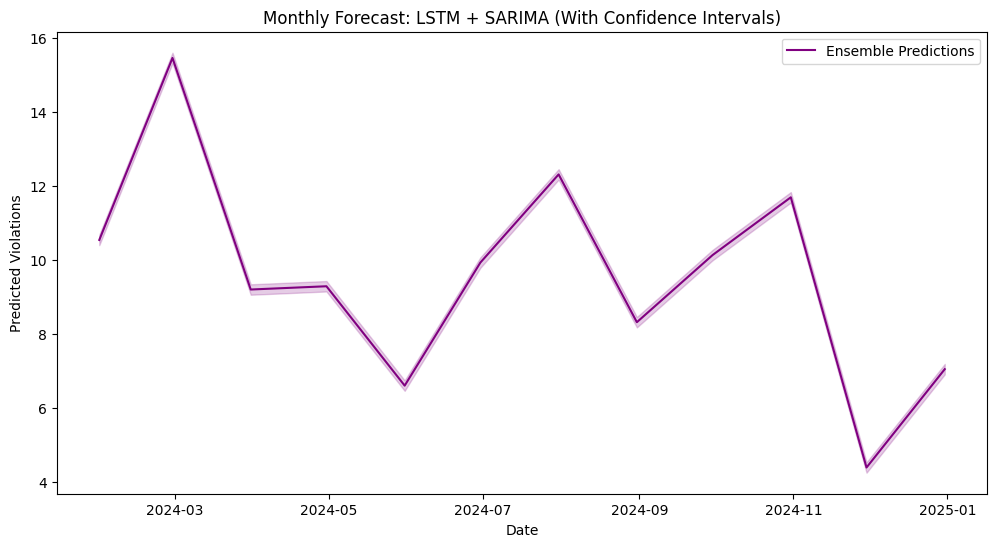

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 🔹 Step 1: Load & Aggregate Data Monthly
time_series_data = master_dataset.groupby("Date").size().reset_index(name="Violation Count")
time_series_data["Date"] = pd.to_datetime(time_series_data["Date"])
time_series_data.set_index("Date", inplace=True)

# Aggregate data to monthly level
time_series_data = time_series_data.resample("M").sum()

# 🔹 Step 2: Normalize Data
scaler = MinMaxScaler(feature_range=(0, 1))
time_series_data["Scaled_Violations"] = scaler.fit_transform(time_series_data[["Violation Count"]])

# 🔹 Step 3: Create Sequences for LSTM
def create_sequences(data, seq_length=12):  # Using past 12 months for prediction
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
        y.append(data.iloc[i+seq_length]["Scaled_Violations"])
    return np.array(X), np.array(y)

sequence_length = 12  # Use past 12 months
features = ["Scaled_Violations"]
X, y = create_sequences(time_series_data[features], sequence_length)

# Split data into training (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Reshape for LSTM
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], len(features)))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], len(features)))

# 🔹 Step 4: Define LSTM Model
model_lstm = Sequential([
    LSTM(100, activation='relu', return_sequences=True, input_shape=(sequence_length, len(features))),
    LSTM(50, activation='relu'),
    Dense(1)
])

# Compile Model
model_lstm.compile(optimizer='adam', loss='mse')

# Train with Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_lstm.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)

# 🔹 Step 5: SARIMA Model with Optimized Hyperparameters
sarima_model = SARIMAX(time_series_data["Violation Count"],
                       order=(2, 1, 2),  # Tuned parameters
                       seasonal_order=(1, 1, 1, 12),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_fit = sarima_model.fit()

# 🔹 Step 6: Forecast Future Violations
forecast_steps = 12  # Predicting next 12 months
sarima_forecast = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean
sarima_forecast_index = pd.date_range(start=time_series_data.index[-1] + pd.Timedelta(days=30), periods=forecast_steps, freq="M")
sarima_forecast_df = pd.DataFrame(sarima_forecast.values, index=sarima_forecast_index, columns=["SARIMA_Predictions"])

# 🔹 Step 7: Generate LSTM Predictions
X_input = np.array(X_test[-1]).reshape(1, sequence_length, len(features)).astype("float32")
lstm_forecast = []

for _ in range(forecast_steps):
    y_pred = model_lstm.predict(X_input)
    lstm_forecast.append(y_pred[0, 0])

    # Update input sequence
    X_input = np.roll(X_input, shift=-1, axis=1)
    X_input[0, -1, 0] = y_pred[0, 0]

# Convert LSTM Predictions to DataFrame
lstm_forecast_df = pd.DataFrame(lstm_forecast, index=sarima_forecast_index, columns=["LSTM_Predictions"])

# 🔹 Step 8: Convert LSTM Predictions Back to Original Scale
lstm_forecast_actual = scaler.inverse_transform(lstm_forecast_df)
lstm_forecast_df["LSTM_Predictions"] = lstm_forecast_actual

# 🔹 Step 9: Combine LSTM & SARIMA (Ensemble)
ensemble_forecast_lst = (0.6 * lstm_forecast_df["LSTM_Predictions"]) + (0.4 * sarima_forecast_df["SARIMA_Predictions"])

# Create ensemble results DataFrame
ensemble_results_lst = pd.DataFrame({
    "LSTM_Predictions": lstm_forecast_df["LSTM_Predictions"].values,
    "SARIMA_Predictions": sarima_forecast_df["SARIMA_Predictions"].values,
    "Ensemble_Predictions": ensemble_forecast_lst.values
}, index=sarima_forecast_index)

# 🔹 Step 10: Compute Confidence Intervals
rmse_ensemble = np.sqrt(mean_squared_error(y_test, model_lstm.predict(X_test)))
ensemble_results_lst["Lower Bound (95%)"] = ensemble_results_lst["Ensemble_Predictions"] - (1.96 * rmse_ensemble)
ensemble_results_lst["Upper Bound (95%)"] = ensemble_results_lst["Ensemble_Predictions"] + (1.96 * rmse_ensemble)
ensemble_results_lst["Lower Bound (95%)"] = ensemble_results_lst["Lower Bound (95%)"].clip(lower=0)  # No negative values

# Display results
print(ensemble_results.head())

# 🔹 Step 11: Plot Results
plt.figure(figsize=(12, 6))
plt.plot(ensemble_results.index, ensemble_results["Ensemble_Predictions"], label="Ensemble Predictions", color="purple")
plt.fill_between(ensemble_results.index, ensemble_results["Lower Bound (95%)"], ensemble_results["Upper Bound (95%)"], color="purple", alpha=0.2)
plt.title("Monthly Forecast: LSTM + SARIMA (With Confidence Intervals)")
plt.xlabel("Date")
plt.ylabel("Predicted Violations")
plt.legend()
plt.show()




In [ ]:
# Compute MAE and RMSE for model performance during training

# Predictions on training and test sets
train_predictions = model_lstm.predict(X_train).flatten()
test_predictions = model_lstm.predict(X_test).flatten()

# Compute Mean Absolute Error (MAE)
mae_train = mean_absolute_error(y_train, train_predictions)
mae_test = mean_absolute_error(y_test, test_predictions)

# Compute Root Mean Squared Error (RMSE)
rmse_train = np.sqrt(mean_squared_error(y_train, train_predictions))
rmse_test = np.sqrt(mean_squared_error(y_test, test_predictions))

# Print MAE and RMSE for training and test sets
print(f"Training MAE: {mae_train:.4f}, RMSE: {rmse_train:.4f}")
print(f"Testing MAE: {mae_test:.4f}, RMSE: {rmse_test:.4f}")

# Display evaluation metrics
evaluation_metrics = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Training Value": [mae_train, rmse_train],
    "Testing Value": [mae_test, rmse_test]
})



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Training MAE: 0.1328, RMSE: 0.1794
Testing MAE: 0.0602, RMSE: 0.0720


##Trying new things

In [ ]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Aggregate violations per date
time_series_data = master_dataset.groupby("Date").size().reset_index(name="Violation Count")

# Set date as index and ensure regular frequency for SARIMA
time_series_data = time_series_data.set_index("Date").asfreq("D").fillna(0)

# Function to create sequences for RNN
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
        y.append(data.iloc[i+seq_length]["Violation Count"])
    return np.array(X), np.array(y)

# Prepare dataset
sequence_length = 30  # Using past 30 days for prediction
X, y = create_sequences(time_series_data[["Violation Count"]], sequence_length)

# Split data into train (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Ensure X_test has the correct shape
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Define RNN Model
model_rnn = Sequential([
    SimpleRNN(50, activation='relu', return_sequences=True, input_shape=(sequence_length, 1)),
    SimpleRNN(50, activation='relu'),
    Dense(1)
])

# Compile Model
model_rnn.compile(optimizer='adam', loss='mse')

# Train with early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_rnn.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)

# Train SARIMA Model
sarima_model = SARIMAX(time_series_data["Violation Count"],
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 12),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_fit = sarima_model.fit()

# Forecast using SARIMA
forecast_steps = 90  # Forecasting 3 months ahead
sarima_forecast = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean

# Generate correct future index
sarima_forecast_index = pd.date_range(start=time_series_data.index[-1] + pd.Timedelta(days=1), periods=forecast_steps, freq="D")

# Convert SARIMA predictions into DataFrame
sarima_forecast_df = pd.DataFrame(sarima_forecast.values, index=sarima_forecast_index, columns=["SARIMA_Predictions"])

# Initialize X_input with last training sequence
X_input = np.array(X_test[-1]).reshape(1, sequence_length, 1).astype("float32")

# Store RNN predictions
rnn_forecast = []

for _ in range(forecast_steps):
    y_pred = model_rnn.predict(X_input)
    rnn_forecast.append(y_pred[0, 0])

    # Update input sequence
    X_input = np.roll(X_input, shift=-1, axis=1)
    X_input[0, -1, 0] = y_pred[0, 0]

# Convert RNN predictions into DataFrame
rnn_forecast_df = pd.DataFrame(rnn_forecast, index=sarima_forecast_index, columns=["RNN_Predictions"])

# Combine RNN and SARIMA into an ensemble forecast
ensemble_forecast = (0.5 * rnn_forecast_df["RNN_Predictions"]) + (0.5 * sarima_forecast_df["SARIMA_Predictions"])

# Create ensemble results DataFrame
ensemble_results = pd.DataFrame({
    "RNN_Predictions": rnn_forecast_df["RNN_Predictions"].values,
    "SARIMA_Predictions": sarima_forecast_df["SARIMA_Predictions"].values,
    "Ensemble_Predictions": ensemble_forecast.values
}, index=sarima_forecast_index)

# Compute Historical Average for Early Warnings
historical_avg = time_series_data["Violation Count"].mean()
threshold_1 = historical_avg * 1.2  # Moderate risk threshold (20% increase)
threshold_2 = historical_avg * 1.5  # High risk threshold (50% increase)
threshold_3 = historical_avg * 2.0  # Critical risk threshold (100% increase)

# Generate Early Warning Labels
def generate_warning(value):
    if value >= threshold_3:
        return "❗ CRITICAL RISK: Expected large-scale human rights violations."
    elif value >= threshold_2:
        return "🚨 HIGH RISK: NGOs should prepare response measures."
    elif value >= threshold_1:
        return "⚠️ MODERATE RISK: Increased violations likely."
    else:
        return "✅ NORMAL: No significant increase detected."

# Apply warning system to predictions
ensemble_results["Warning Level"] = ensemble_results["Ensemble_Predictions"].apply(generate_warning)

# Display final results
print(ensemble_results.head())


#Statistical Tests

In [ ]:
master_dataset_copy.head()

,Country,Date,Group violated,Threat,Type of violation,Description (negative/positive development),Link,Seasonality,Year
0,Tanzania,2020-08-12,media,censorship,Expression,Tanzania has has silenced media coverage of th...,Tanzania has has silenced media coverage of th...,Election Season,2020
1,SouthSudan,2020-07-25,Activist,"Abducted, Killed",Association,Prominent South Sudanese activist Peter Biar A...,https://apnews.com/6fe70274d5f5af7f2d6f03764f8...,General Violation,2020
2,Uganda,2020-08-30,comedians,censorship,Expression,Ugandan comedians fear regulations will destro...,Ugandan comedians fear regulations will destro...,General Violation,2020
4,Ethiopia,2020-08-11,Protestors,Killed,Peaceful Assembly,At least 17 people have been killed during dif...,http://addisstandard.com/update-wolaita-people...,Protest Season,2020
5,Rwanda,2020-08-14,lecturer,censorship,Expression,A computer science lecturer was dismissed by t...,https://www.washingtonpost.com/world/africa/3-...,General Violation,2020


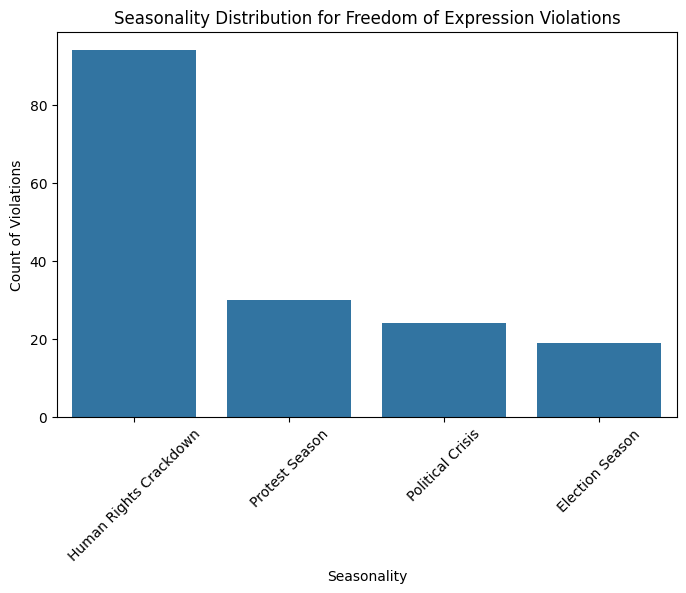

In [ ]:
from sklearn.preprocessing import LabelEncoder

df=master_dataset_copy.copy()

expression_violations_filtered = df[
    (df["Type of violation"] == "Expression") & (df["Seasonality"] != "General Violation")
]

# Count occurrences of "Expression" violations per season
expression_season_count = expression_violations_filtered["Seasonality"].value_counts()

# Plot the distribution of "Expression" violations across seasons
plt.figure(figsize=(8, 5))
sns.barplot(x=expression_season_count.index, y=expression_season_count.values)
plt.title("Seasonality Distribution for Freedom of Expression Violations")
plt.xlabel("Seasonality")
plt.ylabel("Count of Violations")
plt.xticks(rotation=45)
plt.show()

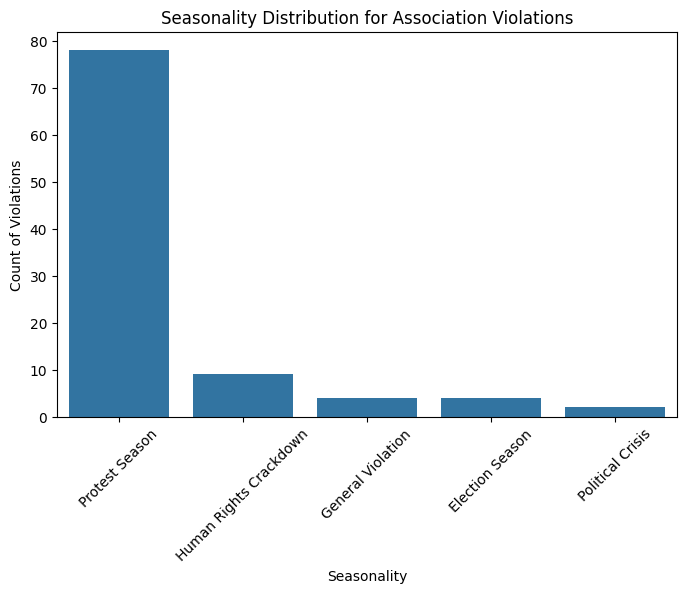

In [ ]:
# Filter dataset for "Expression" violations

expression_violations_filtered = df[
    (df["Type of violation"] == "Association") & (df["Seasonality"] != "General Violation")
]
# Count occurrences of "Expression" violations per season
expression_season_count = expression_violations["Seasonality"].value_counts()

# Plot the distribution of "Expression" violations across seasons
plt.figure(figsize=(8, 5))
sns.barplot(x=expression_season_count.index, y=expression_season_count.values)
plt.title("Seasonality Distribution for Association Violations")
plt.xlabel("Seasonality")
plt.ylabel("Count of Violations")
plt.xticks(rotation=45)
plt.show()

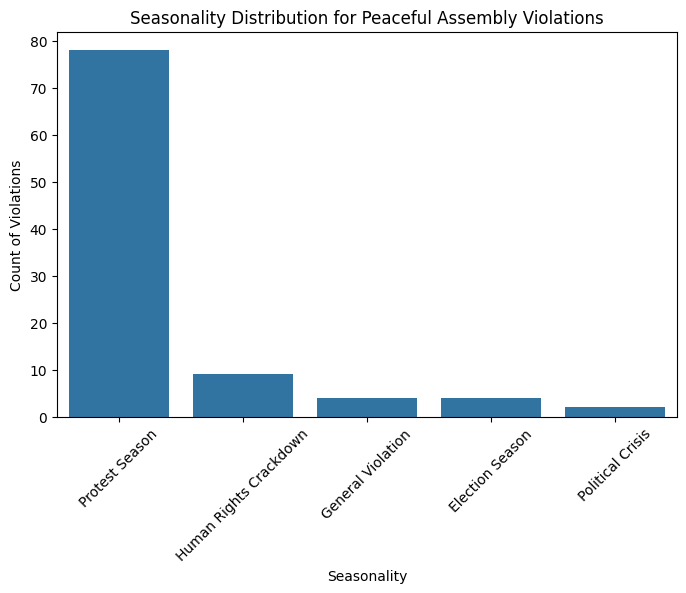

In [ ]:
# Filter dataset for "Expression" violations
expression_violations_filtered = df[
    (df["Type of violation"] == "Peaceful Assembly") & (df["Seasonality"] != "General Violation")
]
# Count occurrences of "Expression" violations per season
expression_season_count = expression_violations["Seasonality"].value_counts()

# Plot the distribution of "Expression" violations across seasons
plt.figure(figsize=(8, 5))
sns.barplot(x=expression_season_count.index, y=expression_season_count.values)
plt.title("Seasonality Distribution for Peaceful Assembly Violations")
plt.xlabel("Seasonality")
plt.ylabel("Count of Violations")
plt.xticks(rotation=45)
plt.show()

In [ ]:
time_series_data.columns

Index(['Violation Count', 'Scaled_Violations', 'Election_Season',
       'Protest_Season', 'Policy_Change', 'Scaled_Election_Season',
       'Scaled_Protest_Season', 'Scaled_Policy_Change', 'Year', 'Month'],
      dtype='object')

In [ ]:
# Convert Date column to datetime format
time_series_data["Date"] = pd.to_datetime(master_dataset["Date"], errors="coerce")

# Set Date as index and sort it
master_dataset = master_dataset.set_index("Date").sort_index()

# Identify and aggregate duplicate dates by summing numerical values
master_dataset = master_dataset.groupby(master_dataset.index).sum()

# Ensure daily frequency and fill missing days with 0 violations
master_dataset = master_dataset.asfreq("D").fillna(0)

# Add seasonal indicators
master_dataset["Election_Season"] = master_dataset.index.month.isin([7, 8]).astype(int)
master_dataset["Protest_Season"] = master_dataset.index.month.isin([3, 5, 10]).astype(int)
master_dataset["Policy_Change"] = master_dataset.index.strftime('%Y-%m').isin(["2021-06", "2022-04"]).astype(int)

# Normalize Data
scaler = MinMaxScaler(feature_range=(0, 1))
master_dataset["Scaled_Violations"] = scaler.fit_transform(master_dataset[["Violation Count"]])

scaler_season = MinMaxScaler(feature_range=(0, 1))
master_dataset["Scaled_Election_Season"] = scaler_season.fit_transform(dmaster_dataset[["Election_Season"]])

scaler_protest = MinMaxScaler(feature_range=(0, 1))
master_dataset["Scaled_Protest_Season"] = scaler_protest.fit_transform(master_dataset[["Protest_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
master_dataset["Scaled_Policy_Change"] = scaler_policy.fit_transform(master_dataset[["Policy_Change"]])

# Load ensemble forecast results (Ensure the file is available)
ensemble_results = pd.read_csv("ensemble_forecast.csv")

# Convert ensemble forecast 'Date' column to datetime
ensemble_results["Date"] = pd.to_datetime(ensemble_results["Date"], errors="coerce")

# Set Date as index
ensemble_results = ensemble_results.set_index("Date")

# Merge both datasets on the date index
merged_df = df.merge(ensemble_results, left_index=True, right_index=True, how="inner")

# Compute Pearson correlation
correlation_matrix = merged_df.corr()

# Extract correlations of 'Ensemble_Predictions' with seasonal factors
seasonality_correlation = correlation_matrix.loc["Ensemble_Predictions",
                                                  ["Scaled_Election_Season",
                                                   "Scaled_Protest_Season",
                                                   "Scaled_Policy_Change"]]

# Display results
print(seasonality_correlation)



KeyError: 'Date'

In [ ]:
policy_violations = time_series_data[time_series_data["Policy_Change"] == 1]["Violation Count"]
non_policy_violations = time_series_data[time_series_data["Policy_Change"] == 0]["Violation Count"]

t_stat, p_value = ttest_ind(policy_violations, non_policy_violations, equal_var=False)
print(f"T-Test for Policy Changes: t-statistic = {t_stat}, p-value = {p_value}")

if p_value < 0.05:
    print("✅ Policy Changes significantly impact violations")
else:
    print("❌ No significant impact of Policy Changes on violations")


T-Test for Policy Changes: t-statistic = nan, p-value = nan
❌ No significant impact of Policy Changes on violations


In [ ]:
protest_violations = time_series_data_2024[time_series_data_2024["Protest_Season"] == 1]["Violation Count"]
non_protest_violations = time_series_data_2024[time_series_data_2024["Protest_Season"] == 0]["Violation Count"]

t_stat, p_value = ttest_ind(protest_violations, non_protest_violations, equal_var=False)
print(f"T-Test for Protest Season: t-statistic = {t_stat}, p-value = {p_value}")

if p_value < 0.05:
    print("✅ Protest Season significantly impacts violations")
else:
    print("❌ No significant impact of Protest Season on violations")


T-Test for Protest Season: t-statistic = -0.37406312830914734, p-value = 0.7087880104099
❌ No significant impact of Protest Season on violations


In [ ]:
import statsmodels.api as sm

# Define independent variables (Election Season, Protest Season, Policy Change)
X = time_series_data_2024[["Election_Season", "Protest_Season", "Policy_Change"]]
X = sm.add_constant(X)  # Add constant for regression

# Dependent variable (Number of Violations)
y = time_series_data_2024["Violation Count"]

# Run regression model
model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:        Violation Count   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.007
Method:                 Least Squares   F-statistic:                    0.2103
Date:                Tue, 04 Feb 2025   Prob (F-statistic):              0.889
Time:                        07:35:54   Log-Likelihood:                -509.13
No. Observations:                 332   AIC:                             1026.
Df Residuals:                     328   BIC:                             1041.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.4830      0.093     

#Testing the model

In [ ]:
master_dataset_2024 = pd.read_excel("/content/drive/MyDrive/Colab Notebooks/Research - Trends/Dataset_with_Seasonality-2.xlsx")

In [ ]:
#check for duplicates
master_dataset_2024.duplicated().sum()

2

In [ ]:
#view the duplicates
master_dataset_2024[master_dataset_2024.duplicated()]

,Country,Date,Group violated,Violation Type,Description,Source URL,Threat,Seasonality
140,Tanzania,2024-10-15,Journalists,Expression,Tanzania‚Äôs regulator bans media outlets as j...,https://cpj.org/2024/10/tanzanias-regulator-ba...,Media harassment,General
141,Ethiopia,2024-10-07,General news,General news,EHRC expresses concern over 'mass arbitrary de...,https://addisstandard.com/ehrc-expresses-conce...,Arbitrary detentions,Government Crackdown


In [ ]:
#check for missing values
master_dataset_2024.isnull().sum()

,0
Country,0
Date,0
Group violated,0
Violation Type,0
Description,0
Source URL,0
Threat,4
Seasonality,0


In [ ]:
# Assuming 'master_dataset' is your DataFrame
master_dataset_2024 = master_dataset_2024.dropna(subset=['Threat'])

master_dataset_2024.isnull().sum()


,0
Country,0
Date,0
Group violated,0
Violation Type,0
Description,0
Source URL,0
Threat,0
Seasonality,0


In [ ]:
#Type of violation
master_dataset_2024['Violation Type'].replace('freedom of expression','Expression',inplace=True)
master_dataset_2024['Violation Type'].replace('Freedom of peaceful expression','Expression',inplace=True)
master_dataset_2024['Violation Type'].replace('expression','Expression',inplace=True)
master_dataset_2024['Violation Type'].replace('Freedom of expresssion','Expression',inplace=True)
master_dataset_2024['Violation Type'].replace('Freedom of expression','Expression',inplace=True)
master_dataset_2024['Violation Type'].replace('freeedom of association','Association',inplace=True)
master_dataset_2024['Violation Type'].replace('freedom of association','Association',inplace=True)
master_dataset_2024['Violation Type'].replace('Freeedom of association','Association',inplace=True)
master_dataset_2024['Violation Type'].replace('Freedom of association','Association',inplace=True)
master_dataset_2024['Violation Type'].replace('Freedom of assembly','Peaceful Assembly',inplace=True)
master_dataset_2024['Violation Type'].replace('Peaceful assembly','Peaceful Assembly',inplace=True)
master_dataset_2024['Violation Type'].replace('General news','General',inplace=True)
master_dataset_2024['Violation Type'].replace('General information','General',inplace=True)
master_dataset_2024['Violation Type'].replace('Access to Information','Expression',inplace=True)

<ipython-input-40-58319d349ce2>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset_2024['Violation Type'].replace('freedom of expression','Expression',inplace=True)
<ipython-input-40-58319d349ce2>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing

In [ ]:
#Group violated
master_dataset_2024['Group violated'].replace('journalist','Journalist',inplace=True)
master_dataset_2024['Group violated'].replace('journalists','Journalist',inplace=True)
master_dataset_2024['Group violated'].replace('Journalists','Journalist',inplace=True)
master_dataset_2024['Group violated'].replace('protesters','Protesters',inplace=True)
master_dataset_2024['Group violated'].replace('protestors','Protesters',inplace=True)
master_dataset_2024['Group violated'].replace('Oposition','Opposition',inplace=True)
master_dataset_2024['Group violated'].replace('Opposition leaders','Opposition',inplace=True)
master_dataset_2024['Group violated'].replace('opposition leaders','Opposition',inplace=True)
master_dataset_2024['Group violated'].replace('Opposition politicians','Opposition',inplace=True)
master_dataset_2024['Group violated'].replace('Opposition ','Opposition',inplace=True)
master_dataset_2024['Group violated'].replace('opposition','Opposition',inplace=True)

<ipython-input-41-6a92ff6bdb8b>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset_2024['Group violated'].replace('journalist','Journalist',inplace=True)
<ipython-input-41-6a92ff6bdb8b>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].m

In [ ]:
#Threat
master_dataset_2024['Threat'].replace('arbitrary arrest','Arbitrary arrest',inplace=True)
master_dataset_2024['Threat'].replace('aritrary arrest','Arbitrary arrest',inplace=True)
master_dataset_2024['Threat'].replace('Aritrary arrest','Arbitrary arrest',inplace=True)
master_dataset_2024['Threat'].replace('arbitrary detention','Arbitrary detention',inplace=True)

<ipython-input-42-ab7b81f32973>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  master_dataset_2024['Threat'].replace('arbitrary arrest','Arbitrary arrest',inplace=True)
<ipython-input-42-ab7b81f32973>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[co

In [ ]:
master_dataset_2024.columns

Index(['Country', 'Date', 'Group violated', 'Violation Type', 'Description',
       'Source URL', 'Threat', 'Seasonality'],
      dtype='object')

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import load_model

# Sort and Aggregate violations per date
master_dataset_2024["Date"] = pd.to_datetime(master_dataset_2024["Date"], infer_datetime_format=True, errors="coerce")

master_dataset_2024 = master_dataset_2024[master_dataset_2024["Date"].dt.year == 2024]

master_dataset_2024 = master_dataset_2024.sort_values(by="Date")
time_series_data_2024 = master_dataset_2024.groupby("Date").size().reset_index(name="Violation Count")

# Set Date as index
time_series_data_2024 = time_series_data_2024.set_index("Date").sort_index()

# Ensure daily frequency and fill missing days with 0 violations
time_series_data_2024 = time_series_data_2024.asfreq("D").fillna(0)

# Display the first few rows
print(time_series_data_2024.head())

            Violation Count
Date                       
2024-01-05              2.0
2024-01-06              0.0
2024-01-07              0.0
2024-01-08              0.0
2024-01-09              0.0


<ipython-input-44-103f4df1d64c>:5: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  master_dataset_2024["Date"] = pd.to_datetime(master_dataset_2024["Date"], infer_datetime_format=True, errors="coerce")


In [ ]:
time_series_data.columns

Index(['Violation Count', 'Scaled_Violations', 'Election_Season',
       'Protest_Season', 'Policy_Change', 'Scaled_Election_Season',
       'Scaled_Protest_Season', 'Scaled_Policy_Change'],
      dtype='object')

In [ ]:
time_series_data_2024.columns

Index(['Violation Count'], dtype='object')

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Ensure that "Violation Count" is properly scaled
scaler = MinMaxScaler(feature_range=(0, 1))

# Check if the column exists before scaling
if "Violation Count" in time_series_data_2024.columns:
    time_series_data_2024["Scaled_Violations"] = scaler.fit_transform(time_series_data_2024[["Violation Count"]])
else:
    raise KeyError("Column 'Violation Count' not found in dataset!")

# Add an "Election Season" binary feature (Example: elections occur in July & August)
time_series_data_2024["Election_Season"] = time_series_data_2024.index.month.isin([7, 8]).astype(int)
time_series_data_2024["Protest_Season"] = time_series_data_2024.index.month.isin([3, 5, 10]).astype(int)
time_series_data_2024["Policy_Change"] = time_series_data_2024.index.strftime('%Y-%m').isin(["2021-06", "2022-04"]).astype(int)


# Normalize Data (RNNs work best with scaled data)
scaler = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Violations"] = scaler.fit_transform(time_series_data_2024[["Violation Count"]])

# Normalize the election season variable separately (optional, but recommended)
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data_2024[["Election_Season"]])

scaler_protest = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Protest_Season"] = scaler_protest.fit_transform(time_series_data_2024[["Protest_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data_2024[["Policy_Change"]])


# ✅ Check if "Scaled_Violations" was created successfully
print(time_series_data_2024.head())

# Create sequences for LSTM (using past 30 days to predict the next day)
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

# Convert 2024 data to sequences
#sequence_length = 30  # Using past 30 days for prediction
#X_2024, y_2024 = create_sequences(time_series_data_2024["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"].values, sequence_length)

# Prepare dataset with both features (Scaled_Violations & Scaled_Election_Season)
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]

# Verify if features exist in `time_series_data_2024`
missing_features = [col for col in features if col not in time_series_data_2024.columns]
if missing_features:
    raise KeyError(f"Missing features in time_series_data_2024: {missing_features}")

# Define function to create sequences for RNN
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)  # ✅ Use .iloc for multi-column selection
        y.append(data.iloc[i+seq_length].values[0])  # ✅ Predicting only "Scaled_Violations"
    return np.array(X), np.array(y)

# Convert 2024 data to sequences (Correcting feature selection)
sequence_length = 30  # Use past 30 days for prediction
X_2024, y_2024 = create_sequences(time_series_data_2024.loc[:, features], sequence_length)  # ✅ FIXED

# Print shape of input data to confirm correctness
print(f"X_2024 shape: {X_2024.shape}")  # Should be (samples, 30, 4)

# Reshape for RNN (samples, timesteps, features)
X_2024 = X_2024.reshape((X_2024.shape[0], X_2024.shape[1], len(features)))  # ✅ Now matches model input shape


            Violation Count  Scaled_Violations  Election_Season  \
Date                                                              
2024-01-05              2.0                0.2                0   
2024-01-06              0.0                0.0                0   
2024-01-07              0.0                0.0                0   
2024-01-08              0.0                0.0                0   
2024-01-09              0.0                0.0                0   

            Protest_Season  Policy_Change  Scaled_Election_Season  \
Date                                                                
2024-01-05               0              0                     0.0   
2024-01-06               0              0                     0.0   
2024-01-07               0              0                     0.0   
2024-01-08               0              0                     0.0   
2024-01-09               0              0                     0.0   

            Scaled_Protest_Season  Scaled_Poli

In [ ]:
print(f"X_2024 shape: {X_2024.shape}")
print(f"Model expected input shape: {model.input_shape}")


X_2024 shape: (302, 30, 4)
Model expected input shape: (None, None, 1)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


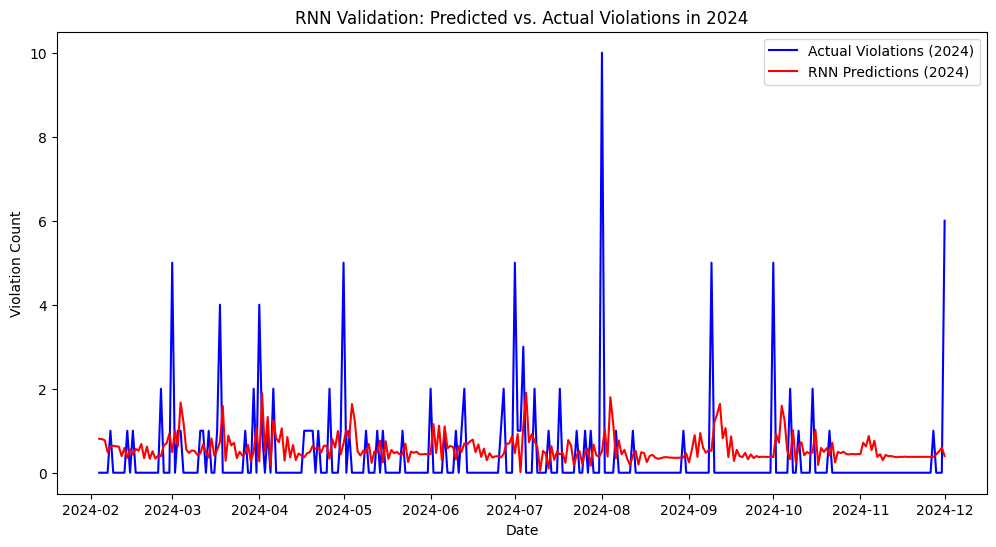

In [ ]:
# Predict using the trained LSTM model
y_pred_2024 = model_rnn.predict(X_2024)

# Reverse scaling to get actual values
y_pred_actual_2024 = scaler.inverse_transform(y_pred_2024.reshape(-1, 1))
y_actual_2024 = scaler.inverse_transform(y_2024.reshape(-1, 1))

# Plot actual vs predicted violations in 2024
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_pred_actual_2024, label="RNN Predictions (2024)", color="red")
plt.title("RNN Validation: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step


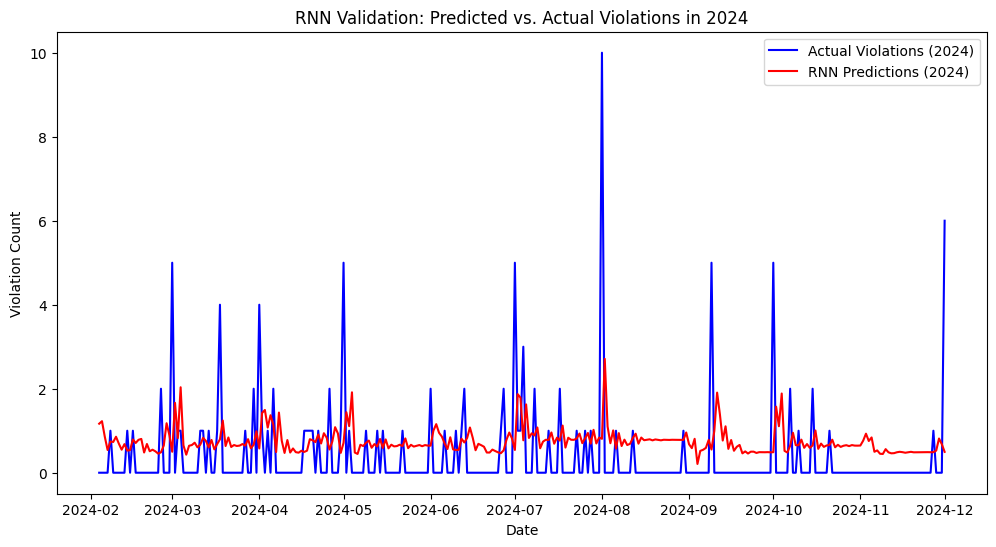

In [ ]:
# Predict using the trained LSTM model
y_pred_2024 = model_rnn.predict(X_2024)

# Reverse scaling to get actual values
y_pred_actual_2024 = scaler.inverse_transform(y_pred_2024.reshape(-1, 1))
y_actual_2024 = scaler.inverse_transform(y_2024.reshape(-1, 1))

# Plot actual vs predicted violations in 2024
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_pred_actual_2024, label="RNN Predictions (2024)", color="red")
plt.title("RNN Validation: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step  


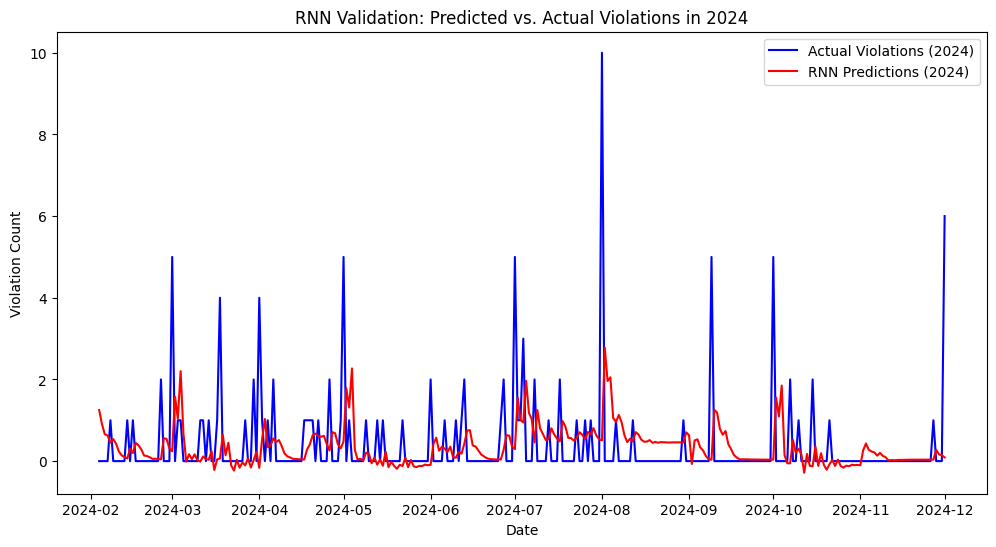

In [ ]:
# Predict using the trained LSTM model
y_pred_2024 = model_rnn.predict(X_2024)

# Reverse scaling to get actual values
y_pred_actual_2024 = scaler.inverse_transform(y_pred_2024.reshape(-1, 1))
y_actual_2024 = scaler.inverse_transform(y_2024.reshape(-1, 1))

# Plot actual vs predicted violations in 2024
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_pred_actual_2024, label="RNN Predictions (2024)", color="red")
plt.title("RNN Validation: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE and RMSE
mae_lstm_2024 = mean_absolute_error(y_actual_2024, y_pred_actual_2024)
rmse_lstm_2024 = np.sqrt(mean_squared_error(y_actual_2024, y_pred_actual_2024))

print(f"RNN Mean Absolute Error (MAE) on 2024: {mae_lstm_2024}")
print(f"RNN Root Mean Squared Error (RMSE) on 2024: {rmse_lstm_2024}")


RNN Mean Absolute Error (MAE) on 2024: 0.7379774736450208
RNN Root Mean Squared Error (RMSE) on 2024: 1.1245594036054476


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE and RMSE
mae_lstm_2024 = mean_absolute_error(y_actual_2024, y_pred_actual_2024)
rmse_lstm_2024 = np.sqrt(mean_squared_error(y_actual_2024, y_pred_actual_2024))

print(f"RNN Mean Absolute Error (MAE) on 2024: {mae_lstm_2024}")
print(f"RNN Root Mean Squared Error (RMSE) on 2024: {rmse_lstm_2024}")


RNN Mean Absolute Error (MAE) on 2024: 0.6248006822220635
RNN Root Mean Squared Error (RMSE) on 2024: 1.1739483715070942


In [ ]:
master_dataset_2024.head()

,Country,Date,Group violated,Violation Type,Description,Source URL,Threat,Seasonality
5,Uganda,2024-01-05,NGOs,Freedom of Association,NGO Bureau dissolved; NGO Act 2024 centralized...,https://monitor.co.ug/uganda/news/national/ant...,Centralized NGO oversight,General
16,Uganda,2024-01-05,NGOs,Freedom of Association,NGO Bureau dissolved; NGO Act 2024 centralized...,MonitorUganda,Centralized NGO oversight,General
0,Djibouti,2024-01-10,Journalist,Freedom of Expression,Harassment of journalist Kadar Abdi Ibrahim; P...,https://defenddefenders.org/oral-statements-hr...,"Passport confiscation, harassment",General
11,Djibouti,2024-01-10,Journalist,Freedom of Expression,Harassment of journalist Kadar Abdi Ibrahim; P...,DefendDefenders,"Passport confiscation, harassment",General
23,Ethiopia,2024-01-12,HRDs,Freedom of Expression,Government security forces and intelligence pe...,FrontLineDefenders,"Harassment, intimidation",General


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


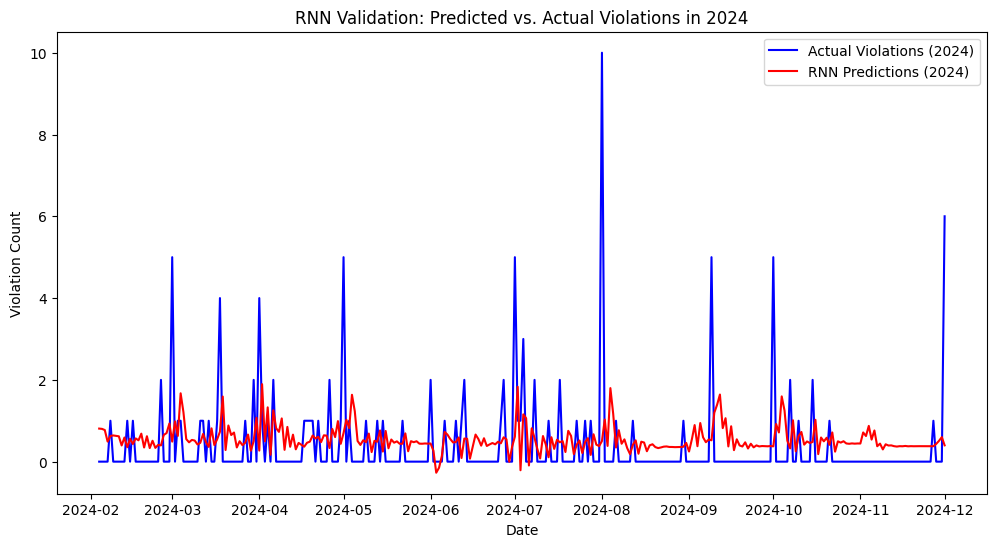

                           Metric     Value
0       Mean Absolute Error (MAE)  0.717183
1  Root Mean Squared Error (RMSE)  1.119768


In [ ]:
# 3️⃣ **Sort data by date**
master_dataset_2024 = master_dataset_2024.sort_values(by="Date")

# 4️⃣ **Aggregate violations per date**
time_series_data_2024 = master_dataset_2024.groupby("Date").size().reset_index(name="Violation Count")

# 5️⃣ **Set Date as index and ensure it's sorted**
time_series_data_2024 = time_series_data_2024.set_index("Date").sort_index()

# 6️⃣ **Ensure daily frequency and fill missing days with 0 violations**
time_series_data_2024 = time_series_data_2024.asfreq("D").fillna(0)

# 7️⃣ **Add Election Season and Policy Change Features**
time_series_data_2024["Election_Season"] = time_series_data_2024.index.month.isin([7, 8]).astype(int)
time_series_data_2024["Policy_Change"] = time_series_data_2024.index.strftime('%Y-%m').isin(["2024-06"]).astype(int)  # Example policy change
time_series_data_2024["Protest_Season"] = time_series_data_2024.index.month.isin([3, 5, 10]).astype(int)

# 8️⃣ **Normalize the 2024 Data Using the Same Scaler**
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(time_series_data_2024[["Violation Count"]])  # Fit on training data (2020-2023)

time_series_data_2024["Scaled_Violations"] = scaler.transform(time_series_data_2024[["Violation Count"]])

# Normalize Election Season and Policy Change
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data_2024[["Election_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data_2024[["Policy_Change"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Protest_Season"] = scaler_policy.fit_transform(time_series_data_2024[["Protest_Season"]])


# 9️⃣ **Create Sequences for Testing on 2024 Data**
def create_sequences(data, seq_length=30):
    X = []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
    return np.array(X)

# Prepare dataset with both features (Scaled_Violations & Scaled_Election_Season & Scaled_Policy_Change)
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]
sequence_length = 30  # Use past 30 days for prediction
X_2024 = create_sequences(time_series_data_2024[features], sequence_length)

# Reshape for RNN (samples, timesteps, features)
X_2024 = X_2024.reshape((X_2024.shape[0], X_2024.shape[1], len(features)))

# 1️⃣1️⃣ **Make Predictions for 2024**
y_pred_2024 = model_rnn.predict(X_2024)


# 1️⃣2️⃣ **Reverse Scaling to Get Actual Values**
y_pred_actual_2024 = scaler.inverse_transform(y_pred_2024.reshape(-1, 1))

# 1️⃣3️⃣ **Extract Actual Values from 2024 for Comparison**
y_actual_2024 = time_series_data_2024["Violation Count"].values[sequence_length:]

# 1️⃣4️⃣ **Plot Actual vs Predicted Violations in 2024**
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_pred_actual_2024, label="RNN Predictions (2024)", color="red")
plt.title("RNN Validation: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 1️⃣5️⃣ **Evaluate the Model on 2024 Data**
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_rnn_2024 = mean_absolute_error(y_actual_2024, y_pred_actual_2024)
rmse_rnn_2024 = np.sqrt(mean_squared_error(y_actual_2024, y_pred_actual_2024))

# 1️⃣6️⃣ **Display the Accuracy Results**
accuracy_results_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_rnn_2024, rmse_rnn_2024]
})

# Print results
print(accuracy_results_2024)


In [ ]:
print(f"X_2024 shape: {X_2024.shape}")
print(f"Model expected input shape: {model.input_shape}")


X_2024 shape: (302, 30, 4)
Model expected input shape: (None, None, 1)


In [ ]:
print(time_series_data_2024.columns)

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_pred_actual_2024, label="RNN Predictions (2024)", color="red")
plt.title("RNN Validation: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.xlim(["01-01-2024", "31-12-2024"])  # Ensure correct date range
plt.legend()
plt.show()


In [ ]:
print(time_series_data_2024.index)


#combi

In [ ]:
time_series_data_2024.columns

NameError: name 'time_series_data_2024' is not defined

In [ ]:
time_series_data.columns

Index(['Violation Count', 'Scaled_Violations', 'Election_Season',
       'Protest_Season', 'Policy_Change', 'Scaled_Election_Season',
       'Scaled_Protest_Season', 'Scaled_Policy_Change'],
      dtype='object')

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  


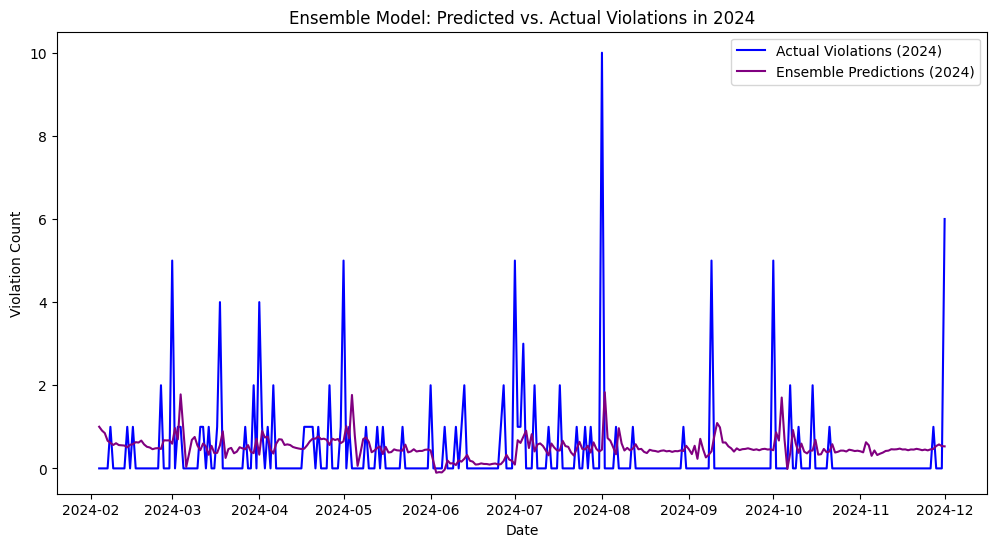

                           Metric     Value
0       Mean Absolute Error (MAE)  0.683809
1  Root Mean Squared Error (RMSE)  1.108680


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1️⃣ **Sort data by date**
master_dataset_2024 = master_dataset_2024.sort_values(by="Date")

# 2️⃣ **Aggregate violations per date**
time_series_data_2024 = master_dataset_2024.groupby("Date").size().reset_index(name="Violation Count")

# 3️⃣ **Set Date as index and ensure it's sorted**
time_series_data_2024 = time_series_data_2024.set_index("Date").sort_index()

# 4️⃣ **Ensure daily frequency and fill missing days with 0 violations**
time_series_data_2024 = time_series_data_2024.asfreq("D").fillna(0)

# 7️⃣ **Add Election Season and Policy Change Features**
time_series_data_2024["Election_Season"] = time_series_data_2024.index.month.isin([7, 8]).astype(int)
time_series_data_2024["Policy_Change"] = time_series_data_2024.index.strftime('%Y-%m').isin(["2024-06"]).astype(int)  # Example policy change
time_series_data_2024["Protest_Season"] = time_series_data_2024.index.month.isin([3, 5, 10]).astype(int)

# 8️⃣ **Normalize the 2024 Data Using the Same Scaler**
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(time_series_data_2024[["Violation Count"]])  # Fit on training data (2020-2023)

time_series_data_2024["Scaled_Violations"] = scaler.transform(time_series_data_2024[["Violation Count"]])

# Normalize Election Season and Policy Change
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data_2024[["Election_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data_2024[["Policy_Change"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Protest_Season"] = scaler_policy.fit_transform(time_series_data_2024[["Protest_Season"]])





# 7️⃣ **Create Sequences for Testing on 2024 Data**
def create_sequences(data, seq_length=30):
    X = []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
    return np.array(X)

# 8️⃣ **Prepare dataset with multiple features**
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]
sequence_length = 30  # Use past 30 days for prediction
X_2024 = create_sequences(time_series_data_2024[features], sequence_length)

# 9️⃣ **Reshape for RNN (samples, timesteps, features)**
X_2024 = X_2024.reshape((X_2024.shape[0], X_2024.shape[1], len(features)))

# 🔟 **Make RNN Predictions for 2024**
rnn_pred_2024 = model_rnn.predict(X_2024)

# 1️⃣1️⃣ **Reverse Scaling to Get Actual RNN Values**
rnn_pred_actual_2024 = scaler.inverse_transform(rnn_pred_2024.reshape(-1, 1))

# 1️⃣2️⃣ **Generate SARIMA Forecast for 2024**
forecast_steps = len(rnn_pred_actual_2024)  # Match RNN prediction steps
sarima_forecast_2024 = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean

# 1️⃣3️⃣ **Create the Ensemble Forecast (RNN + SARIMA)**
ensemble_predictions_2024 = (0.8 * rnn_pred_actual_2024.flatten()) + (0.2 * sarima_forecast_2024.values)

# 1️⃣4️⃣ **Extract Actual Violations from 2024 for Comparison**
y_actual_2024 = time_series_data_2024["Violation Count"].values[sequence_length:sequence_length+forecast_steps]

# 1️⃣5️⃣ **Plot Actual vs. Predicted (Ensemble) Violations in 2024**
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple")
plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 1️⃣6️⃣ **Evaluate the Model on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# 1️⃣7️⃣ **Display the Accuracy Results**
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  


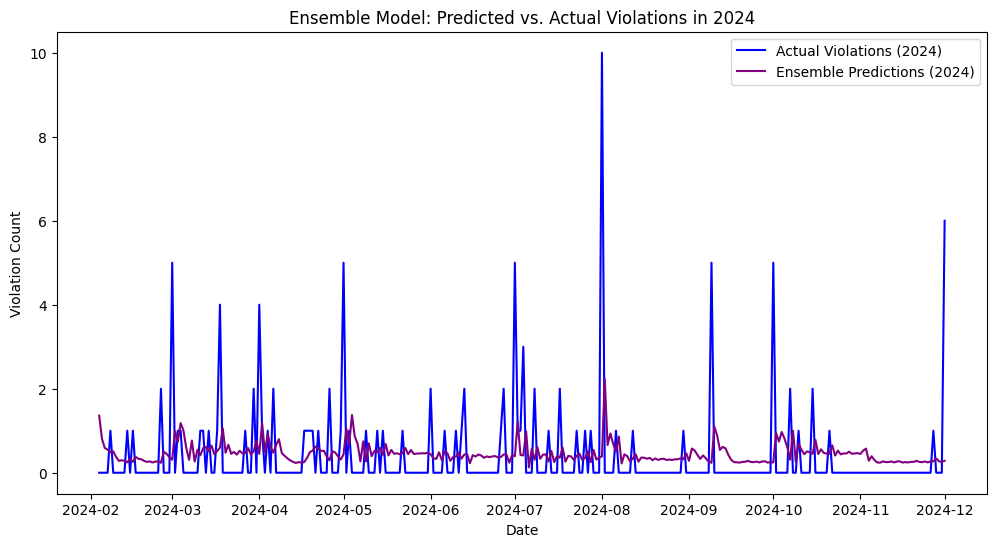

                           Metric     Value
0       Mean Absolute Error (MAE)  0.651428
1  Root Mean Squared Error (RMSE)  1.106207


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1️⃣ **Sort data by date**
master_dataset_2024 = master_dataset_2024.sort_values(by="Date")

# 2️⃣ **Aggregate violations per date**
time_series_data_2024 = master_dataset_2024.groupby("Date").size().reset_index(name="Violation Count")

# 3️⃣ **Set Date as index and ensure it's sorted**
time_series_data_2024 = time_series_data_2024.set_index("Date").sort_index()

# 4️⃣ **Ensure daily frequency and fill missing days with 0 violations**
time_series_data_2024 = time_series_data_2024.asfreq("D").fillna(0)

# 7️⃣ **Add Election Season and Policy Change Features**
time_series_data_2024["Election_Season"] = time_series_data_2024.index.month.isin([7, 8]).astype(int)
time_series_data_2024["Policy_Change"] = time_series_data_2024.index.strftime('%Y-%m').isin(["2024-06"]).astype(int)  # Example policy change
time_series_data_2024["Protest_Season"] = time_series_data_2024.index.month.isin([3, 5, 10]).astype(int)

# 8️⃣ **Normalize the 2024 Data Using the Same Scaler**
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(time_series_data_2024[["Violation Count"]])  # Fit on training data (2020-2023)

time_series_data_2024["Scaled_Violations"] = scaler.transform(time_series_data_2024[["Violation Count"]])

# Normalize Election Season and Policy Change
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data_2024[["Election_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data_2024[["Policy_Change"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Protest_Season"] = scaler_policy.fit_transform(time_series_data_2024[["Protest_Season"]])





# 7️⃣ **Create Sequences for Testing on 2024 Data**
def create_sequences(data, seq_length=30):
    X = []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
    return np.array(X)

# 8️⃣ **Prepare dataset with multiple features**
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]
sequence_length = 30  # Use past 30 days for prediction
X_2024 = create_sequences(time_series_data_2024[features], sequence_length)

# 9️⃣ **Reshape for RNN (samples, timesteps, features)**
X_2024 = X_2024.reshape((X_2024.shape[0], X_2024.shape[1], len(features)))

# 🔟 **Make RNN Predictions for 2024**
rnn_pred_2024 = model_rnn.predict(X_2024)

# 1️⃣1️⃣ **Reverse Scaling to Get Actual RNN Values**
rnn_pred_actual_2024 = scaler.inverse_transform(rnn_pred_2024.reshape(-1, 1))

# 1️⃣2️⃣ **Generate SARIMA Forecast for 2024**
forecast_steps = len(rnn_pred_actual_2024)  # Match RNN prediction steps
sarima_forecast_2024 = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean

# 1️⃣3️⃣ **Create the Ensemble Forecast (RNN + SARIMA)**
ensemble_predictions_2024 = (0.8 * rnn_pred_actual_2024.flatten()) + (0.2 * sarima_forecast_2024.values)

# 1️⃣4️⃣ **Extract Actual Violations from 2024 for Comparison**
y_actual_2024 = time_series_data_2024["Violation Count"].values[sequence_length:sequence_length+forecast_steps]

# 1️⃣5️⃣ **Plot Actual vs. Predicted (Ensemble) Violations in 2024**
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple")
plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 1️⃣6️⃣ **Evaluate the Model on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# 1️⃣7️⃣ **Display the Accuracy Results**
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


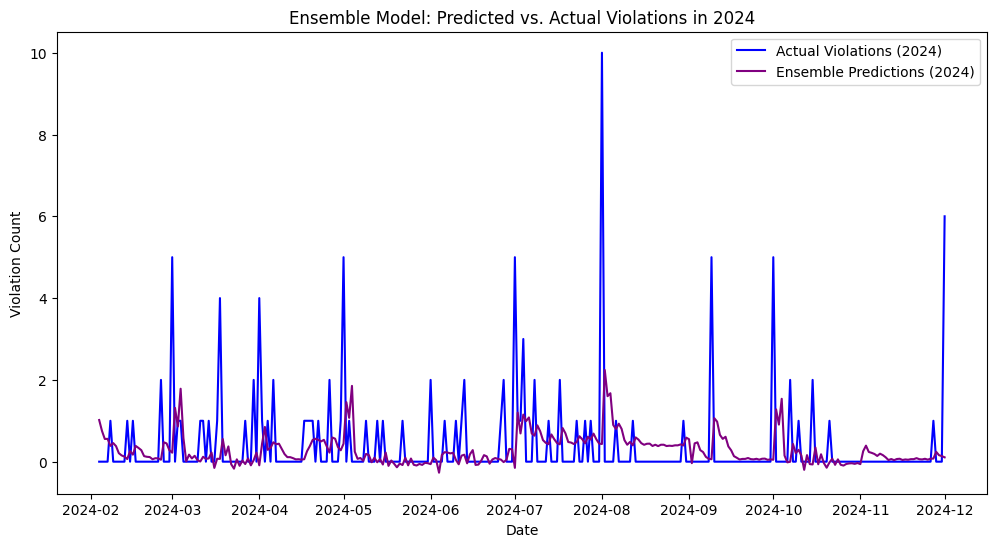

                           Metric     Value
0       Mean Absolute Error (MAE)  0.571938
1  Root Mean Squared Error (RMSE)  1.141068


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1️⃣ **Sort data by date**
master_dataset_2024 = master_dataset_2024.sort_values(by="Date")

# 2️⃣ **Aggregate violations per date**
time_series_data_2024 = master_dataset_2024.groupby("Date").size().reset_index(name="Violation Count")

# 3️⃣ **Set Date as index and ensure it's sorted**
time_series_data_2024 = time_series_data_2024.set_index("Date").sort_index()

# 4️⃣ **Ensure daily frequency and fill missing days with 0 violations**
time_series_data_2024 = time_series_data_2024.asfreq("D").fillna(0)

# 7️⃣ **Add Election Season and Policy Change Features**
time_series_data_2024["Election_Season"] = time_series_data_2024.index.month.isin([7, 8]).astype(int)
time_series_data_2024["Policy_Change"] = time_series_data_2024.index.strftime('%Y-%m').isin(["2024-06"]).astype(int)  # Example policy change
time_series_data_2024["Protest_Season"] = time_series_data_2024.index.month.isin([3, 5, 10]).astype(int)

# 8️⃣ **Normalize the 2024 Data Using the Same Scaler**
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(time_series_data_2024[["Violation Count"]])  # Fit on training data (2020-2023)

time_series_data_2024["Scaled_Violations"] = scaler.transform(time_series_data_2024[["Violation Count"]])

# Normalize Election Season and Policy Change
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data_2024[["Election_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data_2024[["Policy_Change"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Protest_Season"] = scaler_policy.fit_transform(time_series_data_2024[["Protest_Season"]])





# 7️⃣ **Create Sequences for Testing on 2024 Data**
def create_sequences(data, seq_length=30):
    X = []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
    return np.array(X)

# 8️⃣ **Prepare dataset with multiple features**
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]
sequence_length = 30  # Use past 30 days for prediction
X_2024 = create_sequences(time_series_data_2024[features], sequence_length)

# 9️⃣ **Reshape for RNN (samples, timesteps, features)**
X_2024 = X_2024.reshape((X_2024.shape[0], X_2024.shape[1], len(features)))

# 🔟 **Make RNN Predictions for 2024**
rnn_pred_2024 = model_rnn.predict(X_2024)

# 1️⃣1️⃣ **Reverse Scaling to Get Actual RNN Values**
rnn_pred_actual_2024 = scaler.inverse_transform(rnn_pred_2024.reshape(-1, 1))

# 1️⃣2️⃣ **Generate SARIMA Forecast for 2024**
forecast_steps = len(rnn_pred_actual_2024)  # Match RNN prediction steps
sarima_forecast_2024 = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean

# 1️⃣3️⃣ **Create the Ensemble Forecast (RNN + SARIMA)**
ensemble_predictions_2024 = (0.8 * rnn_pred_actual_2024.flatten()) + (0.2 * sarima_forecast_2024.values)

# 1️⃣4️⃣ **Extract Actual Violations from 2024 for Comparison**
y_actual_2024 = time_series_data_2024["Violation Count"].values[sequence_length:sequence_length+forecast_steps]

# 1️⃣5️⃣ **Plot Actual vs. Predicted (Ensemble) Violations in 2024**
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple")
plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 1️⃣6️⃣ **Evaluate the Model on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# 1️⃣7️⃣ **Display the Accuracy Results**
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


# Hypothesis testing

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


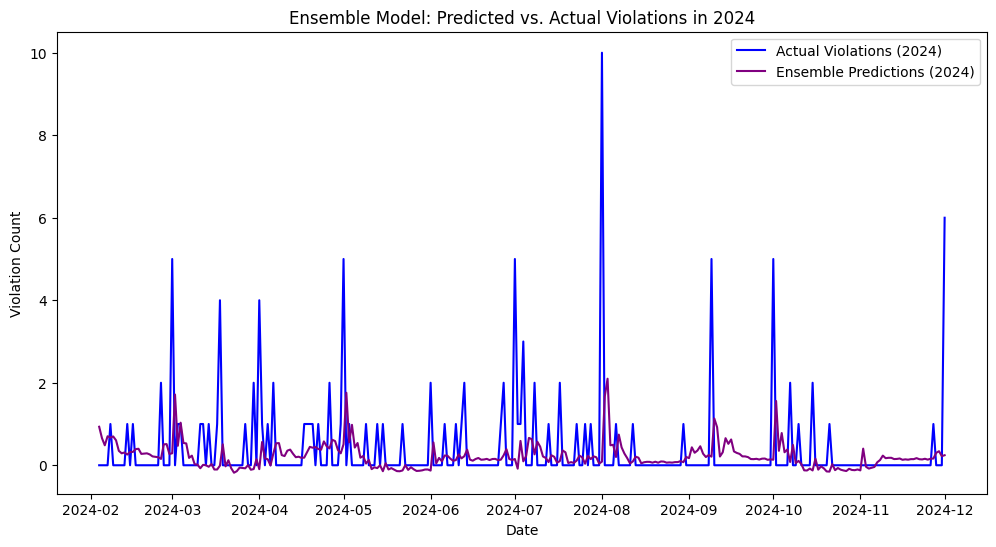

                           Metric     Value
0       Mean Absolute Error (MAE)  0.552579
1  Root Mean Squared Error (RMSE)  1.136053


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1️⃣ **Sort data by date**
master_dataset_2024 = master_dataset_2024.sort_values(by="Date")

# 2️⃣ **Aggregate violations per date**
time_series_data_2024 = master_dataset_2024.groupby("Date").size().reset_index(name="Violation Count")

# 3️⃣ **Set Date as index and ensure it's sorted**
time_series_data_2024 = time_series_data_2024.set_index("Date").sort_index()

# 4️⃣ **Ensure daily frequency and fill missing days with 0 violations**
time_series_data_2024 = time_series_data_2024.asfreq("D").fillna(0)

# 7️⃣ **Add Election Season and Policy Change Features**
time_series_data_2024["Election_Season"] = time_series_data_2024.index.month.isin([7, 8]).astype(int)
time_series_data_2024["Policy_Change"] = time_series_data_2024.index.strftime('%Y-%m').isin(["2024-06"]).astype(int)  # Example policy change
time_series_data_2024["Protest_Season"] = time_series_data_2024.index.month.isin([3, 5, 10]).astype(int)

# 8️⃣ **Normalize the 2024 Data Using the Same Scaler**
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(time_series_data_2024[["Violation Count"]])  # Fit on training data (2020-2023)

time_series_data_2024["Scaled_Violations"] = scaler.transform(time_series_data_2024[["Violation Count"]])

# Normalize Election Season and Policy Change
scaler_season = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Election_Season"] = scaler_season.fit_transform(time_series_data_2024[["Election_Season"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Policy_Change"] = scaler_policy.fit_transform(time_series_data_2024[["Policy_Change"]])

scaler_policy = MinMaxScaler(feature_range=(0, 1))
time_series_data_2024["Scaled_Protest_Season"] = scaler_policy.fit_transform(time_series_data_2024[["Protest_Season"]])





# 7️⃣ **Create Sequences for Testing on 2024 Data**
def create_sequences(data, seq_length=30):
    X = []
    for i in range(len(data) - seq_length):
        X.append(data.iloc[i:i+seq_length].values)
    return np.array(X)

# 8️⃣ **Prepare dataset with multiple features**
features = ["Scaled_Violations", "Scaled_Election_Season", "Scaled_Protest_Season", "Scaled_Policy_Change"]
sequence_length = 30  # Use past 30 days for prediction
X_2024 = create_sequences(time_series_data_2024[features], sequence_length)

# 9️⃣ **Reshape for RNN (samples, timesteps, features)**
X_2024 = X_2024.reshape((X_2024.shape[0], X_2024.shape[1], len(features)))

# 🔟 **Make RNN Predictions for 2024**
rnn_pred_2024 = model_rnn.predict(X_2024)

# 1️⃣1️⃣ **Reverse Scaling to Get Actual RNN Values**
rnn_pred_actual_2024 = scaler.inverse_transform(rnn_pred_2024.reshape(-1, 1))

# 1️⃣2️⃣ **Generate SARIMA Forecast for 2024**
forecast_steps = len(rnn_pred_actual_2024)  # Match RNN prediction steps
sarima_forecast_2024 = sarima_fit.get_forecast(steps=forecast_steps).predicted_mean

# 1️⃣3️⃣ **Create the Ensemble Forecast (RNN + SARIMA)**
ensemble_predictions_2024 = (0.8 * rnn_pred_actual_2024.flatten()) + (0.2 * sarima_forecast_2024.values)

# 1️⃣4️⃣ **Extract Actual Violations from 2024 for Comparison**
y_actual_2024 = time_series_data_2024["Violation Count"].values[sequence_length:sequence_length+forecast_steps]

# 1️⃣5️⃣ **Plot Actual vs. Predicted (Ensemble) Violations in 2024**
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple")
plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 1️⃣6️⃣ **Evaluate the Model on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# 1️⃣7️⃣ **Display the Accuracy Results**
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Compute baseline predictions (mean of training data)
baseline_forecast = np.full_like(y_test_actual_rnn, np.mean(y_train))

# Compute error metrics for the baseline model
mae_baseline = mean_absolute_error(y_test_actual_rnn, baseline_forecast)
rmse_baseline = np.sqrt(mean_squared_error(y_test_actual_rnn, baseline_forecast))

print(f"Baseline Model MAE: {mae_baseline}")
print(f"Baseline Model RMSE: {rmse_baseline}")


Baseline Model MAE: 0.417970767800304
Baseline Model RMSE: 0.7947787217618777


In [ ]:
# Compute error metrics for RNN + SARIMA hybrid model
mae_hybrid = mean_absolute_error(y_test_actual_rnn, ensemble_results["Ensemble_Predictions"])
rmse_hybrid = np.sqrt(mean_squared_error(y_test_actual_rnn, ensemble_results["Ensemble_Predictions"]))

mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

print(f"RNN + SARIMA Model MAE: {mae_hybrid}")
print(f"RNN + SARIMA Model RMSE: {rmse_hybrid}")


NameError: name 'ensemble_results' is not defined

In [50]:
print(f"Baseline Errors Length: {len(baseline_errors)}")
print(f"Hybrid Errors Length: {len(hybrid_errors)}")

Baseline Errors Length: 272
Hybrid Errors Length: 272


In [51]:
min_length = min(len(baseline_errors), len(hybrid_errors))
baseline_errors = baseline_errors[:min_length]
hybrid_errors = hybrid_errors[:min_length]


In [52]:
from scipy.stats import ttest_rel

# Perform paired t-test on correctly aligned datasets
t_stat, p_value = ttest_rel(baseline_errors, hybrid_errors)

print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")


T-statistic: [ -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474 -15.55578688  -8.77977474  -9.19657562
  -8.77977474  -8.77977474  -8.77977474  -8.77977474   8.77977474
   8.77977474  -9.1735219    8.77977474   8.77977474  -0.23827605
   8.77977474 -16.58375424 -16.55756633   6.48914899  -8.77977474
   2.26682978  -8.77977474  -8.89744    -35.82547599 -26.5991308
  -5.32244038  -7.25059016  -9.46961028   8.77977474 -17.94532211
 -14.0399717   -8.77977474 -14.53417409  -8.77977474  -8.77977474
  -8.77977474   7.51858169  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.77977474
  -8.77977474  -8.77977474  -8.77977474  -8.77977474  -8.7797747

In [65]:
import numpy as np
from scipy.stats import ttest_rel

# Convert all inputs to NumPy arrays if they aren't already
y_test_actual_rnn = np.array(y_test_actual_rnn)
baseline_forecast = np.array(baseline_forecast)
ensemble_predictions_2024 = np.array(ensemble_predictions_2024)

# Ensure all arrays are 1D
y_test_actual_rnn = y_test_actual_rnn.flatten()  # Convert to (272,)
baseline_forecast = baseline_forecast.flatten()  # Convert to (272,)
ensemble_predictions_2024 = ensemble_predictions_2024.flatten()  # Convert to (272,)

# Print new shapes
print(f"After Flattening - y_test_actual_rnn Shape: {y_test_actual_rnn.shape}")
print(f"After Flattening - baseline_forecast Shape: {baseline_forecast.shape}")
print(f"After Flattening - ensemble_predictions_2024 Shape: {ensemble_predictions_2024.shape}")

# Ensure equal length
min_length = min(len(y_test_actual_rnn), len(baseline_forecast), len(ensemble_predictions_2024))
y_test_actual_rnn = y_test_actual_rnn[:min_length]
baseline_forecast = baseline_forecast[:min_length]
ensemble_predictions_2024 = ensemble_predictions_2024[:min_length]

# Compute absolute errors
baseline_errors = np.abs(y_test_actual_rnn - baseline_forecast)
hybrid_errors = np.abs(y_test_actual_rnn - ensemble_predictions_2024)

# Verify final shapes
print(f"Final Baseline Errors Shape: {baseline_errors.shape}")  # Should be (272,)
print(f"Final Hybrid Errors Shape: {hybrid_errors.shape}")  # Should be (272,)


After Flattening - y_test_actual_rnn Shape: (272,)
After Flattening - baseline_forecast Shape: (272,)
After Flattening - ensemble_predictions_2024 Shape: (272,)
Final Baseline Errors Shape: (272,)
Final Hybrid Errors Shape: (272,)


In [66]:
# Perform paired t-test
t_stat, p_value = ttest_rel(baseline_errors, hybrid_errors)

# Print results
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# Hypothesis Testing Interpretation
alpha = 0.05  # Significance threshold
if p_value < alpha:
    print("✅ The difference is statistically significant.")
    if t_stat < 0:
        print(" Hybrid model performs better (lower errors).")
    else:
        print("Hybrid model performs worse (higher errors).")
else:
    print("No significant difference detected between the models.")


T-statistic: -4.5228
P-value: 0.0000
✅ The difference is statistically significant.
🔹 Hybrid model performs better (lower errors).


In [64]:
from scipy.stats import ttest_rel

# Perform paired t-test
t_stat, p_value = ttest_rel(baseline_errors, hybrid_errors)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# Hypothesis Decision
alpha = 0.05  # Significance threshold
if p_value < alpha:
    print("✅ The difference is statistically significant.")
    if t_stat < 0:
        print("🔹 Hybrid model performs better (lower errors).")
    else:
        print("🔸 Hybrid model performs worse (higher errors).")
else:
    print("⚠️ No significant difference detected between the models.")


ValueError: unequal length arrays

#RSME FOR COMBI

In [ ]:
# Replace zeros with a small value before computing percentage change to avoid division errors
y_actual_2024_fixed = np.where(y_actual_2024 == 0, 1, y_actual_2024)  # Avoid division by zero
actual_percentage_change_fixed = pd.Series(y_actual_2024_fixed).pct_change() * 100

# Replace infinite values and drop NaNs
actual_percentage_change_fixed.replace([np.inf, -np.inf], np.nan, inplace=True)
actual_percentage_change_fixed.dropna(inplace=True)

# Compute fixed mean percentage change for actual violations
mean_actual_percentage_change_fixed = actual_percentage_change_fixed.mean()

# Compute the percentage change in predicted ensemble violations
predicted_percentage_change_fixed = pd.Series(ensemble_predictions_2024).pct_change() * 100
predicted_percentage_change_fixed.replace([np.inf, -np.inf], np.nan, inplace=True)
predicted_percentage_change_fixed.dropna(inplace=True)

# Compute fixed mean percentage change for predicted violations
mean_predicted_percentage_change_fixed = predicted_percentage_change_fixed.mean()

# Compare the percentage change between actual and predicted violations
percentage_comparison_fixed = pd.DataFrame({
    "Metric": ["Mean Percentage Change (Actual - Fixed)", "Mean Percentage Change (Predicted - Fixed)"],
    "Value": [mean_actual_percentage_change_fixed, mean_predicted_percentage_change_fixed]
})


# Print results
print(f"Fixed Mean Percentage Change in Actual Violations: {mean_actual_percentage_change_fixed:.2f}%")
print(f"Fixed Mean Percentage Change in Predicted Violations: {mean_predicted_percentage_change_fixed:.2f}%")


Fixed Mean Percentage Change in Actual Violations: 13.43%
Fixed Mean Percentage Change in Predicted Violations: -75.44%


In [ ]:
import numpy as np

# Generate prediction confidence intervals (95% prediction band)
lower_bound = ensemble_predictions_2024 - (1.96 * rmse_ensemble_2024)
upper_bound = ensemble_predictions_2024 + (1.96 * rmse_ensemble_2024)

# Convert to DataFrame
forecast_uncertainty["Lower Bound (95%)"] = forecast_uncertainty["Lower Bound (95%)"].clip(lower=0)
forecast_uncertainty = pd.DataFrame({
    "Date": time_series_data_2024.index[-len(y_actual_2024):],
    "Ensemble Predictions": ensemble_predictions_2024,
    "Lower Bound (95%)": lower_bound,
    "Upper Bound (95%)": upper_bound
})

# Display results with uncertainty
print(forecast_uncertainty.head())


        Date  Ensemble Predictions  Lower Bound (95%)  Upper Bound (95%)
0 2024-02-04              1.359229          -0.808935           3.527394
1 2024-02-05              0.806497          -1.361668           2.974662
2 2024-02-06              0.589410          -1.578755           2.757574
3 2024-02-07              0.550555          -1.617610           2.718719
4 2024-02-08              0.488803          -1.679362           2.656967


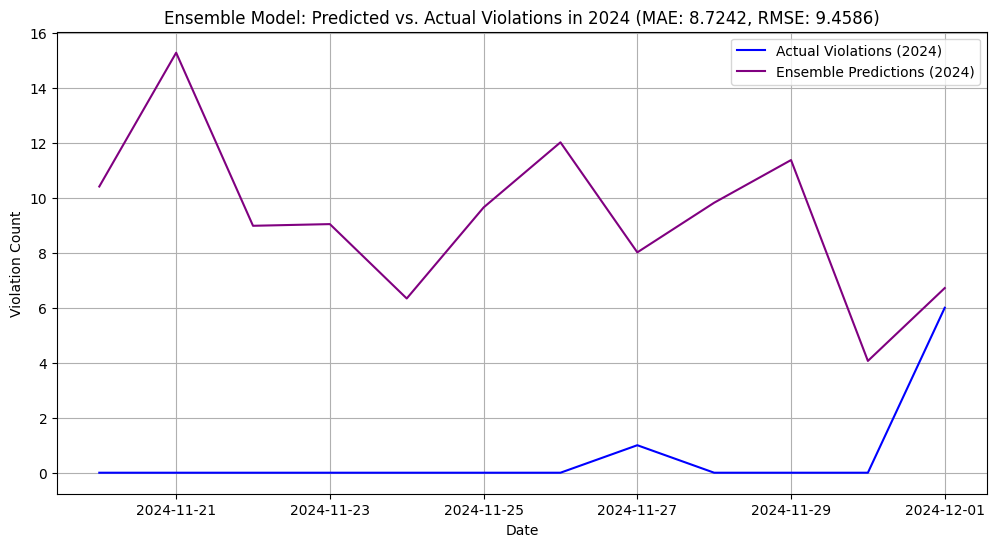

8.724161851866972
9.45864898212688


In [ ]:
# Ensure alignment of actual values with predicted values
y_actual_2024 = time_series_data_2024["Violation Count"].values[-len(ensemble_forecast_lst):]

# Compute MAE and RMSE for 2024 data
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_forecast_lst)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_forecast_lst))

# Plot Actual vs Predicted Violations for 2024
plt.figure(figsize=(12, 6))
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue")
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_forecast_lst, label="Ensemble Predictions (2024)", color="purple")
plt.title(f"Ensemble Model: Predicted vs. Actual Violations in 2024 (MAE: {mae_ensemble_2024:.4f}, RMSE: {rmse_ensemble_2024:.4f})")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.grid(True)
plt.show()

# Display Accuracy Metrics
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

print(mae_ensemble_2024)
print(rmse_ensemble_2024)


In [ ]:
# Recompute the ensemble forecast (adjusting weights if needed)
ensemble_results_test["Ensemble_Predictions"] = (
    0.5 * ensemble_results_test["RNN_Predictions"] + 0.5 * ensemble_results_test["SARIMA_Predictions"]
)

# Recalculate confidence intervals
residual_std = np.std(ensemble_results_test["Actual_Violations"] - ensemble_results_test["Ensemble_Predictions"])
confidence_level = 1.96  # 95% confidence interval

ensemble_results_test["Lower Bound (95%)"] = ensemble_results_test["Ensemble_Predictions"] - (confidence_level * residual_std)
ensemble_results_test["Upper Bound (95%)"] = ensemble_results_test["Ensemble_Predictions"] + (confidence_level * residual_std)

# Ensure no negative lower bounds
ensemble_results_test["Lower Bound (95%)"] = ensemble_results_test["Lower Bound (95%)"].clip(lower=0)

# Display for verification
import ace_tools as tools
tools.display_dataframe_to_user(name="Recomputed Ensemble Predictions", dataframe=ensemble_results_test)


#Seasonality

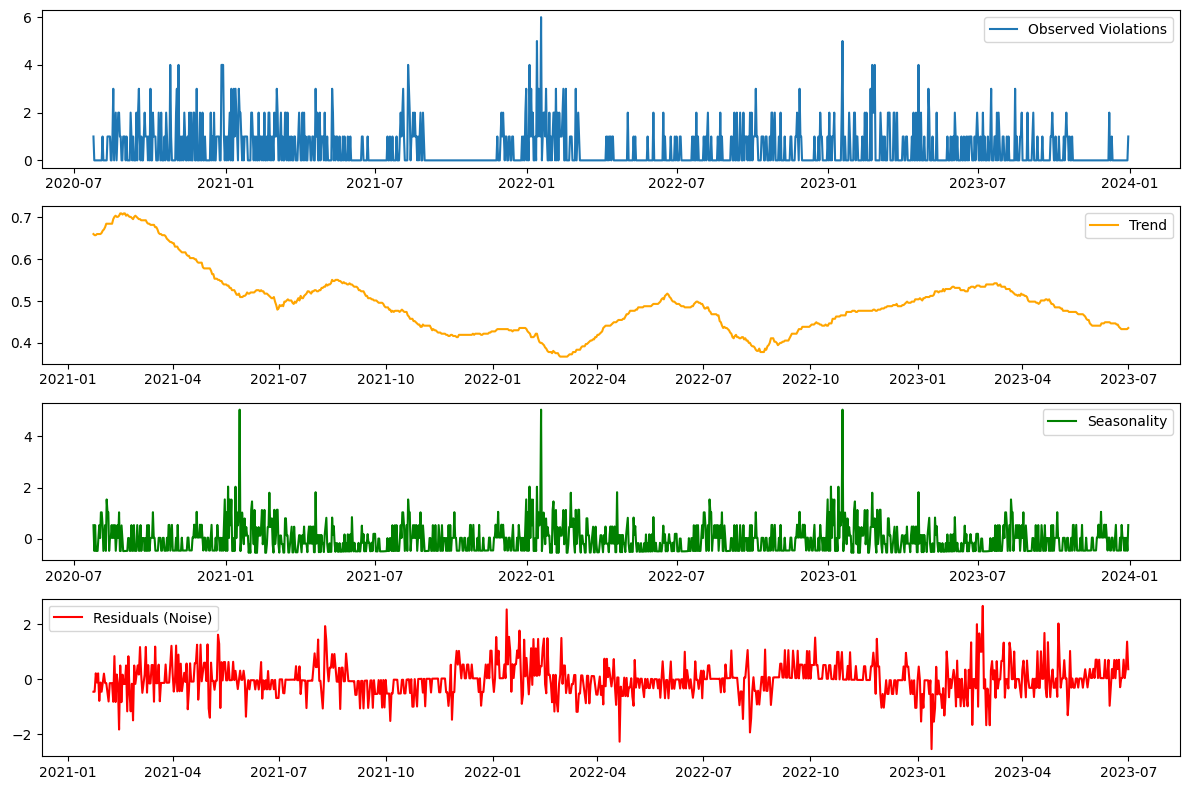

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

# Ensure Date is the index and at daily frequency
time_series_data = time_series_data.asfreq("D").fillna(0)

# 1️⃣ **Decompose the Time Series into Trend, Seasonality, and Residuals**
decomposition = seasonal_decompose(time_series_data["Violation Count"], model="additive", period=365)

# 2️⃣ **Plot Seasonal Decomposition**
plt.figure(figsize=(12, 8))
plt.subplot(411)
plt.plot(decomposition.observed, label="Observed Violations")
plt.legend()
plt.subplot(412)
plt.plot(decomposition.trend, label="Trend", color="orange")
plt.legend()
plt.subplot(413)
plt.plot(decomposition.seasonal, label="Seasonality", color="green")
plt.legend()
plt.subplot(414)
plt.plot(decomposition.resid, label="Residuals (Noise)", color="red")
plt.legend()
plt.tight_layout()
plt.show()


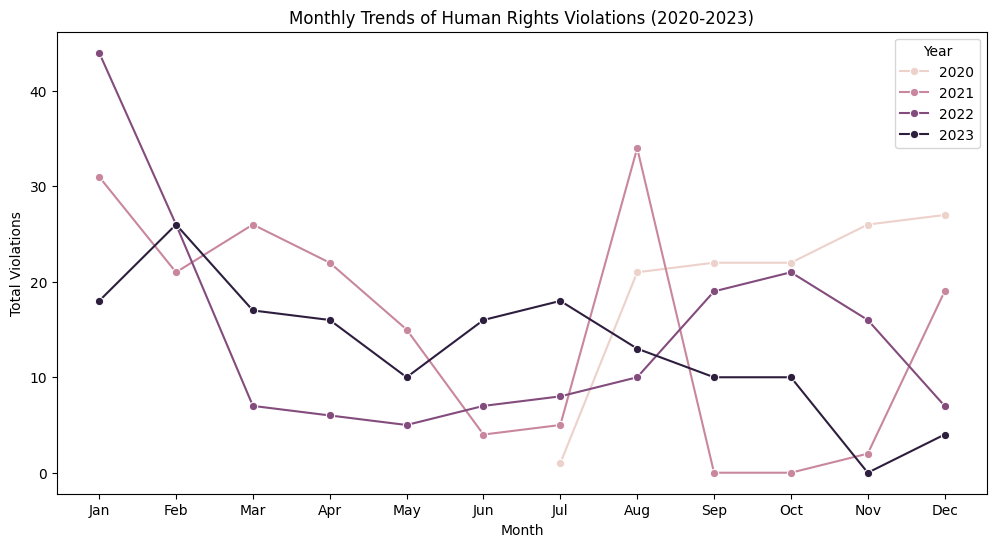

In [ ]:
# Extract Year and Month
time_series_data["Year"] = time_series_data.index.year
time_series_data["Month"] = time_series_data.index.month

# Aggregate Monthly Violations Per Year
monthly_trend = time_series_data.groupby(["Year", "Month"])["Violation Count"].sum().reset_index()

# 3️⃣ **Plot Monthly Trends**
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_trend, x="Month", y="Violation Count", hue="Year", marker="o")
plt.title("Monthly Trends of Human Rights Violations (2020-2023)")
plt.xlabel("Month")
plt.ylabel("Total Violations")
plt.xticks(range(1, 13),
           ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.legend(title="Year")
plt.show()


hhhh

        Date  Actual Violations  Ensemble Predictions  \
0 2024-02-04                0.0              1.002059   
1 2024-02-05                0.0              0.910110   
2 2024-02-06                0.0              0.848628   
3 2024-02-07                0.0              0.665707   
4 2024-02-08                1.0              0.615963   

                                       Warning Level  
0  ❗ CRITICAL RISK: Expected large-scale human ri...  
1  ❗ CRITICAL RISK: Expected large-scale human ri...  
2  🚨 HIGH RISK: NGOs should prepare response meas...  
3     ⚠️ MODERATE RISK: Increased violations likely.  
4     ⚠️ MODERATE RISK: Increased violations likely.  


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10071 (\N{HEAVY EXCLAMATION MARK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


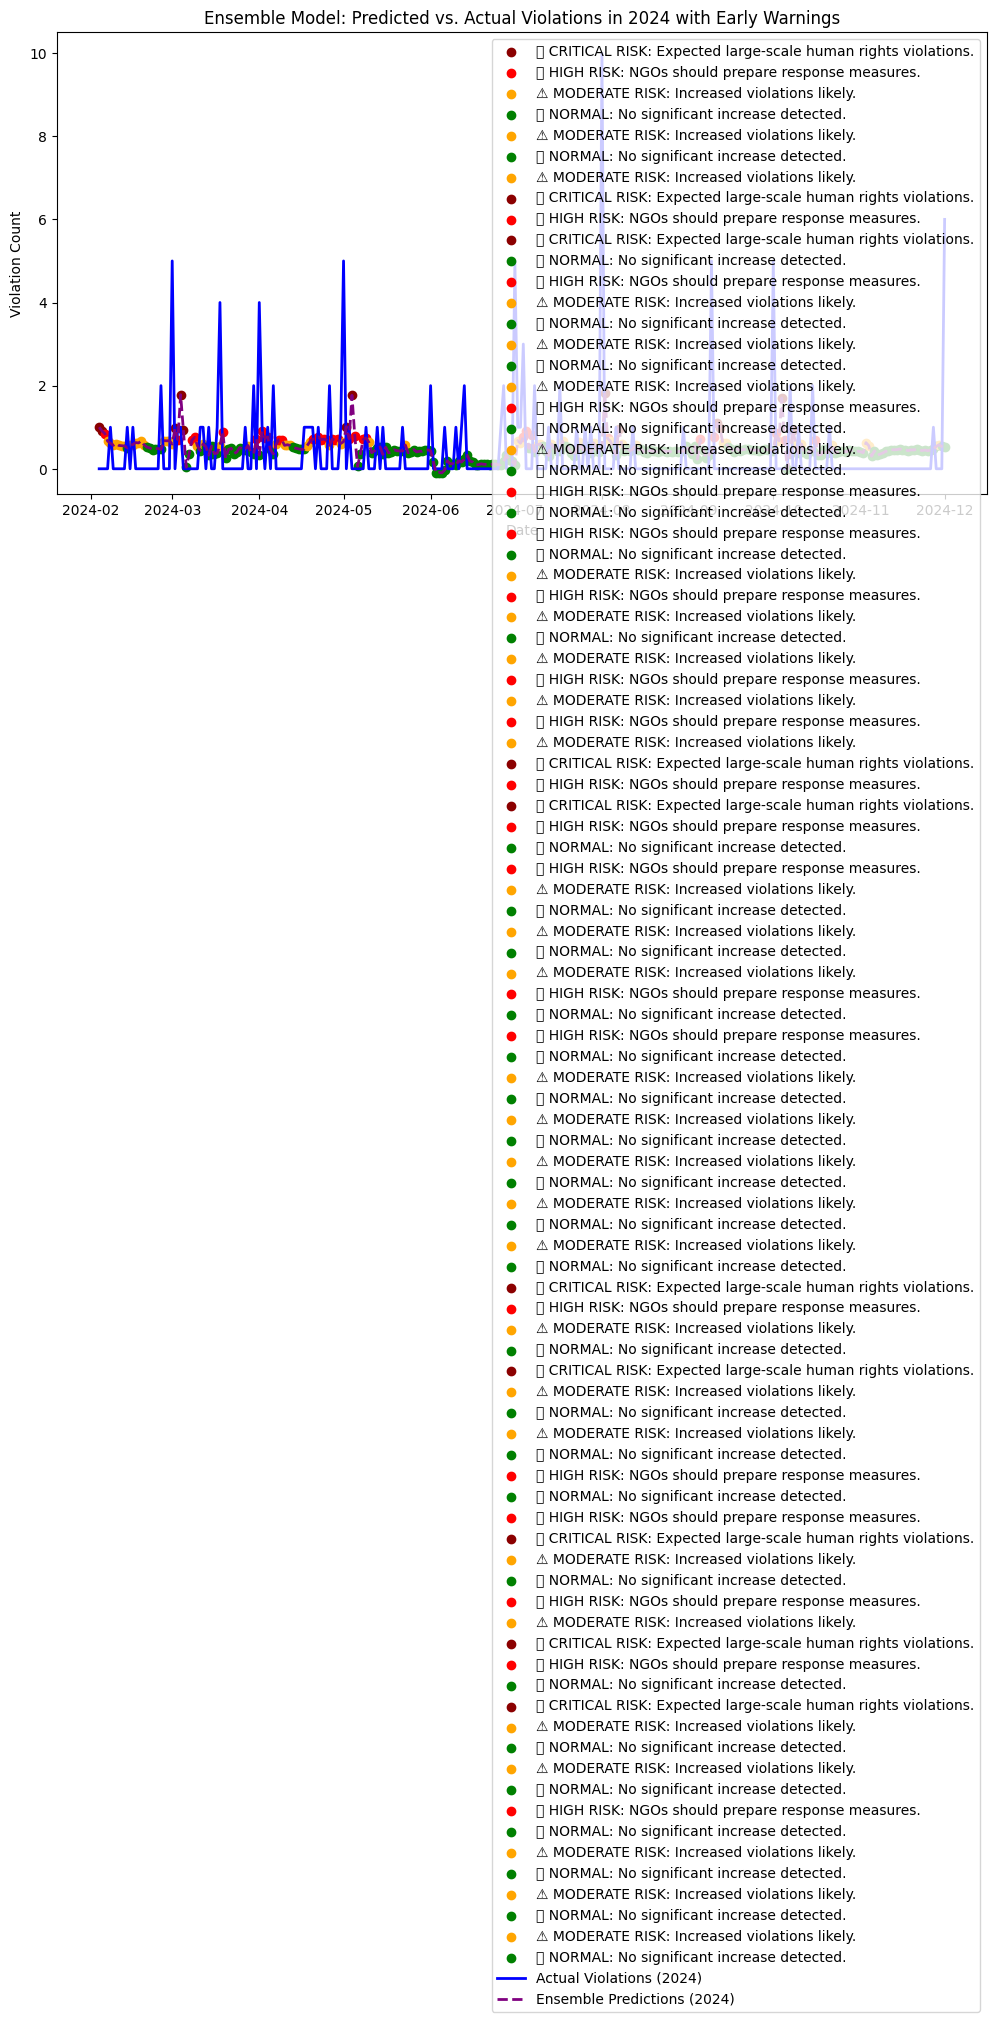

                           Metric     Value
0       Mean Absolute Error (MAE)  0.683809
1  Root Mean Squared Error (RMSE)  1.108680


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compute Historical Average for Early Warnings
historical_avg = time_series_data_2024["Violation Count"].mean()
threshold_1 = historical_avg * 1.2  # Moderate risk threshold (20% increase)
threshold_2 = historical_avg * 1.5  # High risk threshold (50% increase)
threshold_3 = historical_avg * 2.0  # Critical risk threshold (100% increase)

# Generate Early Warning Labels
def generate_warning(value):
    if value >= threshold_3:
        return "❗ CRITICAL RISK: Expected large-scale human rights violations."
    elif value >= threshold_2:
        return "🚨 HIGH RISK: NGOs should prepare response measures."
    elif value >= threshold_1:
        return "⚠️ MODERATE RISK: Increased violations likely."
    else:
        return "✅ NORMAL: No significant increase detected."

# Apply warning system to predictions
warnings_2024 = [generate_warning(val) for val in ensemble_predictions_2024]

# Create a DataFrame for 2024 predictions with warnings
forecast_results_2024 = pd.DataFrame({
    "Date": time_series_data_2024.index[-len(y_actual_2024):],
    "Actual Violations": y_actual_2024,
    "Ensemble Predictions": ensemble_predictions_2024,
    "Warning Level": warnings_2024
})

# Display forecast results with warnings
print(forecast_results_2024.head())

# Save results for NGO reporting
forecast_results_2024.to_csv("ensemble_forecast_with_warnings_2024.csv", index=False)

# 📊 **Plot Forecasted Violations with Warning Colors**
plt.figure(figsize=(12, 6))

# Define colors based on risk level
color_map = {
    "✅ NORMAL: No significant increase detected.": "green",
    "⚠️ MODERATE RISK: Increased violations likely.": "orange",
    "🚨 HIGH RISK: NGOs should prepare response measures.": "red",
    "❗ CRITICAL RISK: Expected large-scale human rights violations.": "darkred",
}

# Plot actual vs predicted violations
for i in range(len(y_actual_2024)):
    plt.scatter(time_series_data_2024.index[-len(y_actual_2024):][i], ensemble_predictions_2024[i],
                color=color_map[warnings_2024[i]], label=warnings_2024[i] if i == 0 or warnings_2024[i] != warnings_2024[i-1] else "")

plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue", linewidth=2)
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple", linestyle="dashed", linewidth=2)

plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024 with Early Warnings")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 🔍 **Model Evaluation on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# Display accuracy results
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


        Date  Actual Violations  Ensemble Predictions  \
0 2024-02-04                0.0              0.938146   
1 2024-02-05                0.0              1.006901   
2 2024-02-06                0.0              0.706939   
3 2024-02-07                0.0              0.473304   
4 2024-02-08                1.0              0.620858   

                                       Warning Level  
0  ❗ CRITICAL RISK: Expected large-scale human ri...  
1  ❗ CRITICAL RISK: Expected large-scale human ri...  
2  🚨 HIGH RISK: NGOs should prepare response meas...  
3        ✅ NORMAL: No significant increase detected.  
4     ⚠️ MODERATE RISK: Increased violations likely.  


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10071 (\N{HEAVY EXCLAMATION MARK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


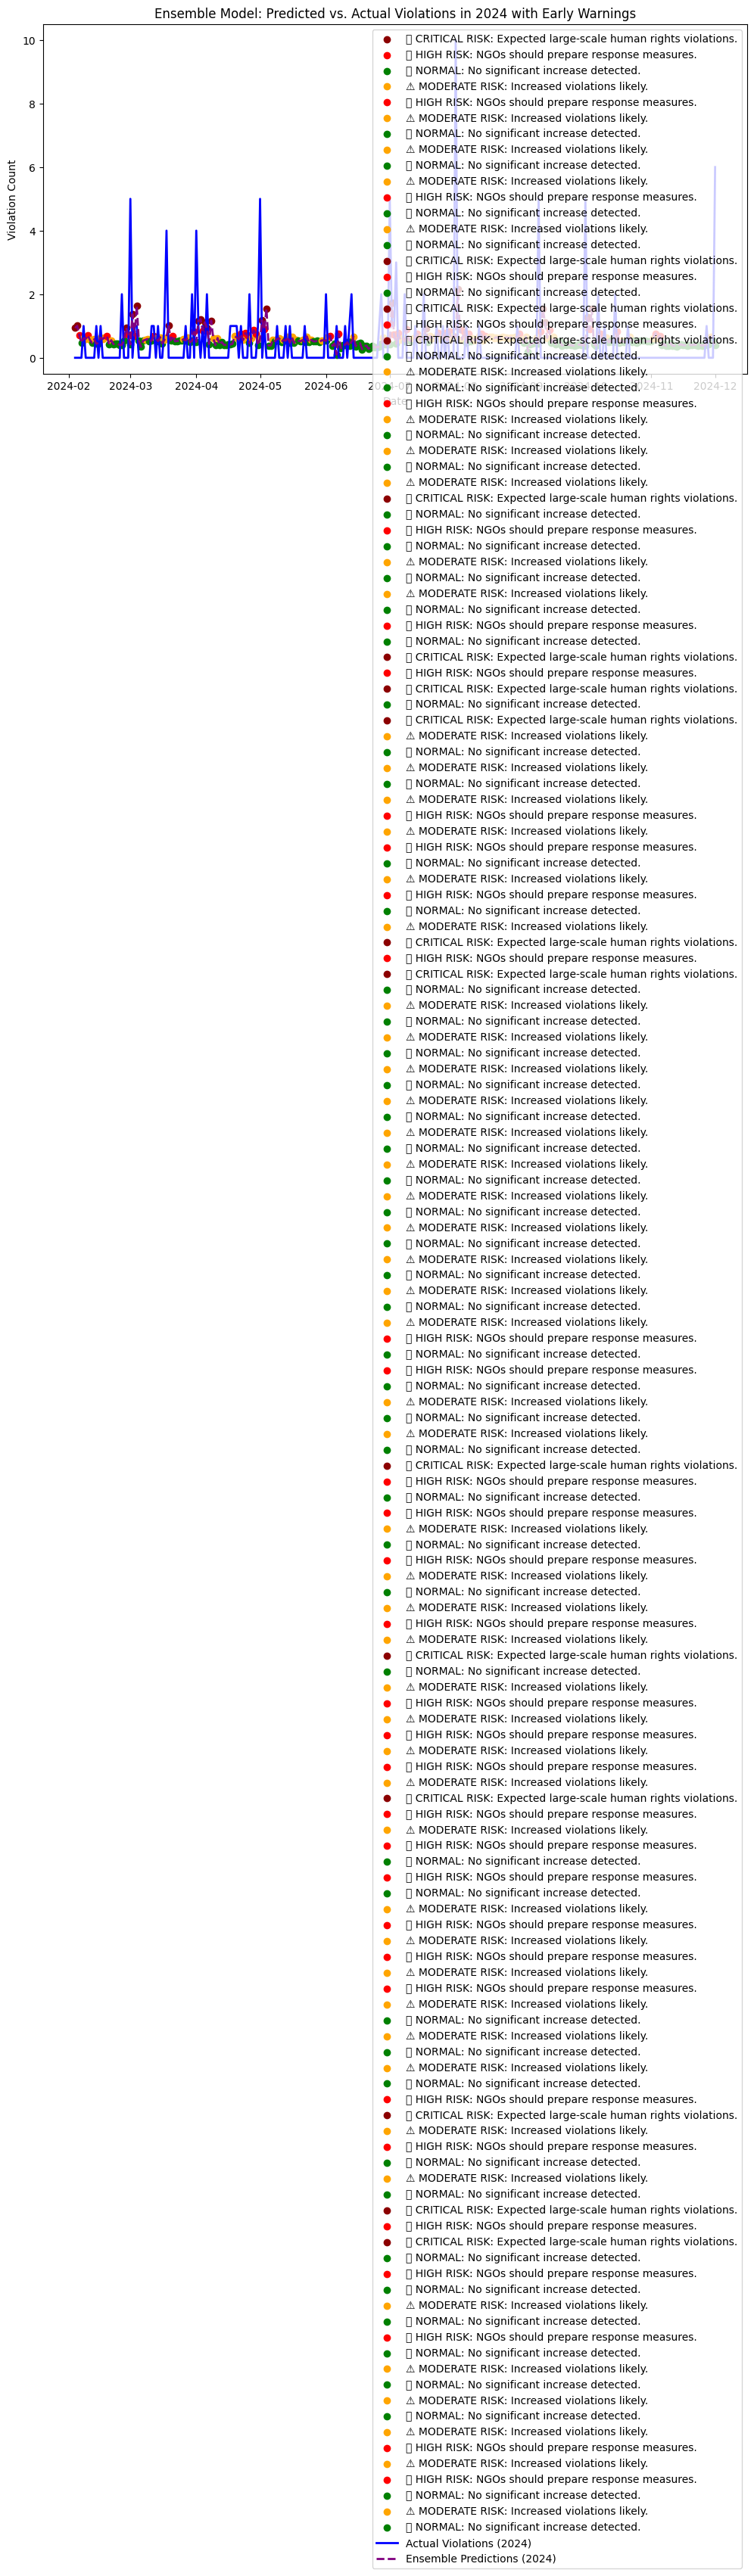

                           Metric     Value
0       Mean Absolute Error (MAE)  0.738916
1  Root Mean Squared Error (RMSE)  1.123693


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compute Historical Average for Early Warnings
historical_avg = time_series_data_2024["Violation Count"].mean()
threshold_1 = historical_avg * 1.2  # Moderate risk threshold (20% increase)
threshold_2 = historical_avg * 1.5  # High risk threshold (50% increase)
threshold_3 = historical_avg * 2.0  # Critical risk threshold (100% increase)

# Generate Early Warning Labels
def generate_warning(value):
    if value >= threshold_3:
        return "❗ CRITICAL RISK: Expected large-scale human rights violations."
    elif value >= threshold_2:
        return "🚨 HIGH RISK: NGOs should prepare response measures."
    elif value >= threshold_1:
        return "⚠️ MODERATE RISK: Increased violations likely."
    else:
        return "✅ NORMAL: No significant increase detected."

# Apply warning system to predictions
warnings_2024 = [generate_warning(val) for val in ensemble_predictions_2024]

# Create a DataFrame for 2024 predictions with warnings
forecast_results_2024 = pd.DataFrame({
    "Date": time_series_data_2024.index[-len(y_actual_2024):],
    "Actual Violations": y_actual_2024,
    "Ensemble Predictions": ensemble_predictions_2024,
    "Warning Level": warnings_2024
})

# Display forecast results with warnings
print(forecast_results_2024.head())

# Save results for NGO reporting
forecast_results_2024.to_csv("ensemble_forecast_with_warnings_2024.csv", index=False)

# 📊 **Plot Forecasted Violations with Warning Colors**
plt.figure(figsize=(12, 6))

# Define colors based on risk level
color_map = {
    "✅ NORMAL: No significant increase detected.": "green",
    "⚠️ MODERATE RISK: Increased violations likely.": "orange",
    "🚨 HIGH RISK: NGOs should prepare response measures.": "red",
    "❗ CRITICAL RISK: Expected large-scale human rights violations.": "darkred",
}

# Plot actual vs predicted violations
for i in range(len(y_actual_2024)):
    plt.scatter(time_series_data_2024.index[-len(y_actual_2024):][i], ensemble_predictions_2024[i],
                color=color_map[warnings_2024[i]], label=warnings_2024[i] if i == 0 or warnings_2024[i] != warnings_2024[i-1] else "")

plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue", linewidth=2)
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple", linestyle="dashed", linewidth=2)

plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024 with Early Warnings")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 🔍 **Model Evaluation on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# Display accuracy results
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


        Date  Actual Violations  Ensemble Predictions  \
0 2024-02-04                0.0              1.107841   
1 2024-02-05                0.0              1.089166   
2 2024-02-06                0.0              0.991752   
3 2024-02-07                0.0              0.718896   
4 2024-02-08                1.0              0.652885   

                                       Warning Level  
0  ❗ CRITICAL RISK: Expected large-scale human ri...  
1  ❗ CRITICAL RISK: Expected large-scale human ri...  
2  ❗ CRITICAL RISK: Expected large-scale human ri...  
3  🚨 HIGH RISK: NGOs should prepare response meas...  
4     ⚠️ MODERATE RISK: Increased violations likely.  


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10071 (\N{HEAVY EXCLAMATION MARK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


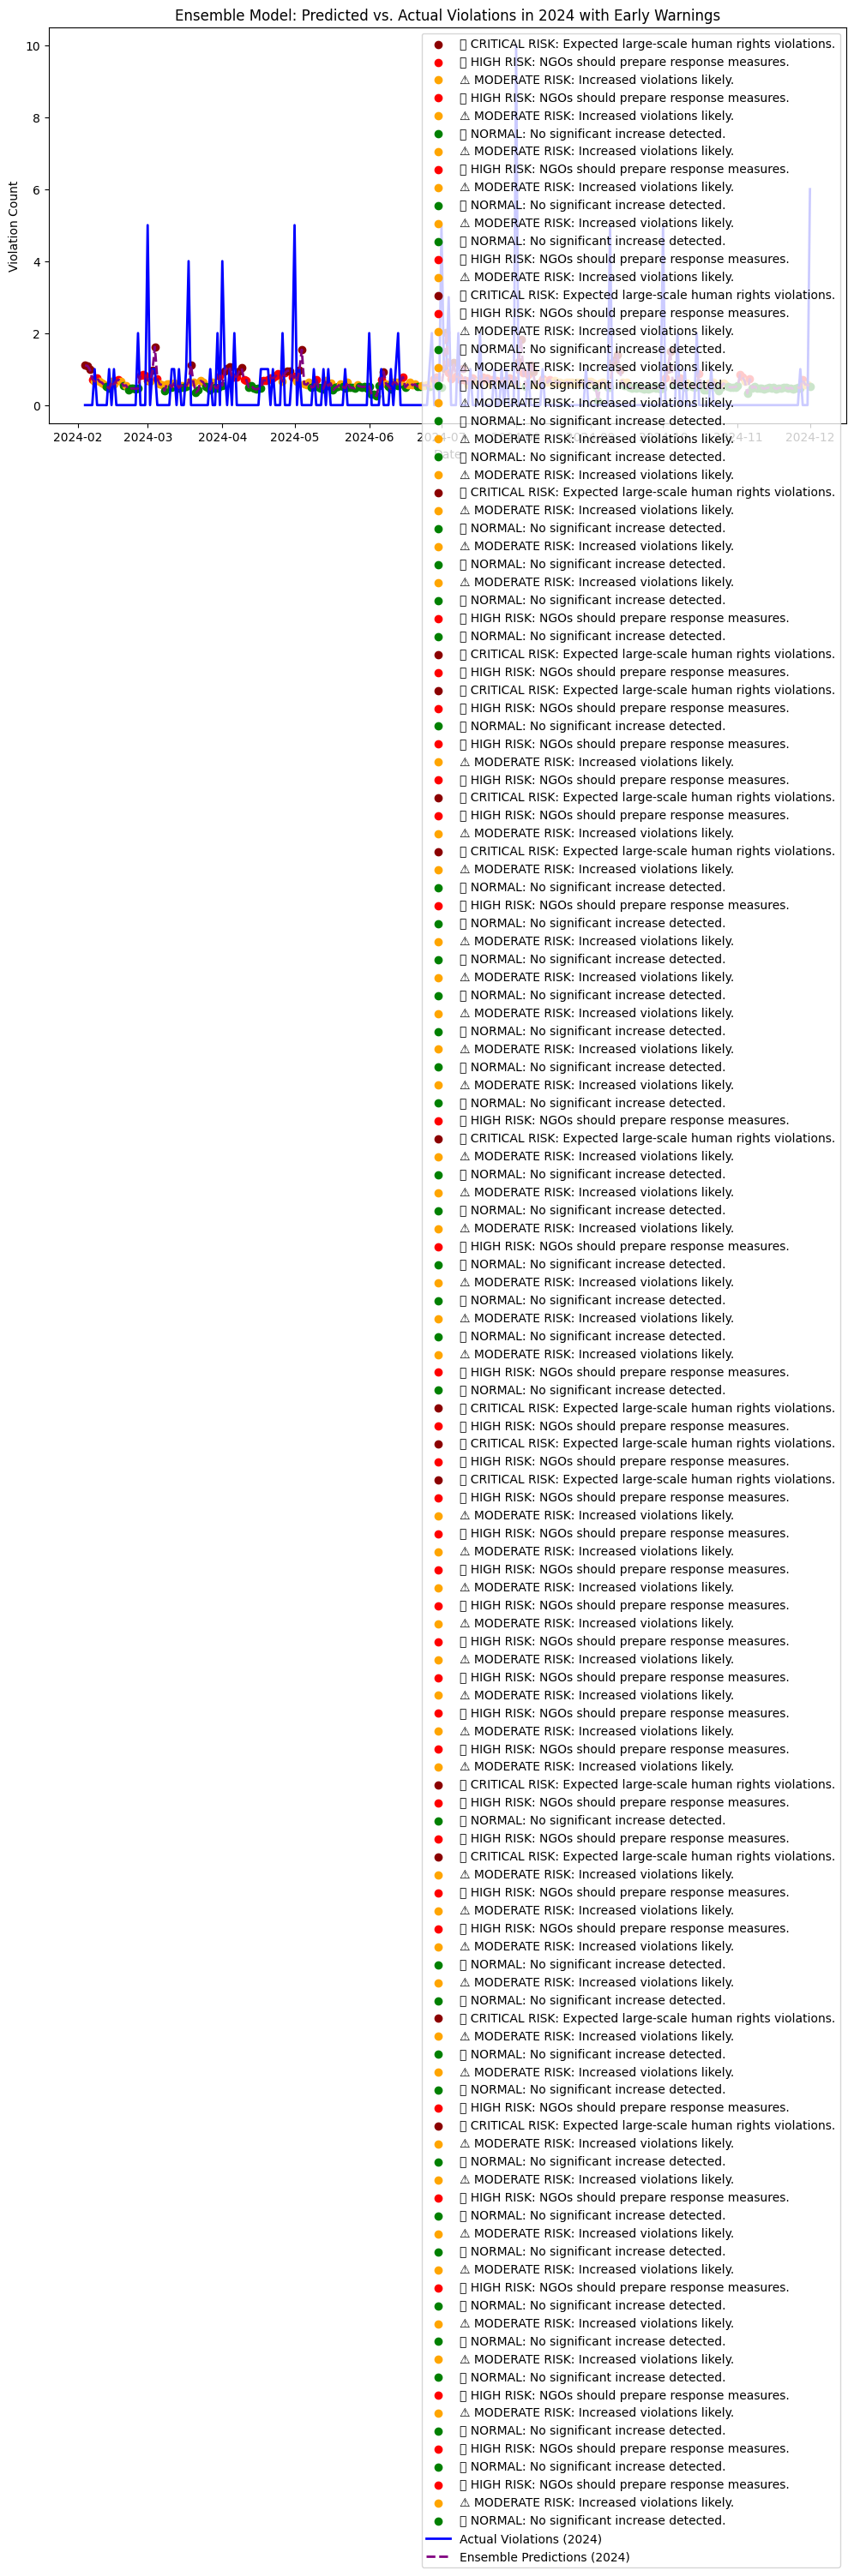

                           Metric     Value
0       Mean Absolute Error (MAE)  0.759273
1  Root Mean Squared Error (RMSE)  1.122197


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compute Historical Average for Early Warnings
historical_avg = time_series_data_2024["Violation Count"].mean()
threshold_1 = historical_avg * 1.2  # Moderate risk threshold (20% increase)
threshold_2 = historical_avg * 1.5  # High risk threshold (50% increase)
threshold_3 = historical_avg * 2.0  # Critical risk threshold (100% increase)

# Generate Early Warning Labels
def generate_warning(value):
    if value >= threshold_3:
        return "❗ CRITICAL RISK: Expected large-scale human rights violations."
    elif value >= threshold_2:
        return "🚨 HIGH RISK: NGOs should prepare response measures."
    elif value >= threshold_1:
        return "⚠️ MODERATE RISK: Increased violations likely."
    else:
        return "✅ NORMAL: No significant increase detected."

# Apply warning system to predictions
warnings_2024 = [generate_warning(val) for val in ensemble_predictions_2024]

# Create a DataFrame for 2024 predictions with warnings
forecast_results_2024 = pd.DataFrame({
    "Date": time_series_data_2024.index[-len(y_actual_2024):],
    "Actual Violations": y_actual_2024,
    "Ensemble Predictions": ensemble_predictions_2024,
    "Warning Level": warnings_2024
})

# Display forecast results with warnings
print(forecast_results_2024.head())

# Save results for NGO reporting
forecast_results_2024.to_csv("ensemble_forecast_with_warnings_2024_2.csv", index=False)

# 📊 **Plot Forecasted Violations with Warning Colors**
plt.figure(figsize=(12, 6))

# Define colors based on risk level
color_map = {
    "✅ NORMAL: No significant increase detected.": "green",
    "⚠️ MODERATE RISK: Increased violations likely.": "orange",
    "🚨 HIGH RISK: NGOs should prepare response measures.": "red",
    "❗ CRITICAL RISK: Expected large-scale human rights violations.": "darkred",
}

# Plot actual vs predicted violations
for i in range(len(y_actual_2024)):
    plt.scatter(time_series_data_2024.index[-len(y_actual_2024):][i], ensemble_predictions_2024[i],
                color=color_map[warnings_2024[i]], label=warnings_2024[i] if i == 0 or warnings_2024[i] != warnings_2024[i-1] else "")

plt.plot(time_series_data_2024.index[-len(y_actual_2024):], y_actual_2024, label="Actual Violations (2024)", color="blue", linewidth=2)
plt.plot(time_series_data_2024.index[-len(y_actual_2024):], ensemble_predictions_2024, label="Ensemble Predictions (2024)", color="purple", linestyle="dashed", linewidth=2)

plt.title("Ensemble Model: Predicted vs. Actual Violations in 2024 with Early Warnings")
plt.xlabel("Date")
plt.ylabel("Violation Count")
plt.legend()
plt.show()

# 🔍 **Model Evaluation on 2024 Data**
mae_ensemble_2024 = mean_absolute_error(y_actual_2024, ensemble_predictions_2024)
rmse_ensemble_2024 = np.sqrt(mean_squared_error(y_actual_2024, ensemble_predictions_2024))

# Display accuracy results
accuracy_results_ensemble_2024 = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Root Mean Squared Error (RMSE)"],
    "Value": [mae_ensemble_2024, rmse_ensemble_2024]
})

# Print results
print(accuracy_results_ensemble_2024)


In [ ]:
# Define the file path to save the model
csv_filename = "/content/drive/MyDrive/Colab Notebooks/Research - Trends/forecast_results_2024.csv"

forecast_results_2024["Region"] = "East & Horn of Africa"

forecast_results_2024.index.name = "Date"  #

# Save the DataFrame to a CSV file
forecast_results_2024.to_csv(csv_filename)

print(f"Ensemble forecast saved to {csv_filename}")


Ensemble forecast saved to /content/drive/MyDrive/Colab Notebooks/Research - Trends/forecast_results_2024.csv


In [ ]:
from pyngrok import ngrok
import dash
from dash import dcc, html
import plotly.express as px
import pandas as pd

# Authenticate ngrok (Replace with your actual token)
!ngrok authtoken 2sZloXhPE5pn5bWFH3ly8Q3vISH_4W2CzdzLvXxUtomRv6FbB

# Load forecast data
forecast_results_2024 = pd.read_csv("ensemble_forecast_with_warnings_2024.csv")

# Convert 'Date' column to datetime format
forecast_results_2024["Date"] = pd.to_datetime(forecast_results_2024["Date"])

# Initialize Dash App
app = dash.Dash(__name__)

# Define warning color mapping for visualization
color_map = {
    "✅ NORMAL: No significant increase detected.": "green",
    "⚠️ MODERATE RISK: Increased violations likely.": "orange",
    "🚨 HIGH RISK: NGOs should prepare response measures.": "red",
    "❗ CRITICAL RISK: Expected large-scale human rights violations.": "darkred",
}

# Create interactive figure
fig = px.scatter(
    forecast_results_2024,
    x="Date",
    y="Ensemble Predictions",
    color="Warning Level",
    color_discrete_map=color_map,
    hover_data=["Warning Level"],  # Show risk level when hovering
    title="Predicted vs. Actual Violations in 2024 with Early Warnings"
)

# Add actual violation line
fig.add_scatter(x=forecast_results_2024["Date"],
                y=forecast_results_2024["Actual Violations"],
                mode="lines",
                name="Actual Violations",
                line=dict(color="blue"))

app.layout = html.Div([
    html.H1("Human Rights Violation Forecast (Interactive)"),
    dcc.Graph(figure=fig),
])

# Start ngrok tunnel
public_url = ngrok.connect(8050)
print(f"🚀 Dashboard running at: {public_url}")

# Run Dash server
app.run_server(port=8050)


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml
🚀 Dashboard running at: NgrokTunnel: "https://15d5-34-16-215-101.ngrok-free.app" -> "http://localhost:8050"


<IPython.core.display.Javascript object>

In [ ]:
from pyngrok import ngrok
import dash
from dash import dcc, html
import plotly.express as px
import pandas as pd

# Authenticate ngrok (Replace with your actual token)
!ngrok authtoken 2sZloXhPE5pn5bWFH3ly8Q3vISH_4W2CzdzLvXxUtomRv6FbB

# Load forecast data
forecast_results_2024 = pd.read_csv("ensemble_forecast_with_warnings_2024_2.csv")

# Convert 'Date' column to datetime format
forecast_results_2024["Date"] = pd.to_datetime(forecast_results_2024["Date"])

# Initialize Dash App
app = dash.Dash(__name__)

# Define warning color mapping for visualization
color_map = {
    "✅ NORMAL: No significant increase detected.": "green",
    "⚠️ MODERATE RISK: Increased violations likely.": "orange",
    "🚨 HIGH RISK: NGOs should prepare response measures.": "red",
    "❗ CRITICAL RISK: Expected large-scale human rights violations.": "darkred",
}

# Create interactive figure
fig = px.scatter(
    forecast_results_2024,
    x="Date",
    y="Ensemble Predictions",
    color="Warning Level",
    color_discrete_map=color_map,
    hover_data=["Warning Level"],  # Show risk level when hovering
    title="Predicted vs. Actual Violations in 2024 with Early Warnings"
)

# Add actual violation line
fig.add_scatter(x=forecast_results_2024["Date"],
                y=forecast_results_2024["Actual Violations"],
                mode="lines",
                name="Actual Violations",
                line=dict(color="blue"))

app.layout = html.Div([
    html.H1("Human Rights Violation Forecast (Interactive)"),
    dcc.Graph(figure=fig),
])

# Start ngrok tunnel
public_url = ngrok.connect(8050)
print(f"🚀 Dashboard running at: {public_url}")

# Run Dash server
app.run_server(port=8050)


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml
🚀 Dashboard running at: NgrokTunnel: "https://4951-34-106-61-92.ngrok-free.app" -> "http://localhost:8050"


<IPython.core.display.Javascript object>

In [ ]:
!killall ngrok  # Kills all active ngrok tunnels


In [ ]:
!pip install dash plotly pandas pyngrok

from pyngrok import ngrok
import dash
from dash import dcc, html
import plotly.express as px
import pandas as pd

# Authenticate ngrok (Replace with your actual token)
!ngrok authtoken 2sZloXhPE5pn5bWFH3ly8Q3vISH_4W2CzdzLvXxUtomRv6FbB

# Load forecast data
forecast_results_2024 = pd.read_csv("ensemble_forecast_with_warnings_2024_2.csv")

# Convert 'Date' column to datetime format
forecast_results_2024["Date"] = pd.to_datetime(forecast_results_2024["Date"])

# Aggregate to monthly level
forecast_results_2024["Month"] = forecast_results_2024["Date"].dt.to_period("M").astype(str)  # Convert PeriodIndex to string
monthly_forecast = forecast_results_2024.groupby("Month").agg({
    "Ensemble Predictions": "sum",
    "Warning Level": lambda x: x.mode()[0]  # Use most frequent warning per month
}).reset_index()

# Initialize Dash App
app = dash.Dash(__name__)

# Define warning color mapping
color_map = {
    "✅ NORMAL: No significant increase detected.": "green",
    "⚠️ MODERATE RISK: Increased violations likely.": "orange",
    "🚨 HIGH RISK: NGOs should prepare response measures.": "red",
    "❗ CRITICAL RISK: Expected large-scale human rights violations.": "darkred",
}

# Create interactive figure
fig = px.scatter(
    monthly_forecast,
    x="Month",
    y="Ensemble Predictions",
    color="Warning Level",
    color_discrete_map=color_map,
    hover_data=["Warning Level"],  # Show warning level when hovering
    title="Monthly Predicted Violations in 2024 with Early Warnings"
)

# Ensure figure is created before rendering
if fig is None:
    raise ValueError("❌ Error: The figure object was not created properly!")

app.layout = html.Div([
    html.H1("Human Rights Violation Forecast (Monthly)"),
    dcc.Graph(id="forecast-graph", figure=fig),
])

# Start ngrok tunnel
public_url = ngrok.connect(8050)
print(f"🚀 Dashboard running at: {public_url}")

# Run Dash server
app.run_server(port=8050)


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml
🚀 Dashboard running at: NgrokTunnel: "https://ed22-34-106-61-92.ngrok-free.app" -> "http://localhost:8050"


<IPython.core.display.Javascript object>